In [ ]:

from google.colab import drive
import numpy as np
import os

drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/MODIS_2021_Weekly_Averages.npz"

assert os.path.exists(file_path), "Original 2021 file not found."

data = np.load(file_path)

print("Available keys:", data.files)

aod_original = data["aod"]
lat_original = data["lat"]
lon_original = data["lon"]

print("\n--- 2021 ORIGINAL DATA ---")
print("AOD shape:", aod_original.shape)
print("Latitude shape:", lat_original.shape)
print("Longitude shape:", lon_original.shape)
print("Latitude range:", np.min(lat_original), np.max(lat_original))
print("Longitude range:", np.min(lon_original), np.max(lon_original))
print("Observed values:", np.isfinite(aod_original).sum())
print("Missing values:", np.isnan(aod_original).sum())
print("Missing percentage:",
      100 * np.isnan(aod_original).sum() / aod_original.size)

print("\nDate information available:",
      [key for key in data.files if "date" in key.lower()
       or "time" in key.lower() or "week" in key.lower()])


Mounted at /content/drive
Available keys: ['aod', 'lat', 'lon']

--- 2021 ORIGINAL DATA ---
AOD shape: (52, 867, 1008)
Latitude shape: (867,)
Longitude shape: (1008,)
Latitude range: 12.9 36.28199999999935
Longitude range: 65.1 92.28900000000102
Observed values: 14646572
Missing values: 30798100
Missing percentage: 67.77054084580035

Date information available: []


In [ ]:
from pathlib import Path
import shutil

base = Path("/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021")

shutil.make_archive(
    "/content/2021_Research_Figures",
    "zip",
    base,
    "."
)

print("ZIP created successfully")

ZIP created successfully


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

import numpy as np
import warnings

FACTOR = 2

nt, ny, nx = aod_original.shape

# Trim dimensions to multiples of 2
ny_trim = (ny // FACTOR) * FACTOR
nx_trim = (nx // FACTOR) * FACTOR

aod_trim = aod_original[:, :ny_trim, :nx_trim]
lat_trim = lat_original[:ny_trim]
lon_trim = lon_original[:nx_trim]

# Aggregate original observations using available values
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)

    aod_aggregated = np.nanmean(
        aod_trim.reshape(
            nt,
            ny_trim // FACTOR, FACTOR,
            nx_trim // FACTOR, FACTOR
        ),
        axis=(2, 4)
    )

lat_aggregated = lat_trim.reshape(-1, FACTOR).mean(axis=1)
lon_aggregated = lon_trim.reshape(-1, FACTOR).mean(axis=1)

# Crop to study domain
lat_select = (lat_aggregated >= 18) & (lat_aggregated <= 35)
lon_select = (lon_aggregated >= 73) & (lon_aggregated <= 90)

aod_2021_crop = aod_aggregated[:, lat_select, :][:, :, lon_select]
lat_2021 = lat_aggregated[lat_select]
lon_2021 = lon_aggregated[lon_select]

print("--- TASK 1: 2021 STUDY DOMAIN ---")
print("Shape:", aod_2021_crop.shape)
print("Latitude:", lat_2021.min(), "to", lat_2021.max())
print("Longitude:", lon_2021.min(), "to", lon_2021.max())

print("\nObserved values:", np.isfinite(aod_2021_crop).sum())
print("Missing values:", np.isnan(aod_2021_crop).sum())
print("Missing percentage:",
      100 * np.isnan(aod_2021_crop).sum() / aod_2021_crop.size)

assert aod_2021_crop.shape == (52, 315, 314)

print("\nSTEP 2 PASSED")


--- TASK 1: 2021 STUDY DOMAIN ---
Shape: (52, 315, 314)
Latitude: 18.04349999999986 to 34.99949999999939
Longitude: 73.05150000000029 to 89.95350000000093

Observed values: 2548712
Missing values: 2594608
Missing percentage: 50.446170955725094

STEP 2 PASSED


In [ ]:

import numpy as np
import os

final_path = (
    "/content/drive/MyDrive/"
    "DINEOF_2021_REVISED_BBOX_LANDMASK/"
    "MODIS_2021_DINEOF_Revised_Final.npz"
)

assert os.path.exists(final_path), "Saved DINEOF file not found."

with np.load(final_path) as saved:
    print("Available keys:", saved.files)

    land_mask_2021 = saved["land_mask"].astype(bool)
    coverage_mask_2021 = saved["coverage_mask"].astype(bool)
    final_mask_2021 = saved["final_domain_mask"].astype(bool)

    saved_lat = saved["lat"]
    saved_lon = saved["lon"]

# Check alignment with the original cropped data
assert land_mask_2021.shape == aod_2021_crop.shape[1:]
assert coverage_mask_2021.shape == land_mask_2021.shape
assert final_mask_2021.shape == land_mask_2021.shape

assert np.allclose(saved_lat, lat_2021)
assert np.allclose(saved_lon, lon_2021)

# Independently calculate the temporal coverage criterion
missing_fraction_2021 = np.mean(
    ~np.isfinite(aod_2021_crop),
    axis=0
)

calculated_coverage = missing_fraction_2021 <= 0.40

assert np.array_equal(
    coverage_mask_2021[land_mask_2021],
    calculated_coverage[land_mask_2021]
), "Coverage mask does not match the original observations."

assert np.array_equal(
    final_mask_2021,
    land_mask_2021 & coverage_mask_2021
), "Final mask is inconsistent."

# Count observations and gaps in the retained domain
observed_retained = np.count_nonzero(
    np.isfinite(aod_2021_crop) & final_mask_2021[None, :, :]
)

missing_retained = np.count_nonzero(
    ~np.isfinite(aod_2021_crop) & final_mask_2021[None, :, :]
)

print("\n--- MASK VERIFICATION ---")
print("Land pixels:", np.count_nonzero(land_mask_2021))
print("Retained land pixels:", np.count_nonzero(final_mask_2021))
print("Observed retained values:", observed_retained)
print("Missing retained values:", missing_retained)
print("Retained-domain missingness (%):",
      round(100 * missing_retained /
            (observed_retained + missing_retained), 4))

print("\nSTEP 3 PASSED")


Available keys: ['aod', 'aod_dineof_raw', 'lat', 'lon', 'land_mask', 'coverage_mask', 'final_domain_mask', 'dineof_rank', 'spatial_lambda', 'temporal_missing_threshold', 'aggregation_factor', 'bbox', 'description']

--- MASK VERIFICATION ---
Land pixels: 93484
Retained land pixels: 55918
Observed retained values: 2142906
Missing retained values: 764830
Retained-domain missingness (%): 26.3033

STEP 3 PASSED


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

# Output folder
output_dir = Path(
    "/content/drive/MyDrive/"
    "MODIS_AOD_Research_2021_2025/2021"
)
output_dir.mkdir(parents=True, exist_ok=True)

# Original observations within retained land domain
observed = np.isfinite(aod_2021_crop)
domain = final_mask_2021

n_pixels = int(domain.sum())
n_weeks = aod_2021_crop.shape[0]

weekly_rows = []

for t in range(n_weeks):
    values = aod_2021_crop[t][domain]
    valid = values[np.isfinite(values)]

    weekly_rows.append({
        "Week": t + 1,
        "Retained_Pixels": n_pixels,
        "Observed_Pixels": len(valid),
        "Missing_Pixels": n_pixels - len(valid),
        "Observed_Percent": 100 * len(valid) / n_pixels,
        "Missing_Percent": 100 * (n_pixels - len(valid)) / n_pixels,
        "Mean_AOD": np.mean(valid) if len(valid) else np.nan,
        "Median_AOD": np.median(valid) if len(valid) else np.nan,
        "Std_AOD": np.std(valid) if len(valid) else np.nan
    })

weekly_df = pd.DataFrame(weekly_rows)

# Annual summary based on all available observations
retained_values = aod_2021_crop[:, domain]
valid_annual = retained_values[np.isfinite(retained_values)]

annual_df = pd.DataFrame([{
    "Year": 2021,
    "Weekly_Layers": n_weeks,
    "Land_Pixels": int(land_mask_2021.sum()),
    "Retained_Land_Pixels": n_pixels,
    "Total_Retained_Cells": retained_values.size,
    "Observed_Cells": len(valid_annual),
    "Missing_Cells": retained_values.size - len(valid_annual),
    "Observed_Percent": 100 * len(valid_annual) / retained_values.size,
    "Missing_Percent": 100 * (
        retained_values.size - len(valid_annual)
    ) / retained_values.size,
    "Mean_Observed_AOD": np.mean(valid_annual),
    "Median_Observed_AOD": np.median(valid_annual),
    "Std_Observed_AOD": np.std(valid_annual),
    "Min_Observed_AOD": np.min(valid_annual),
    "Max_Observed_AOD": np.max(valid_annual)
}])

weekly_file = output_dir / "2021_Task1_Weekly_EDA.csv"
annual_file = output_dir / "2021_Task1_Annual_EDA.csv"

weekly_df.to_csv(weekly_file, index=False)
annual_df.to_csv(annual_file, index=False)

print("=== 2021 ANNUAL EDA ===")
print(annual_df.to_string(index=False))

print("\n=== WEEKLY MISSINGNESS ===")
print(
    weekly_df[
        ["Week", "Observed_Pixels", "Missing_Percent"]
    ].to_string(index=False)
)

# Scientific consistency checks
assert len(weekly_df) == 52
assert int(annual_df["Observed_Cells"].iloc[0]) == 2142906
assert int(annual_df["Missing_Cells"].iloc[0]) == 764830

print("\nSaved:")
print(annual_file)
print(weekly_file)
print("\nSTEP 4 PASSED")


=== 2021 ANNUAL EDA ===
 Year  Weekly_Layers  Land_Pixels  Retained_Land_Pixels  Total_Retained_Cells  Observed_Cells  Missing_Cells  Observed_Percent  Missing_Percent  Mean_Observed_AOD  Median_Observed_AOD  Std_Observed_AOD  Min_Observed_AOD  Max_Observed_AOD
 2021             52        93484                 55918               2907736         2142906         764830         73.696718        26.303282           0.570944             0.517167          0.333624             -0.05             4.961

=== WEEKLY MISSINGNESS ===
 Week  Observed_Pixels  Missing_Percent
    1            52041         6.933367
    2            50016        10.554741
    3            52003         7.001323
    4            47360        15.304553
    5            54915         1.793698
    6            55490         0.765406
    7            54391         2.730784
    8            55545         0.667048
    9            55729         0.337995
   10            55468         0.804750
   11            55028         1

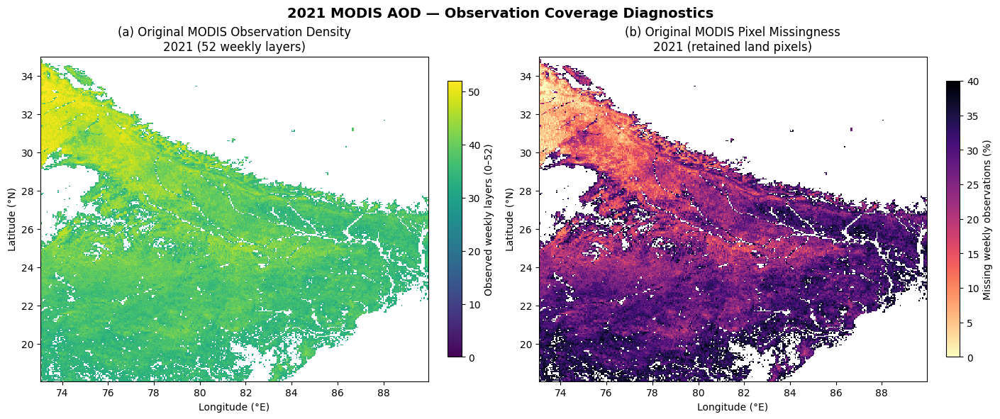

Saved figure: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task1_Observation_Density_and_Missingness.png
Minimum observation count: 32
Maximum observation count: 52
Maximum pixel missingness (%): 38.4615

STEP 5 PASSED


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# Number of valid original observations at each pixel
observation_count = np.isfinite(aod_2021_crop).sum(axis=0)

# Pixel-wise missing percentage across 52 layers
pixel_missing_pct = (
    100 * (1 - observation_count / aod_2021_crop.shape[0])
)

# Mask outside the retained land domain
density_map = np.where(
    final_mask_2021, observation_count, np.nan
)
missing_map = np.where(
    final_mask_2021, pixel_missing_pct, np.nan
)

# Verify original data and 40% criterion
assert int(observation_count[final_mask_2021].sum()) == 2142906
assert np.nanmax(missing_map) <= 40.000001
assert np.nanmin(density_map) >= 32

extent = [
    lon_2021.min(), lon_2021.max(),
    lat_2021.min(), lat_2021.max()
]

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5.8),
    constrained_layout=True
)

im1 = axes[0].imshow(
    density_map,
    origin="lower",
    extent=extent,
    cmap="viridis",
    vmin=0,
    vmax=52,
    interpolation="nearest",
    aspect="auto"
)

axes[0].set_title(
    "(a) Original MODIS Observation Density\n2021 (52 weekly layers)"
)
axes[0].set_xlabel("Longitude (°E)")
axes[0].set_ylabel("Latitude (°N)")
fig.colorbar(
    im1, ax=axes[0],
    label="Observed weekly layers (0–52)",
    shrink=0.85
)

im2 = axes[1].imshow(
    missing_map,
    origin="lower",
    extent=extent,
    cmap="magma_r",
    vmin=0,
    vmax=40,
    interpolation="nearest",
    aspect="auto"
)

axes[1].set_title(
    "(b) Original MODIS Pixel Missingness\n2021 (retained land pixels)"
)
axes[1].set_xlabel("Longitude (°E)")
axes[1].set_ylabel("Latitude (°N)")
fig.colorbar(
    im2, ax=axes[1],
    label="Missing weekly observations (%)",
    shrink=0.85
)

fig.suptitle(
    "2021 MODIS AOD — Observation Coverage Diagnostics",
    fontsize=14,
    fontweight="bold"
)

figure_path = (
    output_dir /
    "2021_Task1_Observation_Density_and_Missingness.png"
)

fig.savefig(
    figure_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved figure:", figure_path)
print("Minimum observation count:",
      int(np.nanmin(density_map)))
print("Maximum observation count:",
      int(np.nanmax(density_map)))
print("Maximum pixel missingness (%):",
      round(float(np.nanmax(missing_map)), 4))
print("\nSTEP 5 PASSED")


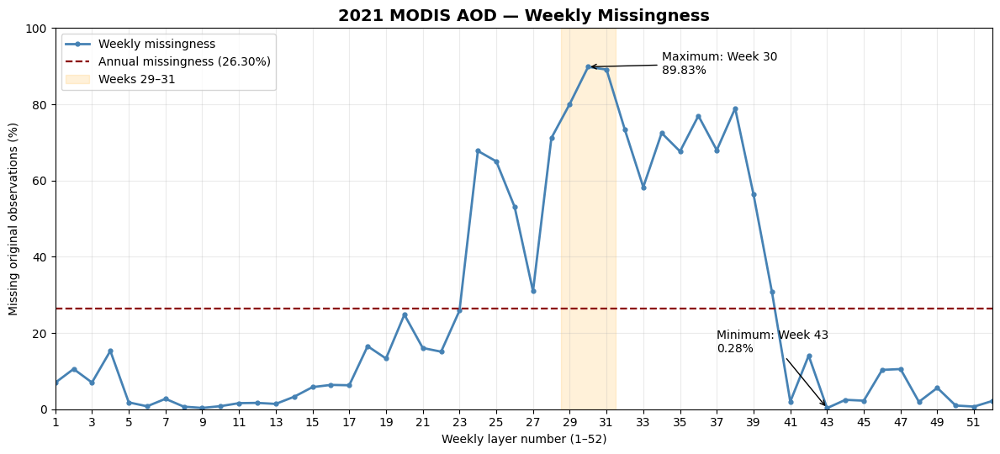

Maximum missingness: 89.8262
Minimum missingness: 0.2843
Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task1_Weekly_Missingness.png

STEP 6 PASSED


In [ ]:

import matplotlib.pyplot as plt
import numpy as np

weeks = weekly_df["Week"].to_numpy()
missing_pct = weekly_df["Missing_Percent"].to_numpy()

annual_missing = annual_df["Missing_Percent"].iloc[0]

fig, ax = plt.subplots(figsize=(12, 5.5))

ax.plot(
    weeks,
    missing_pct,
    color="steelblue",
    linewidth=2,
    marker="o",
    markersize=3.5,
    label="Weekly missingness"
)

ax.axhline(
    annual_missing,
    color="darkred",
    linestyle="--",
    linewidth=1.6,
    label=f"Annual missingness ({annual_missing:.2f}%)"
)

# Highlight previously identified stripe-prone weeks
ax.axvspan(
    28.5, 31.5,
    color="orange",
    alpha=0.15,
    label="Weeks 29–31"
)

max_idx = np.argmax(missing_pct)
min_idx = np.argmin(missing_pct)

ax.annotate(
    f"Maximum: Week {weeks[max_idx]}\n"
    f"{missing_pct[max_idx]:.2f}%",
    xy=(weeks[max_idx], missing_pct[max_idx]),
    xytext=(34, 88),
    arrowprops={"arrowstyle": "->"},
    fontsize=10
)

ax.annotate(
    f"Minimum: Week {weeks[min_idx]}\n"
    f"{missing_pct[min_idx]:.2f}%",
    xy=(weeks[min_idx], missing_pct[min_idx]),
    xytext=(37, 15),
    arrowprops={"arrowstyle": "->"},
    fontsize=10
)

ax.set_title(
    "2021 MODIS AOD — Weekly Missingness",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Weekly layer number (1–52)")
ax.set_ylabel("Missing original observations (%)")

ax.set_xlim(1, 52)
ax.set_ylim(0, 100)
ax.set_xticks(np.arange(1, 53, 2))
ax.grid(alpha=0.25)
ax.legend(loc="upper left")

fig.tight_layout()

figure_path = (
    output_dir /
    "2021_Task1_Weekly_Missingness.png"
)

fig.savefig(
    figure_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

assert len(weeks) == 52
assert weeks[max_idx] == 30
assert weeks[min_idx] == 43

print("Maximum missingness:", round(missing_pct[max_idx], 4))
print("Minimum missingness:", round(missing_pct[min_idx], 4))
print("Saved:", figure_path)
print("\nSTEP 6 PASSED")


In [ ]:

import numpy as np

with np.load(final_path) as saved:
    aod_2021_filled = saved["aod"].copy()
    aod_2021_raw_dineof = saved["aod_dineof_raw"].copy()

print("Original shape:", aod_2021_crop.shape)
print("Final reconstructed shape:", aod_2021_filled.shape)
print("Raw DINEOF shape:", aod_2021_raw_dineof.shape)

assert aod_2021_filled.shape == aod_2021_crop.shape
assert aod_2021_raw_dineof.shape == aod_2021_crop.shape

# All retained-domain cells must be reconstructed
assert np.isfinite(
    aod_2021_filled[:, final_mask_2021]
).all()

# Verify that final reconstruction preserves observed MODIS values
original_values = aod_2021_crop[:, final_mask_2021]
filled_values = aod_2021_filled[:, final_mask_2021]

observed_positions = np.isfinite(original_values)

max_observed_difference = np.max(
    np.abs(
        original_values[observed_positions]
        - filled_values[observed_positions]
    )
)

print("\nRetained original observations:",
      observed_positions.sum())

print("Maximum difference at observed locations:",
      max_observed_difference)

assert np.allclose(
    original_values[observed_positions],
    filled_values[observed_positions],
    rtol=0,
    atol=1e-6
)

print("\nSTEP 7 PASSED")


Original shape: (52, 315, 314)
Final reconstructed shape: (52, 315, 314)
Raw DINEOF shape: (52, 315, 314)

Retained original observations: 2142906
Maximum difference at observed locations: 2.3317988961935043e-07

STEP 7 PASSED


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

maps_dir = output_dir / "2021_Task1_All_52_Paired_Maps"
maps_dir.mkdir(parents=True, exist_ok=True)

# Use the same retained land domain for both maps
original_maps = np.where(
    final_mask_2021[None, :, :],
    aod_2021_crop,
    np.nan
)

filled_maps = np.where(
    final_mask_2021[None, :, :],
    aod_2021_filled,
    np.nan
)

# White indicates unavailable or excluded pixels
cmap = plt.get_cmap("turbo").copy()
cmap.set_bad("white")

extent = [
    lon_2021.min(), lon_2021.max(),
    lat_2021.min(), lat_2021.max()
]

saved_count = 0

for t in range(52):
    fig, axes = plt.subplots(
        1, 2, figsize=(12, 5),
        constrained_layout=True
    )

    for ax, image_data, title in zip(
        axes,
        [original_maps[t], filled_maps[t]],
        ["Original MODIS AOD", "DINEOF Gap-Filled AOD"]
    ):
        im = ax.imshow(
            image_data,
            origin="lower",
            extent=extent,
            cmap=cmap,
            vmin=0,
            vmax=2,
            interpolation="nearest",
            aspect="auto"
        )

        ax.set_title(title)
        ax.set_xlabel("Longitude (°E)")
        ax.set_ylabel("Latitude (°N)")

    missing_pct = weekly_df.loc[
        t, "Missing_Percent"
    ]

    fig.suptitle(
        f"2021 MODIS AOD — Week {t+1:02d} "
        f"(Original missingness: {missing_pct:.2f}%)",
        fontsize=13,
        fontweight="bold"
    )

    fig.colorbar(
        im,
        ax=axes,
        shrink=0.82,
        label="Aerosol Optical Depth (AOD)"
    )

    save_path = maps_dir / f"2021_Week_{t+1:02d}_Original_vs_DINEOF.png"

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.close(fig)
    saved_count += 1

print("Figures saved:", saved_count)
print("Folder:", maps_dir)

assert saved_count == 52
assert len(list(maps_dir.glob("2021_Week_*_Original_vs_DINEOF.png"))) == 52

print("\nSTEP 8 PASSED")


Figures saved: 52
Folder: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task1_All_52_Paired_Maps

STEP 8 PASSED


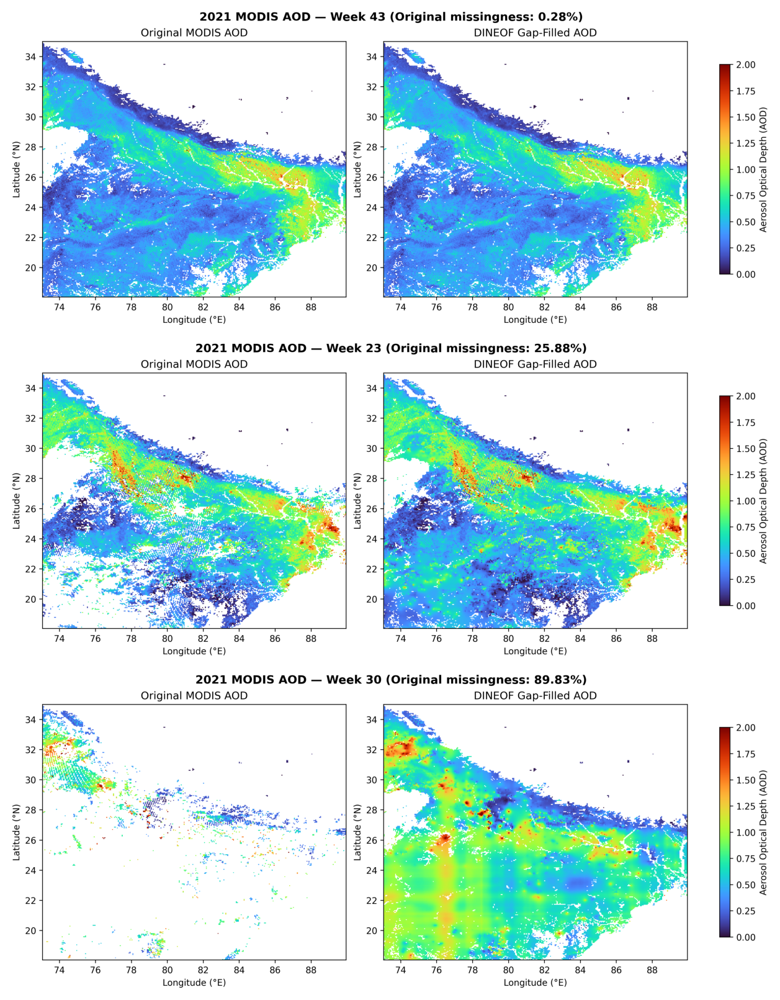

Representative figures verified:
Week 43: 0.28% missing
Week 23: 25.88% missing
Week 30: 89.83% missing

STEP 9 DISPLAY COMPLETE


In [ ]:

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

selected_weeks = [43, 23, 30]

fig, axes = plt.subplots(
    3, 1,
    figsize=(13, 16),
    constrained_layout=True
)

for ax, week in zip(axes, selected_weeks):
    file_path = (
        maps_dir /
        f"2021_Week_{week:02d}_Original_vs_DINEOF.png"
    )

    assert file_path.exists(), f"Missing figure: {file_path}"

    img = mpimg.imread(file_path)
    ax.imshow(img)
    ax.axis("off")

plt.show()

print("Representative figures verified:")
for week in selected_weeks:
    missing = weekly_df.loc[
        weekly_df["Week"] == week,
        "Missing_Percent"
    ].iloc[0]

    print(f"Week {week}: {missing:.2f}% missing")

print("\nSTEP 9 DISPLAY COMPLETE")


In [ ]:

from pathlib import Path

summary = """2021 MODIS AOD — TASK 1 EDA QUALITY-CONTROL SUMMARY

Study region: 18–35 N, 73–90 E
Spatial aggregation: 2 × 2
Temporal layers: 52 (calendar dates not verified)

Retained land pixels: 55,918
Original observed values: 2,142,906
Original missing values: 764,830
Retained-domain missingness: 26.3033%

Representative weekly layers:
Week 43: 0.2843% missing — original and filled maps nearly identical.
Week 23: 25.8772% missing — moderate reconstruction and smoothing.
Week 30: 89.8262% missing — extensive reconstruction;
          band-like spatial artifacts remain visible.

Quality-control findings:
1. Original and reconstructed grids align.
2. Original observations are preserved to numerical precision.
3. Missingness varies strongly between weekly layers.
4. High-missingness reconstructions require independent validation.
5. The final product is observation-preserving, spatially
   regularized DINEOF, not raw DINEOF alone.
6. Calendar dates are unavailable in the supplied NPZ file.
7. The retained-domain mask excludes land pixels exceeding
   40% temporal missingness.
8. White areas outside the retained domain should not be
   interpreted as missing original observations.

Task 1 outputs:
- Annual EDA CSV
- Weekly EDA CSV
- Observation-density and missingness maps
- Weekly missingness graph
- 52 paired original-versus-reconstructed weekly figures

Remaining scientific limitations:
- Verify actual calendar dates from source metadata.
- Evaluate reconstruction accuracy using independent holdouts.
- Investigate stripe artifacts and their dependence on missingness.
"""

summary_path = (
    output_dir / "2021_Task1_EDA_Quality_Control_Summary.txt"
)

summary_path.write_text(summary, encoding="utf-8")

print(summary)
print("\nSaved:", summary_path)
print("\nSTEP 10 PASSED")


2021 MODIS AOD — TASK 1 EDA QUALITY-CONTROL SUMMARY

Study region: 18–35 N, 73–90 E
Spatial aggregation: 2 × 2
Temporal layers: 52 (calendar dates not verified)

Retained land pixels: 55,918
Original observed values: 2,142,906
Original missing values: 764,830
Retained-domain missingness: 26.3033%

Representative weekly layers:
Week 43: 0.2843% missing — original and filled maps nearly identical.
Week 23: 25.8772% missing — moderate reconstruction and smoothing.
Week 30: 89.8262% missing — extensive reconstruction;
          band-like spatial artifacts remain visible.

Quality-control findings:
1. Original and reconstructed grids align.
2. Original observations are preserved to numerical precision.
3. Missingness varies strongly between weekly layers.
4. High-missingness reconstructions require independent validation.
5. The final product is observation-preserving, spatially
   regularized DINEOF, not raw DINEOF alone.
6. Calendar dates are unavailable in the supplied NPZ file.
7. The r

In [ ]:

import numpy as np

original = np.where(
    final_mask_2021[None, :, :],
    aod_2021_crop,
    np.nan
)

raw_dineof = np.where(
    final_mask_2021[None, :, :],
    aod_2021_raw_dineof,
    np.nan
)

final_dineof = np.where(
    final_mask_2021[None, :, :],
    aod_2021_filled,
    np.nan
)

observed_mask = np.isfinite(original)
gap_mask = (~np.isfinite(original)) & final_mask_2021[None, :, :]

print("Original observed cells:", observed_mask.sum())
print("Original missing cells:", gap_mask.sum())

print("Raw DINEOF finite cells:",
      np.isfinite(raw_dineof[:, final_mask_2021]).sum())

print("Final DINEOF finite cells:",
      np.isfinite(final_dineof[:, final_mask_2021]).sum())

print("Maximum final-minus-original difference at observed cells:",
      np.max(np.abs(final_dineof[observed_mask] - original[observed_mask])))

print("Maximum raw-minus-original difference at observed cells:",
      np.max(np.abs(raw_dineof[observed_mask] - original[observed_mask])))

assert observed_mask.sum() == 2142906
assert gap_mask.sum() == 764830
assert np.isfinite(final_dineof[:, final_mask_2021]).all()

print("\nTASK 2 — STEP 1 PASSED")


Original observed cells: 2142906
Original missing cells: 764830
Raw DINEOF finite cells: 2907736
Final DINEOF finite cells: 2907736
Maximum final-minus-original difference at observed cells: 2.3317988961935043e-07
Maximum raw-minus-original difference at observed cells: 2.3317988961935043e-07

TASK 2 — STEP 1 PASSED


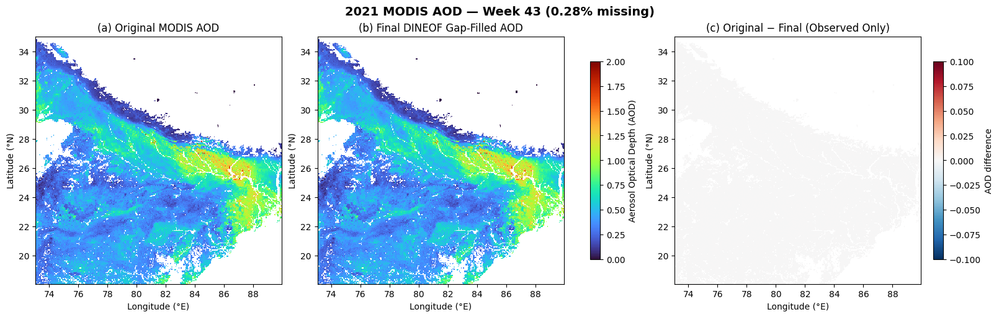

Week 43: maximum absolute observed difference = 0.000000091
Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task2_Reconstruction_Diagnostics/2021_Task2_Week_43_Three_Way_Comparison.png


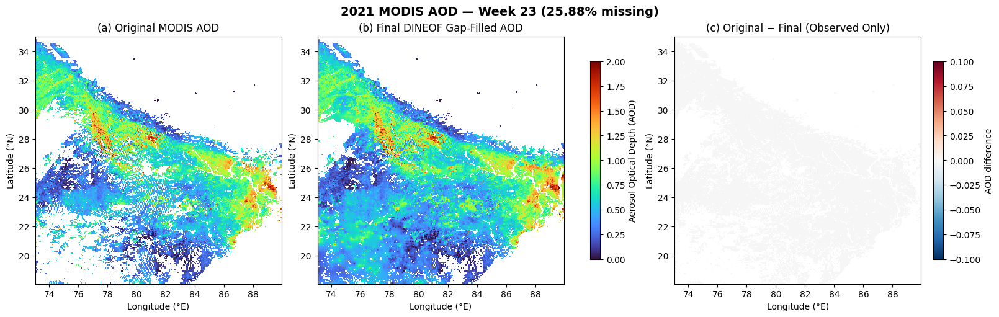

Week 23: maximum absolute observed difference = 0.000000113
Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task2_Reconstruction_Diagnostics/2021_Task2_Week_23_Three_Way_Comparison.png


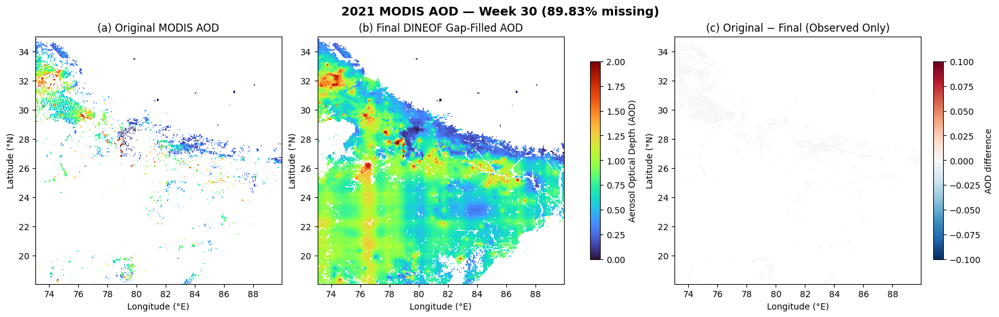

Week 30: maximum absolute observed difference = 0.000000222
Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task2_Reconstruction_Diagnostics/2021_Task2_Week_30_Three_Way_Comparison.png

TASK 2 — STEP 2 COMPLETE


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

task2_dir = output_dir / "2021_Task2_Reconstruction_Diagnostics"
task2_dir.mkdir(parents=True, exist_ok=True)

selected_weeks = [43, 23, 30]

aod_cmap = plt.get_cmap("turbo").copy()
aod_cmap.set_bad("white")

diff_cmap = plt.get_cmap("RdBu_r").copy()
diff_cmap.set_bad("white")

extent = [
    lon_2021.min(), lon_2021.max(),
    lat_2021.min(), lat_2021.max()
]

for week in selected_weeks:
    t = week - 1

    original_layer = original[t]
    reconstructed_layer = final_dineof[t]

    # Difference is defined only where original observations exist
    difference = np.where(
        np.isfinite(original_layer),
        original_layer - reconstructed_layer,
        np.nan
    )

    fig, axes = plt.subplots(
        1, 3,
        figsize=(16, 5),
        constrained_layout=True
    )

    im0 = axes[0].imshow(
        original_layer,
        origin="lower",
        extent=extent,
        cmap=aod_cmap,
        vmin=0,
        vmax=2,
        interpolation="nearest",
        aspect="auto"
    )

    im1 = axes[1].imshow(
        reconstructed_layer,
        origin="lower",
        extent=extent,
        cmap=aod_cmap,
        vmin=0,
        vmax=2,
        interpolation="nearest",
        aspect="auto"
    )

    im2 = axes[2].imshow(
        difference,
        origin="lower",
        extent=extent,
        cmap=diff_cmap,
        vmin=-0.1,
        vmax=0.1,
        interpolation="nearest",
        aspect="auto"
    )

    titles = [
        "(a) Original MODIS AOD",
        "(b) Final DINEOF Gap-Filled AOD",
        "(c) Original − Final (Observed Only)"
    ]

    for ax, title in zip(axes, titles):
        ax.set_title(title)
        ax.set_xlabel("Longitude (°E)")
        ax.set_ylabel("Latitude (°N)")

    fig.colorbar(
        im1, ax=axes[:2],
        shrink=0.8,
        label="Aerosol Optical Depth (AOD)"
    )

    fig.colorbar(
        im2, ax=axes[2],
        shrink=0.8,
        label="AOD difference"
    )

    missing_pct = weekly_df.loc[
        weekly_df["Week"] == week,
        "Missing_Percent"
    ].iloc[0]

    fig.suptitle(
        f"2021 MODIS AOD — Week {week:02d} "
        f"({missing_pct:.2f}% missing)",
        fontsize=14,
        fontweight="bold"
    )

    save_path = (
        task2_dir /
        f"2021_Task2_Week_{week:02d}_Three_Way_Comparison.png"
    )

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

    observed_diff = difference[np.isfinite(difference)]

    print(
        f"Week {week}: maximum absolute observed difference = "
        f"{np.max(np.abs(observed_diff)):.9f}"
    )
    print("Saved:", save_path)

print("\nTASK 2 — STEP 2 COMPLETE")


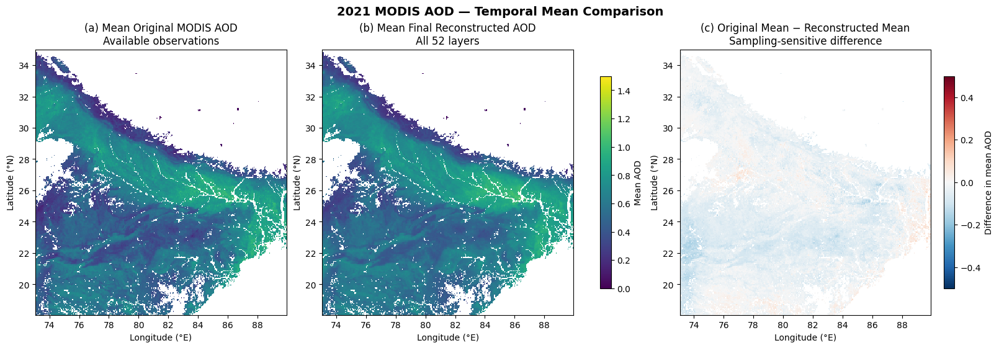

Original mean (spatial average): 0.57024
Reconstructed mean (spatial average): 0.60458
Mean difference (spatial average): -0.03435
Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task2_Reconstruction_Diagnostics/2021_Task2_Mean_AOD_Comparison.png

TASK 2 — STEP 3 COMPLETE


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import warnings

task2_dir.mkdir(parents=True, exist_ok=True)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)

    # Original: mean of available observations only
    original_mean = np.nanmean(original, axis=0)

    # Final: mean across all 52 reconstructed layers
    filled_mean = np.nanmean(final_dineof, axis=0)

# Both maps restricted to the same retained land domain
original_mean = np.where(
    final_mask_2021, original_mean, np.nan
)

filled_mean = np.where(
    final_mask_2021, filled_mean, np.nan
)

# Difference of means with different temporal sampling
mean_difference = original_mean - filled_mean

# Fixed scales for consistent comparison
aod_cmap = plt.get_cmap("viridis").copy()
aod_cmap.set_bad("white")

diff_cmap = plt.get_cmap("RdBu_r").copy()
diff_cmap.set_bad("white")

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5.5),
    constrained_layout=True
)

im0 = axes[0].imshow(
    original_mean, origin="lower",
    extent=extent, cmap=aod_cmap,
    vmin=0, vmax=1.5,
    interpolation="nearest", aspect="auto"
)

im1 = axes[1].imshow(
    filled_mean, origin="lower",
    extent=extent, cmap=aod_cmap,
    vmin=0, vmax=1.5,
    interpolation="nearest", aspect="auto"
)

im2 = axes[2].imshow(
    mean_difference, origin="lower",
    extent=extent, cmap=diff_cmap,
    vmin=-0.5, vmax=0.5,
    interpolation="nearest", aspect="auto"
)

titles = [
    "(a) Mean Original MODIS AOD\nAvailable observations",
    "(b) Mean Final Reconstructed AOD\nAll 52 layers",
    "(c) Original Mean − Reconstructed Mean\nSampling-sensitive difference"
]

for ax, title in zip(axes, titles):
    ax.set_title(title)
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")

fig.colorbar(
    im1, ax=axes[:2],
    shrink=0.8,
    label="Mean AOD"
)

fig.colorbar(
    im2, ax=axes[2],
    shrink=0.8,
    label="Difference in mean AOD"
)

fig.suptitle(
    "2021 MODIS AOD — Temporal Mean Comparison",
    fontsize=14,
    fontweight="bold"
)

save_path = task2_dir / "2021_Task2_Mean_AOD_Comparison.png"

fig.savefig(
    save_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Original mean (spatial average):",
      round(float(np.nanmean(original_mean)), 5))

print("Reconstructed mean (spatial average):",
      round(float(np.nanmean(filled_mean)), 5))

print("Mean difference (spatial average):",
      round(float(np.nanmean(mean_difference)), 5))

print("Saved:", save_path)
print("\nTASK 2 — STEP 3 COMPLETE")


/tmp/ipykernel_1442/3727773435.py:11: RuntimeWarning: Degrees of freedom <= 0 for slice.
  filled_variance = np.nanvar(final_dineof, axis=0)


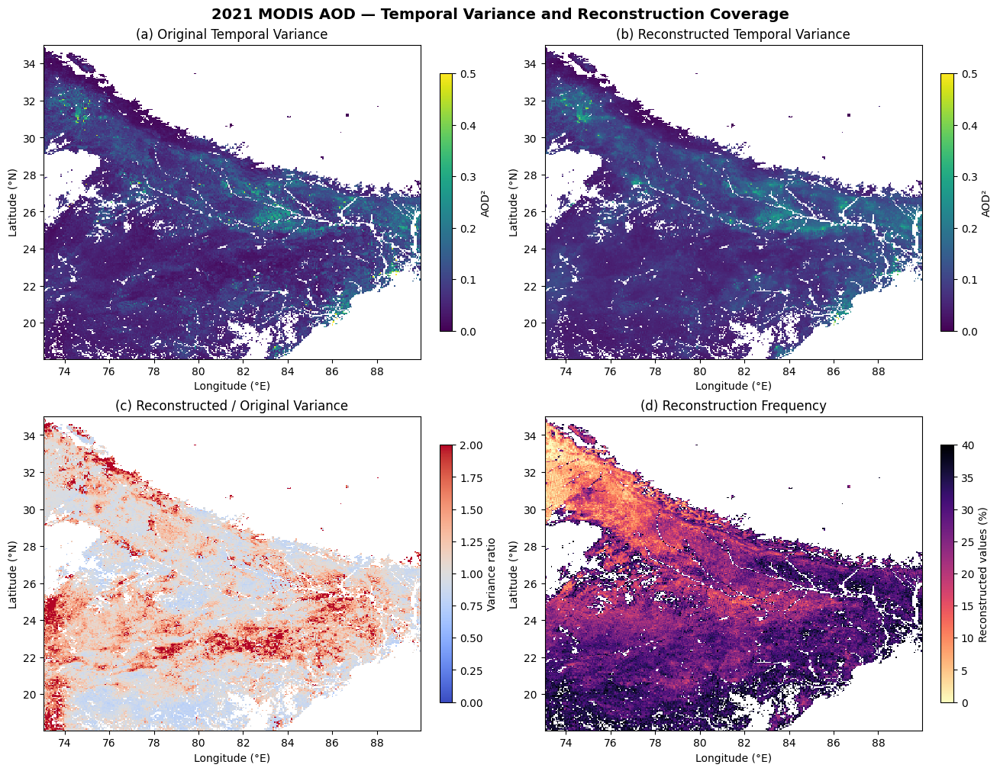

Median original variance: 0.06772
Median reconstructed variance: 0.07591
Median variance ratio: 1.08201
Mean reconstruction frequency (%): 26.3033
Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task2_Reconstruction_Diagnostics/2021_Task2_Variance_and_Reconstruction_Frequency.png

TASK 2 — STEP 4 COMPLETE


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import warnings

# Variance across available original observations
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    original_variance = np.nanvar(original, axis=0)

# Variance across all 52 reconstructed weeks
filled_variance = np.nanvar(final_dineof, axis=0)

# Ratio: reconstructed / original variance
variance_ratio = np.full(
    original_variance.shape, np.nan, dtype=float
)

valid_ratio = (
    final_mask_2021
    & np.isfinite(original_variance)
    & (original_variance > 1e-8)
)

variance_ratio[valid_ratio] = (
    filled_variance[valid_ratio] /
    original_variance[valid_ratio]
)

# Fraction of weekly values that were reconstructed
reconstruction_frequency = (
    100 * np.mean(gap_mask, axis=0)
)

# Restrict all outputs to retained domain
original_variance = np.where(
    final_mask_2021, original_variance, np.nan
)
filled_variance = np.where(
    final_mask_2021, filled_variance, np.nan
)
reconstruction_frequency = np.where(
    final_mask_2021, reconstruction_frequency, np.nan
)

fig, axes = plt.subplots(
    2, 2, figsize=(13, 10),
    constrained_layout=True
)

panels = [
    (
        original_variance,
        "(a) Original Temporal Variance",
        "viridis", 0, 0.5, "AOD²"
    ),
    (
        filled_variance,
        "(b) Reconstructed Temporal Variance",
        "viridis", 0, 0.5, "AOD²"
    ),
    (
        variance_ratio,
        "(c) Reconstructed / Original Variance",
        "coolwarm", 0, 2, "Variance ratio"
    ),
    (
        reconstruction_frequency,
        "(d) Reconstruction Frequency",
        "magma_r", 0, 40, "Reconstructed values (%)"
    )
]

for ax, (data, title, cmap_name, vmin, vmax, label) in zip(
    axes.flat, panels
):
    cmap = plt.get_cmap(cmap_name).copy()
    cmap.set_bad("white")

    im = ax.imshow(
        data,
        origin="lower",
        extent=extent,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest",
        aspect="auto"
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")

    fig.colorbar(
        im, ax=ax,
        shrink=0.82,
        label=label
    )

fig.suptitle(
    "2021 MODIS AOD — Temporal Variance and Reconstruction Coverage",
    fontsize=14,
    fontweight="bold"
)

save_path = (
    task2_dir /
    "2021_Task2_Variance_and_Reconstruction_Frequency.png"
)

fig.savefig(
    save_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Median original variance:",
      round(float(np.nanmedian(original_variance)), 5))

print("Median reconstructed variance:",
      round(float(np.nanmedian(filled_variance)), 5))

print("Median variance ratio:",
      round(float(np.nanmedian(variance_ratio)), 5))

print("Mean reconstruction frequency (%):",
      round(float(np.nanmean(reconstruction_frequency)), 4))

print("Saved:", save_path)
print("\nTASK 2 — STEP 4 COMPLETE")


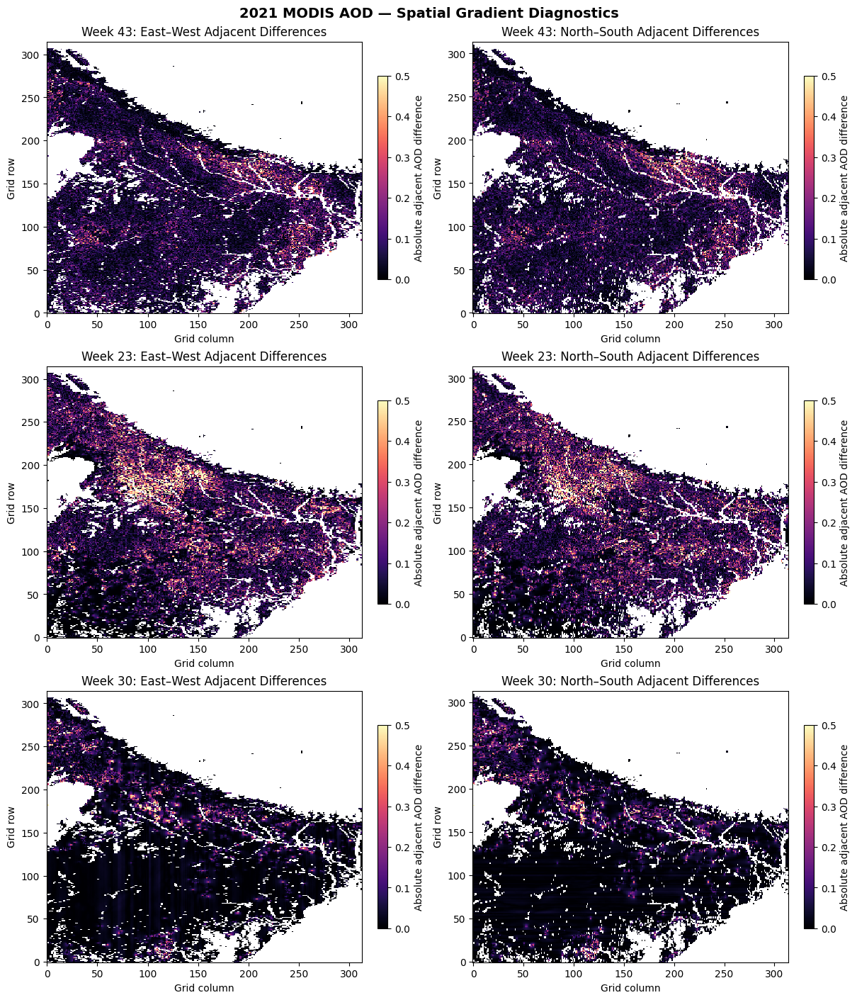

 Week  Missing_Percent  Original_Mean_Abs_dx  Reconstructed_Mean_Abs_dx_Matched  Original_Mean_Abs_dy  Reconstructed_Mean_Abs_dy_Matched  Reconstructed_Mean_Abs_dx_All  Reconstructed_Mean_Abs_dy_All
   43         0.284345              0.070511                           0.070511              0.070009                           0.070009                       0.070573                       0.070073
   23        25.877177              0.123336                           0.123336              0.115015                           0.115015                       0.100101                       0.096716
   30        89.826174              0.114752                           0.114752              0.114377                           0.114377                       0.033486                       0.034436

Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task2_Reconstruction_Diagnostics/2021_Task2_Gradient_Diagnostics.csv
Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

selected_weeks = [43, 23, 30]

rows = []

fig, axes = plt.subplots(
    3, 2,
    figsize=(12, 14),
    constrained_layout=True
)

for row, week in enumerate(selected_weeks):
    t = week - 1

    obs = original[t]
    rec = final_dineof[t]

    # Horizontal differences: neighboring longitude pixels
    dx_obs = np.abs(np.diff(obs, axis=1))
    dx_rec = np.abs(np.diff(rec, axis=1))

    # Vertical differences: neighboring latitude pixels
    dy_obs = np.abs(np.diff(obs, axis=0))
    dy_rec = np.abs(np.diff(rec, axis=0))

    # Only pairs where both original pixels were observed
    valid_x = (
        np.isfinite(obs[:, :-1])
        & np.isfinite(obs[:, 1:])
    )

    valid_y = (
        np.isfinite(obs[:-1, :])
        & np.isfinite(obs[1:, :])
    )

    # Matched-support comparisons
    rows.append({
        "Week": week,
        "Missing_Percent": float(
            weekly_df.loc[
                weekly_df["Week"] == week,
                "Missing_Percent"
            ].iloc[0]
        ),
        "Original_Mean_Abs_dx": np.mean(dx_obs[valid_x]),
        "Reconstructed_Mean_Abs_dx_Matched": np.mean(dx_rec[valid_x]),
        "Original_Mean_Abs_dy": np.mean(dy_obs[valid_y]),
        "Reconstructed_Mean_Abs_dy_Matched": np.mean(dy_rec[valid_y]),
        "Reconstructed_Mean_Abs_dx_All": np.nanmean(dx_rec),
        "Reconstructed_Mean_Abs_dy_All": np.nanmean(dy_rec)
    })

    # Display full reconstructed gradients
    for col, (gradient, title) in enumerate([
        (dx_rec, "East–West Adjacent Differences"),
        (dy_rec, "North–South Adjacent Differences")
    ]):
        ax = axes[row, col]

        im = ax.imshow(
            gradient,
            origin="lower",
            cmap="magma",
            vmin=0,
            vmax=0.5,
            interpolation="nearest",
            aspect="auto"
        )

        ax.set_title(f"Week {week}: {title}")
        ax.set_xlabel("Grid column")
        ax.set_ylabel("Grid row")

        fig.colorbar(
            im, ax=ax,
            shrink=0.75,
            label="Absolute adjacent AOD difference"
        )

fig.suptitle(
    "2021 MODIS AOD — Spatial Gradient Diagnostics",
    fontsize=14,
    fontweight="bold"
)

gradient_df = pd.DataFrame(rows)

csv_path = task2_dir / "2021_Task2_Gradient_Diagnostics.csv"
png_path = task2_dir / "2021_Task2_Gradient_Diagnostics.png"

gradient_df.to_csv(csv_path, index=False)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(gradient_df.to_string(index=False))
print("\nSaved:", csv_path)
print("Saved:", png_path)
print("\nTASK 2 — STEP 5 COMPLETE")


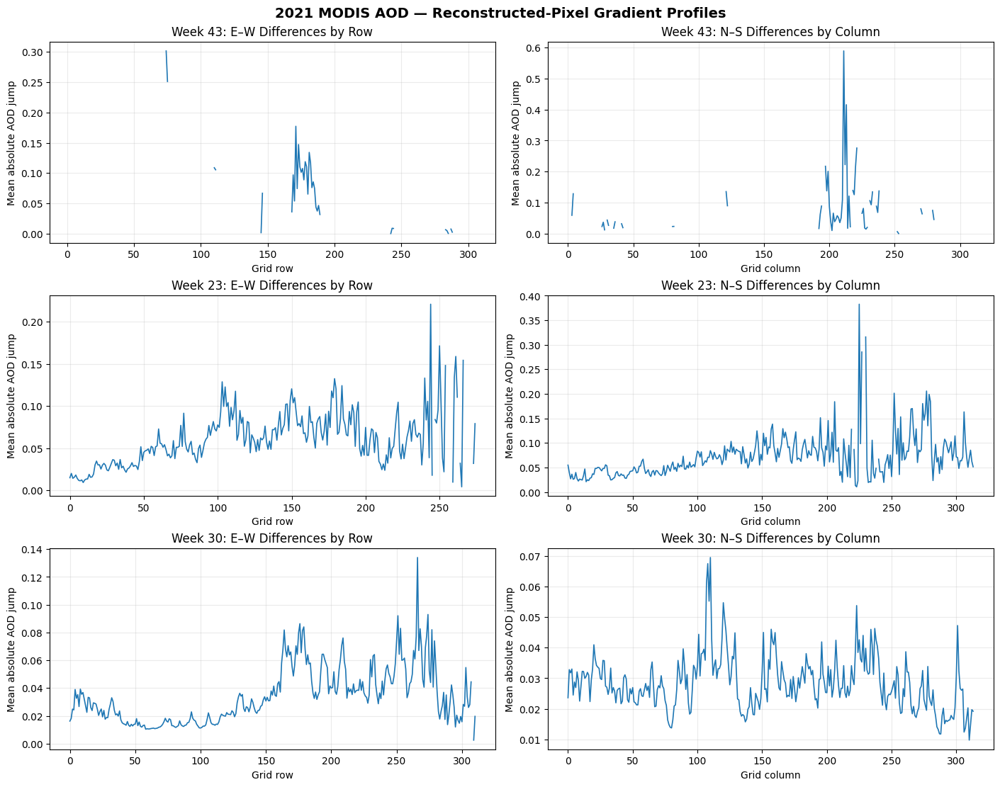

 Week  Missing_Percent  E_W_Fill_Pairs  N_S_Fill_Pairs  Mean_E_W_Jump_Fill_Pairs  Mean_N_S_Jump_Fill_Pairs  Max_Row_Profile  Max_Column_Profile
   43         0.284345             228             228                  0.084953                  0.084875         0.301625            0.588500
   23        25.877177           17233           16962                  0.052000                  0.058012         0.220875            0.382521
   30        89.826174           49926           49558                  0.028632                  0.029142         0.133948            0.069514

Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task2_Reconstruction_Diagnostics/2021_Task2_Stripe_Gradient_Profiles.csv
Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task2_Reconstruction_Diagnostics/2021_Task2_Stripe_Gradient_Profiles.png

TASK 2 — STEP 6 COMPLETE


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

selected_weeks = [43, 23, 30]
results = []

fig, axes = plt.subplots(
    3, 2, figsize=(14, 11),
    constrained_layout=True
)

domain = final_mask_2021

for i, week in enumerate(selected_weeks):
    t = week - 1

    rec = final_dineof[t]
    gaps = gap_mask[t]

    # Adjacent pairs inside retained domain
    valid_x = domain[:, :-1] & domain[:, 1:]
    valid_y = domain[:-1, :] & domain[1:, :]

    # At least one pixel in the pair was reconstructed
    fill_x = gaps[:, :-1] | gaps[:, 1:]
    fill_y = gaps[:-1, :] | gaps[1:, :]

    # Absolute AOD jumps
    dx = np.abs(np.diff(rec, axis=1))
    dy = np.abs(np.diff(rec, axis=0))

    # Include only pairs involving reconstructed pixels
    dx_selected = np.where(valid_x & fill_x, dx, np.nan)
    dy_selected = np.where(valid_y & fill_y, dy, np.nan)

    # Row profile: east-west changes
    x_count = np.isfinite(dx_selected).sum(axis=1)
    row_profile = np.divide(
        np.nansum(dx_selected, axis=1),
        x_count,
        out=np.full(dx_selected.shape[0], np.nan),
        where=x_count > 0
    )

    # Column profile: north-south changes
    y_count = np.isfinite(dy_selected).sum(axis=0)
    col_profile = np.divide(
        np.nansum(dy_selected, axis=0),
        y_count,
        out=np.full(dy_selected.shape[1], np.nan),
        where=y_count > 0
    )

    axes[i, 0].plot(
        np.arange(len(row_profile)),
        row_profile,
        linewidth=1.2
    )
    axes[i, 0].set_title(
        f"Week {week}: E–W Differences by Row"
    )
    axes[i, 0].set_xlabel("Grid row")
    axes[i, 0].set_ylabel("Mean absolute AOD jump")
    axes[i, 0].grid(alpha=0.25)

    axes[i, 1].plot(
        np.arange(len(col_profile)),
        col_profile,
        linewidth=1.2
    )
    axes[i, 1].set_title(
        f"Week {week}: N–S Differences by Column"
    )
    axes[i, 1].set_xlabel("Grid column")
    axes[i, 1].set_ylabel("Mean absolute AOD jump")
    axes[i, 1].grid(alpha=0.25)

    results.append({
        "Week": week,
        "Missing_Percent": float(
            weekly_df.loc[
                weekly_df["Week"] == week,
                "Missing_Percent"
            ].iloc[0]
        ),
        "E_W_Fill_Pairs": int(np.isfinite(dx_selected).sum()),
        "N_S_Fill_Pairs": int(np.isfinite(dy_selected).sum()),
        "Mean_E_W_Jump_Fill_Pairs": float(np.nanmean(dx_selected)),
        "Mean_N_S_Jump_Fill_Pairs": float(np.nanmean(dy_selected)),
        "Max_Row_Profile": float(np.nanmax(row_profile)),
        "Max_Column_Profile": float(np.nanmax(col_profile))
    })

fig.suptitle(
    "2021 MODIS AOD — Reconstructed-Pixel Gradient Profiles",
    fontsize=14,
    fontweight="bold"
)

stripe_df = pd.DataFrame(results)

csv_path = task2_dir / "2021_Task2_Stripe_Gradient_Profiles.csv"
png_path = task2_dir / "2021_Task2_Stripe_Gradient_Profiles.png"

stripe_df.to_csv(csv_path, index=False)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(stripe_df.to_string(index=False))
print("\nSaved:", csv_path)
print("Saved:", png_path)
print("\nTASK 2 — STEP 6 COMPLETE")


In [ ]:

import numpy as np
import pandas as pd

selected_weeks = [43, 23, 30]
boundary_results = []

domain = final_mask_2021

for week in selected_weeks:
    t = week - 1
    rec = final_dineof[t]
    gaps = gap_mask[t]

    # Adjacent pairs within retained domain
    valid_x = domain[:, :-1] & domain[:, 1:]
    valid_y = domain[:-1, :] & domain[1:, :]

    dx = np.abs(np.diff(rec, axis=1))
    dy = np.abs(np.diff(rec, axis=0))

    # Both adjacent pixels reconstructed
    ff_x = valid_x & gaps[:, :-1] & gaps[:, 1:]
    ff_y = valid_y & gaps[:-1, :] & gaps[1:, :]

    # Exactly one adjacent pixel reconstructed
    of_x = valid_x & (gaps[:, :-1] ^ gaps[:, 1:])
    of_y = valid_y & (gaps[:-1, :] ^ gaps[1:, :])

    for direction, grad, ff, of in [
        ("East-West", dx, ff_x, of_x),
        ("North-South", dy, ff_y, of_y)
    ]:
        boundary_results.append({
            "Week": week,
            "Direction": direction,
            "Filled_Filled_Pairs": int(ff.sum()),
            "Observed_Filled_Pairs": int(of.sum()),
            "Mean_Jump_Filled_Filled":
                float(np.mean(grad[ff])) if ff.any() else np.nan,
            "Mean_Jump_Observed_Filled":
                float(np.mean(grad[of])) if of.any() else np.nan,
            "P95_Jump_Filled_Filled":
                float(np.percentile(grad[ff], 95)) if ff.any() else np.nan,
            "P95_Jump_Observed_Filled":
                float(np.percentile(grad[of], 95)) if of.any() else np.nan
        })

boundary_df = pd.DataFrame(boundary_results)

csv_path = (
    task2_dir /
    "2021_Task2_Filled_vs_Boundary_Gradient_Comparison.csv"
)

boundary_df.to_csv(csv_path, index=False)

print("=== RECONSTRUCTION BOUNDARY DIAGNOSTICS ===")
print(boundary_df.to_string(index=False))
print("\nSaved:", csv_path)
print("\nTASK 2 — STEP 7 COMPLETE")


=== RECONSTRUCTION BOUNDARY DIAGNOSTICS ===
 Week   Direction  Filled_Filled_Pairs  Observed_Filled_Pairs  Mean_Jump_Filled_Filled  Mean_Jump_Observed_Filled  P95_Jump_Filled_Filled  P95_Jump_Observed_Filled
   43   East-West                   22                    206                 0.056694                   0.087971                0.167492                  0.275178
   43 North-South                   18                    210                 0.049780                   0.087883                0.147369                  0.279627
   23   East-West                 9746                   7487                 0.026231                   0.085545                0.089720                  0.278845
   23 North-South                 9984                   6978                 0.030547                   0.097307                0.105057                  0.309928
   30   East-West                45037                   4889                 0.021023                   0.098726                0.06901

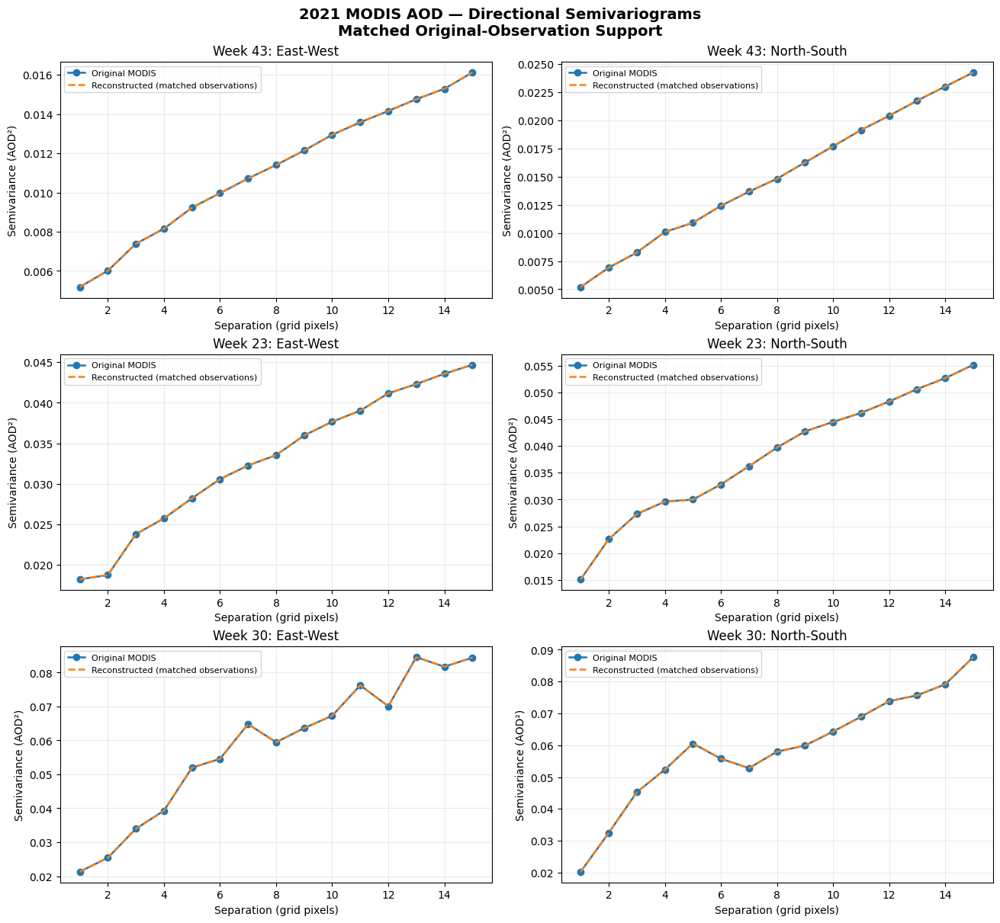

Number of semivariogram records: 90
Minimum observed pairs: 1375
Maximum observed pairs: 52680
Maximum absolute matched semivariance difference: 7.532276760646717e-09

Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task2_Reconstruction_Diagnostics/2021_Task2_Directional_Semivariograms.csv
Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task2_Reconstruction_Diagnostics/2021_Task2_Directional_Semivariograms.png

TASK 2 — STEP 8 COMPLETE


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

selected_weeks = [43, 23, 30]
max_lag = 15
records = []

fig, axes = plt.subplots(
    3, 2, figsize=(13, 12),
    constrained_layout=True
)

for i, week in enumerate(selected_weeks):
    t = week - 1
    obs = original[t]
    rec = final_dineof[t]

    for j, direction in enumerate(["East-West", "North-South"]):
        lag_values = []
        gamma_original = []
        gamma_filled = []

        for lag in range(1, max_lag + 1):
            if direction == "East-West":
                a_obs = obs[:, :-lag]
                b_obs = obs[:, lag:]
                a_rec = rec[:, :-lag]
                b_rec = rec[:, lag:]
            else:
                a_obs = obs[:-lag, :]
                b_obs = obs[lag:, :]
                a_rec = rec[:-lag, :]
                b_rec = rec[lag:, :]

            # Same observed pairs for both datasets
            valid = np.isfinite(a_obs) & np.isfinite(b_obs)

            if valid.sum() < 30:
                continue

            semivar_obs = 0.5 * np.mean(
                (a_obs[valid] - b_obs[valid]) ** 2
            )

            semivar_rec = 0.5 * np.mean(
                (a_rec[valid] - b_rec[valid]) ** 2
            )

            lag_values.append(lag)
            gamma_original.append(semivar_obs)
            gamma_filled.append(semivar_rec)

            records.append({
                "Week": week,
                "Direction": direction,
                "Lag_Pixels": lag,
                "Observed_Pairs": int(valid.sum()),
                "Original_Semivariance": float(semivar_obs),
                "Reconstructed_Semivariance_Matched": float(semivar_rec)
            })

        ax = axes[i, j]

        ax.plot(
            lag_values,
            gamma_original,
            "o-",
            label="Original MODIS",
            linewidth=1.8
        )

        ax.plot(
            lag_values,
            gamma_filled,
            "--",
            label="Reconstructed (matched observations)",
            linewidth=1.8
        )

        ax.set_title(f"Week {week}: {direction}")
        ax.set_xlabel("Separation (grid pixels)")
        ax.set_ylabel("Semivariance (AOD²)")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

fig.suptitle(
    "2021 MODIS AOD — Directional Semivariograms\n"
    "Matched Original-Observation Support",
    fontsize=14,
    fontweight="bold"
)

semivar_df = pd.DataFrame(records)

csv_path = task2_dir / "2021_Task2_Directional_Semivariograms.csv"
png_path = task2_dir / "2021_Task2_Directional_Semivariograms.png"

semivar_df.to_csv(csv_path, index=False)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Number of semivariogram records:", len(semivar_df))
print("Minimum observed pairs:",
      semivar_df["Observed_Pairs"].min())
print("Maximum observed pairs:",
      semivar_df["Observed_Pairs"].max())

print("Maximum absolute matched semivariance difference:",
      np.max(np.abs(
          semivar_df["Original_Semivariance"]
          - semivar_df["Reconstructed_Semivariance_Matched"]
      )))

print("\nSaved:", csv_path)
print("Saved:", png_path)
print("\nTASK 2 — STEP 8 COMPLETE")


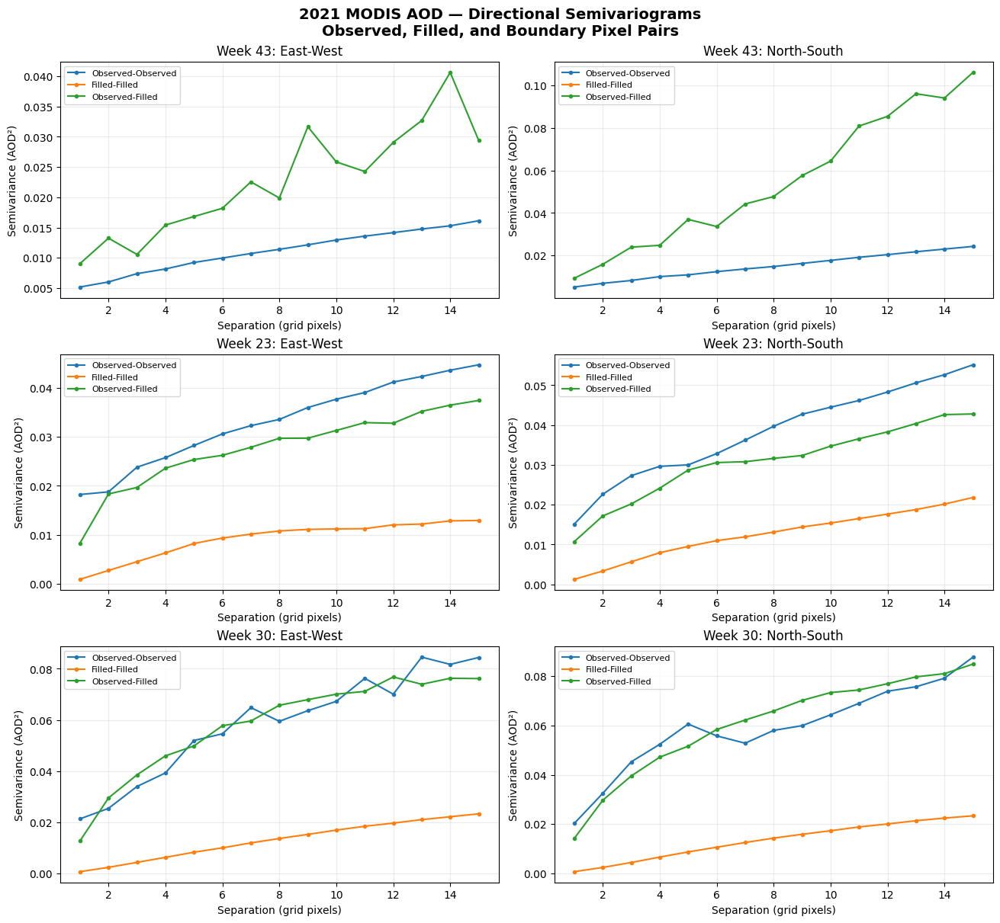

Total records: 240

Pair counts at lag 1:
 Week   Direction          Category  Pair_Count  Semivariance
   43   East-West Observed-Observed       52680      0.005178
   43   East-West   Observed-Filled         206      0.009046
   43 North-South Observed-Observed       52612      0.005195
   43 North-South   Observed-Filled         210      0.009315
   23   East-West Observed-Observed       35675      0.018230
   23   East-West     Filled-Filled        9746      0.000933
   23   East-West   Observed-Filled        7487      0.008324
   23 North-South Observed-Observed       35878      0.015122
   23 North-South     Filled-Filled        9984      0.001247
   23 North-South   Observed-Filled        6978      0.010713
   30   East-West Observed-Observed        2982      0.021315
   30   East-West     Filled-Filled       45037      0.000674
   30   East-West   Observed-Filled        4889      0.012713
   30 North-South Observed-Observed        3282      0.020292
   30 North-South     Filled

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

selected_weeks = [43, 23, 30]
max_lag = 15

records = []

fig, axes = plt.subplots(
    3, 2, figsize=(13, 12),
    constrained_layout=True
)

for i, week in enumerate(selected_weeks):
    t = week - 1

    rec = final_dineof[t]
    observed_pixels = observed_mask[t]
    filled_pixels = gap_mask[t]

    for j, direction in enumerate(["East-West", "North-South"]):
        for category in [
            "Observed-Observed",
            "Filled-Filled",
            "Observed-Filled"
        ]:
            lag_list = []
            gamma_list = []

            for lag in range(1, max_lag + 1):
                if direction == "East-West":
                    a = rec[:, :-lag]
                    b = rec[:, lag:]

                    obs_a = observed_pixels[:, :-lag]
                    obs_b = observed_pixels[:, lag:]

                    fill_a = filled_pixels[:, :-lag]
                    fill_b = filled_pixels[:, lag:]
                else:
                    a = rec[:-lag, :]
                    b = rec[lag:, :]

                    obs_a = observed_pixels[:-lag, :]
                    obs_b = observed_pixels[lag:, :]

                    fill_a = filled_pixels[:-lag, :]
                    fill_b = filled_pixels[lag:, :]

                if category == "Observed-Observed":
                    valid = obs_a & obs_b
                elif category == "Filled-Filled":
                    valid = fill_a & fill_b
                else:
                    valid = (obs_a & fill_b) | (fill_a & obs_b)

                count = int(valid.sum())

                if count < 30:
                    continue

                gamma = 0.5 * np.mean(
                    (a[valid] - b[valid]) ** 2
                )

                records.append({
                    "Week": week,
                    "Direction": direction,
                    "Category": category,
                    "Lag_Pixels": lag,
                    "Pair_Count": count,
                    "Semivariance": float(gamma)
                })

                lag_list.append(lag)
                gamma_list.append(gamma)

            axes[i, j].plot(
                lag_list,
                gamma_list,
                marker="o",
                markersize=3,
                linewidth=1.5,
                label=category
            )

        axes[i, j].set_title(f"Week {week}: {direction}")
        axes[i, j].set_xlabel("Separation (grid pixels)")
        axes[i, j].set_ylabel("Semivariance (AOD²)")
        axes[i, j].grid(alpha=0.25)
        axes[i, j].legend(fontsize=8)

fig.suptitle(
    "2021 MODIS AOD — Directional Semivariograms\n"
    "Observed, Filled, and Boundary Pixel Pairs",
    fontsize=14,
    fontweight="bold"
)

semivar_categories_df = pd.DataFrame(records)

csv_path = (
    task2_dir /
    "2021_Task2_Semivariograms_By_Pixel_Category.csv"
)

png_path = (
    task2_dir /
    "2021_Task2_Semivariograms_By_Pixel_Category.png"
)

semivar_categories_df.to_csv(csv_path, index=False)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Total records:", len(semivar_categories_df))

print("\nPair counts at lag 1:")
print(
    semivar_categories_df[
        semivar_categories_df["Lag_Pixels"] == 1
    ][
        ["Week", "Direction", "Category",
         "Pair_Count", "Semivariance"]
    ].to_string(index=False)
)

print("\nSaved:", csv_path)
print("Saved:", png_path)
print("\nTASK 2 — STEP 9 COMPLETE")


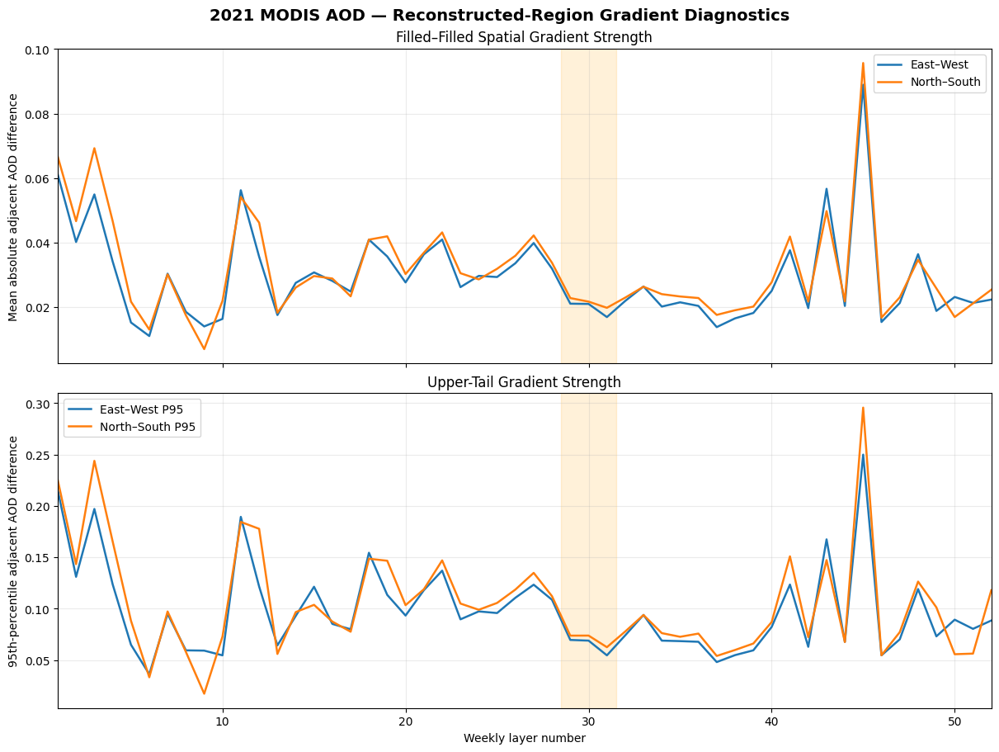

 Week  Missing_Percent  Filled_Filled_EW_Pairs  Filled_Filled_NS_Pairs  Mean_EW_Gradient  Mean_NS_Gradient  P95_EW_Gradient  P95_NS_Gradient
   23        25.877177                    9746                    9984          0.026231          0.030547         0.089720         0.105057
   29        80.085125                   39158                   39030          0.021104          0.022842         0.069681         0.073857
   30        89.826174                   45037                   45294          0.021023          0.021737         0.069011         0.073910
   31        89.096534                   45217                   45206          0.016956          0.019825         0.054709         0.062637
   43         0.284345                      22                      18          0.056694          0.049780         0.167492         0.147369

Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task2_Reconstruction_Diagnostics/2021_Task2_All_52_Weeks_Gradient_Diagnostics.csv
Sa

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

records = []
domain = final_mask_2021

for t in range(52):
    rec = final_dineof[t]
    gaps = gap_mask[t]

    # Adjacent pairs inside the retained domain
    valid_x = domain[:, :-1] & domain[:, 1:]
    valid_y = domain[:-1, :] & domain[1:, :]

    # Both pixels reconstructed
    ff_x = valid_x & gaps[:, :-1] & gaps[:, 1:]
    ff_y = valid_y & gaps[:-1, :] & gaps[1:, :]

    dx = np.abs(np.diff(rec, axis=1))
    dy = np.abs(np.diff(rec, axis=0))

    x_values = dx[ff_x]
    y_values = dy[ff_y]

    records.append({
        "Week": t + 1,
        "Missing_Percent": float(
            weekly_df.loc[t, "Missing_Percent"]
        ),
        "Filled_Filled_EW_Pairs": len(x_values),
        "Filled_Filled_NS_Pairs": len(y_values),
        "Mean_EW_Gradient": (
            float(np.mean(x_values)) if len(x_values) else np.nan
        ),
        "Mean_NS_Gradient": (
            float(np.mean(y_values)) if len(y_values) else np.nan
        ),
        "P95_EW_Gradient": (
            float(np.percentile(x_values, 95)) if len(x_values) else np.nan
        ),
        "P95_NS_Gradient": (
            float(np.percentile(y_values, 95)) if len(y_values) else np.nan
        )
    })

all_weeks_gradient_df = pd.DataFrame(records)

fig, axes = plt.subplots(
    2, 1, figsize=(12, 9),
    sharex=True,
    constrained_layout=True
)

axes[0].plot(
    all_weeks_gradient_df["Week"],
    all_weeks_gradient_df["Mean_EW_Gradient"],
    label="East–West",
    linewidth=1.8
)

axes[0].plot(
    all_weeks_gradient_df["Week"],
    all_weeks_gradient_df["Mean_NS_Gradient"],
    label="North–South",
    linewidth=1.8
)

axes[0].set_ylabel("Mean absolute adjacent AOD difference")
axes[0].set_title("Filled–Filled Spatial Gradient Strength")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    all_weeks_gradient_df["Week"],
    all_weeks_gradient_df["P95_EW_Gradient"],
    label="East–West P95",
    linewidth=1.8
)

axes[1].plot(
    all_weeks_gradient_df["Week"],
    all_weeks_gradient_df["P95_NS_Gradient"],
    label="North–South P95",
    linewidth=1.8
)

axes[1].set_ylabel("95th-percentile adjacent AOD difference")
axes[1].set_xlabel("Weekly layer number")
axes[1].set_title("Upper-Tail Gradient Strength")
axes[1].legend()
axes[1].grid(alpha=0.25)

for ax in axes:
    ax.axvspan(28.5, 31.5, color="orange", alpha=0.15)
    ax.set_xlim(1, 52)

fig.suptitle(
    "2021 MODIS AOD — Reconstructed-Region Gradient Diagnostics",
    fontsize=14,
    fontweight="bold"
)

csv_path = (
    task2_dir /
    "2021_Task2_All_52_Weeks_Gradient_Diagnostics.csv"
)

png_path = (
    task2_dir /
    "2021_Task2_All_52_Weeks_Gradient_Diagnostics.png"
)

all_weeks_gradient_df.to_csv(csv_path, index=False)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(
    all_weeks_gradient_df[
        all_weeks_gradient_df["Week"].isin([23, 29, 30, 31, 43])
    ].to_string(index=False)
)

print("\nSaved:", csv_path)
print("Saved:", png_path)
print("\nTASK 2 — STEP 10 COMPLETE")


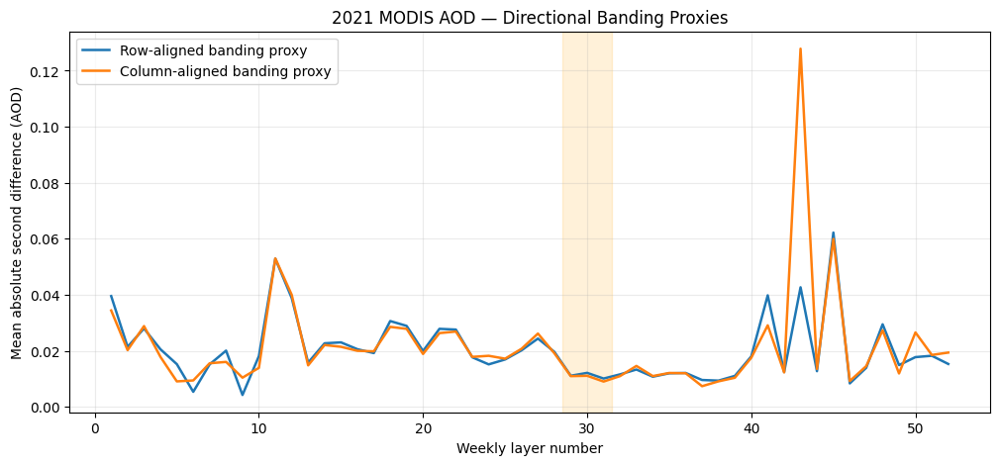

 Week  Missing_Percent  NS_Triplets  EW_Triplets  Row_Banding_Proxy  Column_Banding_Proxy
   23        25.877177         7518         7777           0.017692              0.017838
   29        80.085125        34701        35065           0.011107              0.010968
   30        89.826174        41342        41410           0.012133              0.011089
   31        89.096534        41569        41825           0.010108              0.009029
   43         0.284345            3            6           0.042675              0.127852
   45         2.238993          370          412           0.062208              0.059935

Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task2_Reconstruction_Diagnostics/2021_Task2_Directional_Banding_Proxies.csv
Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task2_Reconstruction_Diagnostics/2021_Task2_Directional_Banding_Proxies.png

TASK 2 — STEP 11 COMPLETE


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

records = []

for t in range(52):
    z = final_dineof[t]
    g = gap_mask[t]

    # Second differences along latitude:
    # Sensitive to row-aligned discontinuities
    ns_second = np.abs(
        z[2:, 1:-1]
        - 2 * z[1:-1, 1:-1]
        + z[:-2, 1:-1]
    )

    # Second differences along longitude:
    # Sensitive to column-aligned discontinuities
    ew_second = np.abs(
        z[1:-1, 2:]
        - 2 * z[1:-1, 1:-1]
        + z[1:-1, :-2]
    )

    ns_valid = (
        g[2:, 1:-1]
        & g[1:-1, 1:-1]
        & g[:-2, 1:-1]
    )

    ew_valid = (
        g[1:-1, 2:]
        & g[1:-1, 1:-1]
        & g[1:-1, :-2]
    )

    ns_values = ns_second[ns_valid]
    ew_values = ew_second[ew_valid]

    records.append({
        "Week": t + 1,
        "Missing_Percent": float(
            weekly_df.loc[t, "Missing_Percent"]
        ),
        "NS_Triplets": len(ns_values),
        "EW_Triplets": len(ew_values),
        "Row_Banding_Proxy": (
            float(np.mean(ns_values)) if len(ns_values) else np.nan
        ),
        "Column_Banding_Proxy": (
            float(np.mean(ew_values)) if len(ew_values) else np.nan
        )
    })

banding_df = pd.DataFrame(records)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    banding_df["Week"],
    banding_df["Row_Banding_Proxy"],
    label="Row-aligned banding proxy",
    linewidth=1.8
)

ax.plot(
    banding_df["Week"],
    banding_df["Column_Banding_Proxy"],
    label="Column-aligned banding proxy",
    linewidth=1.8
)

ax.axvspan(28.5, 31.5, color="orange", alpha=0.15)

ax.set_xlabel("Weekly layer number")
ax.set_ylabel("Mean absolute second difference (AOD)")
ax.set_title(
    "2021 MODIS AOD — Directional Banding Proxies"
)

ax.legend()
ax.grid(alpha=0.25)

csv_path = (
    task2_dir /
    "2021_Task2_Directional_Banding_Proxies.csv"
)

png_path = (
    task2_dir /
    "2021_Task2_Directional_Banding_Proxies.png"
)

banding_df.to_csv(csv_path, index=False)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(
    banding_df[
        banding_df["Week"].isin([23, 29, 30, 31, 43, 45])
    ].to_string(index=False)
)

print("\nSaved:", csv_path)
print("Saved:", png_path)
print("\nTASK 2 — STEP 11 COMPLETE")


In [ ]:

from pathlib import Path

report = """2021 MODIS AOD — TASK 2 RECONSTRUCTION DIAGNOSTIC SUMMARY

Study domain:
18–35 degrees N, 73–90 degrees E
52 weekly layers, factor-2 spatial aggregation
Retained land pixels: 55,918
Original missingness in retained domain: 26.3033%

1. PAIRED RECONSTRUCTION MAPS
Week 43: 0.2843% missing; original and filled maps nearly identical.
Week 23: 25.8772% missing; moderate gap filling and visible smoothing.
Week 30: 89.8262% missing; extensive gap filling, with residual
band-like spatial structures.

2. TEMPORAL VARIANCE
Median original variance: 0.06772 AOD^2
Median reconstructed variance: 0.07591 AOD^2
Median pixel-wise variance ratio: 1.08201
Mean reconstruction frequency: 26.3033%

These variance estimates use different temporal sampling and
cannot independently establish reconstruction fidelity.

3. SPATIAL GRADIENTS
Week 30 mean filled-filled adjacent jumps:
East-West: 0.021023 AOD
North-South: 0.021737 AOD

Week 30 observed-filled adjacent jumps:
East-West: 0.098726 AOD
North-South: 0.107798 AOD

These results are consistent with smooth reconstructed regions
and stronger transitions at observation boundaries.
Different geographic sampling prevents causal attribution.

4. DIRECTIONAL SEMIVARIOGRAMS
Observed and reconstructed semivariograms on matched
observed-only pairs agree to numerical precision, as expected
from preservation of observed MODIS values.

Week 30 lag-1 semivariance:
East-West observed-observed: 0.021315 AOD^2
East-West filled-filled: 0.000674 AOD^2
North-South observed-observed: 0.020292 AOD^2
North-South filled-filled: 0.000731 AOD^2

These values are from different spatial subsets and
are descriptive, not independent validation.

5. BANDING PROXIES
Week 30:
Row-aligned proxy: 0.012133 AOD
Column-aligned proxy: 0.011089 AOD

Low second-difference values do not rule out broad stripes.
Weeks 43 and 45 have small reconstructed samples, so
their elevated proxy values require cautious interpretation.

6. SCIENTIFIC LIMITATIONS
- Final reconstruction preserves observed MODIS values.
- Near-zero original-minus-final differences are expected.
- Spatial smoothing is suggested but not independently verified.
- Stripe artifacts remain a concern, especially in highly
  missing weekly layers.
- Actual calendar dates remain unverified.
- Independent withheld-observation validation is essential.
- Spatial autocorrelation preservation in missing areas
  has not yet been independently demonstrated.

STATUS:
Task 2 exploratory reconstruction diagnostics completed.
Independent validation and further artifact testing remain necessary.
"""

report_path = (
    task2_dir / "2021_Task2_Diagnostic_Summary.txt"
)

report_path.write_text(report, encoding="utf-8")

print(report)
print("\nSaved:", report_path)
print("\nTASK 2 — STEP 12 COMPLETE")


2021 MODIS AOD — TASK 2 RECONSTRUCTION DIAGNOSTIC SUMMARY

Study domain:
18–35 degrees N, 73–90 degrees E
52 weekly layers, factor-2 spatial aggregation
Retained land pixels: 55,918
Original missingness in retained domain: 26.3033%

1. PAIRED RECONSTRUCTION MAPS
Week 43: 0.2843% missing; original and filled maps nearly identical.
Week 23: 25.8772% missing; moderate gap filling and visible smoothing.
Week 30: 89.8262% missing; extensive gap filling, with residual
band-like spatial structures.

2. TEMPORAL VARIANCE
Median original variance: 0.06772 AOD^2
Median reconstructed variance: 0.07591 AOD^2
Median pixel-wise variance ratio: 1.08201
Mean reconstruction frequency: 26.3033%

These variance estimates use different temporal sampling and
cannot independently establish reconstruction fidelity.

3. SPATIAL GRADIENTS
Week 30 mean filled-filled adjacent jumps:
East-West: 0.021023 AOD
North-South: 0.021737 AOD

Week 30 observed-filled adjacent jumps:
East-West: 0.098726 AOD
North-South: 0.1

In [ ]:

import numpy as np
from pathlib import Path

# TASK 3 — STEP 1
# Create a reproducible 10% independent holdout

validation_dir = (
    output_dir / "2021_Task3_Independent_Validation"
)
validation_dir.mkdir(parents=True, exist_ok=True)

# Original MODIS observations inside retained study domain
original_values = np.asarray(original, dtype=np.float64)

assert original_values.shape == (52, 315, 314)
assert np.isfinite(original_values).sum() == 2142906

# Fixed random seed for reproducibility
random_seed = 2021
rng = np.random.default_rng(random_seed)

# Positions of all available original observations
valid_positions = np.flatnonzero(
    np.isfinite(original_values.ravel())
)

# Randomly withhold exactly 10%
n_holdout = int(round(0.10 * len(valid_positions)))

holdout_flat = rng.choice(
    valid_positions,
    size=n_holdout,
    replace=False
)

holdout_mask = np.zeros(
    original_values.size, dtype=bool
)
holdout_mask[holdout_flat] = True
holdout_mask = holdout_mask.reshape(
    original_values.shape
)

# Save true values before hiding them
holdout_true = original_values[holdout_mask].copy()

# Create training data with withheld observations hidden
training_aod = original_values.copy()
training_aod[holdout_mask] = np.nan

# Verify that the training dataset has no access to held-out values
assert np.isnan(training_aod[holdout_mask]).all()
assert np.isfinite(holdout_true).all()

# Save the complete reproducible holdout specification
save_path = (
    validation_dir /
    "2021_Task3_Holdout_10percent_Seed2021.npz"
)

np.savez_compressed(
    save_path,
    training_aod=training_aod.astype(np.float32),
    holdout_mask=holdout_mask,
    holdout_true=holdout_true.astype(np.float32),
    lat=np.asarray(lat_2021),
    lon=np.asarray(lon_2021),
    final_domain_mask=final_mask_2021,
    random_seed=random_seed,
    holdout_fraction=0.10
)

print("=== 2021 INDEPENDENT HOLDOUT ===")
print("Original observations:", len(valid_positions))
print("Withheld observations:", n_holdout)
print("Training observations:",
      np.isfinite(training_aod).sum())
print("Holdout percentage:",
      round(100 * n_holdout / len(valid_positions), 4))

print("Holdout AOD range:",
      float(holdout_true.min()),
      "to",
      float(holdout_true.max()))

print("Saved:", save_path)
print("\nTASK 3 — STEP 1 PASSED")


=== 2021 INDEPENDENT HOLDOUT ===
Original observations: 2142906
Withheld observations: 214291
Training observations: 1928615
Holdout percentage: 10.0
Holdout AOD range: -0.050000002374872565 to 4.961000235634856
Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Independent_Validation/2021_Task3_Holdout_10percent_Seed2021.npz

TASK 3 — STEP 1 PASSED


In [ ]:

import numpy as np
import pandas as pd

# Reload saved validation dataset
holdout_file = (
    validation_dir /
    "2021_Task3_Holdout_10percent_Seed2021.npz"
)

with np.load(holdout_file) as data:
    train = data["training_aod"]
    withheld = data["holdout_mask"]
    domain = data["final_domain_mask"]

# Training observations per retained pixel
pixel_train_count = np.isfinite(train).sum(axis=0)
retained_counts = pixel_train_count[domain]

# Training observations per weekly layer
weekly_train_count = np.isfinite(
    train[:, domain]
).sum(axis=1)

# Holdout observations per weekly layer
weekly_holdout_count = withheld[:, domain].sum(axis=1)

# Verify consistency
assert int(withheld.sum()) == 214291
assert int(np.isfinite(train).sum()) == 1928615
assert np.array_equal(domain, final_mask_2021)
assert not np.any(np.isfinite(train) & withheld)

coverage_df = pd.DataFrame({
    "Week": np.arange(1, 53),
    "Training_Observations": weekly_train_count,
    "Withheld_Observations": weekly_holdout_count
})

coverage_path = (
    validation_dir /
    "2021_Task3_Training_Coverage_Seed2021.csv"
)

coverage_df.to_csv(coverage_path, index=False)

print("=== TRAINING COVERAGE VERIFICATION ===")
print("Retained pixels:", len(retained_counts))
print("Minimum observations per pixel:",
      retained_counts.min())
print("Median observations per pixel:",
      np.median(retained_counts))
print("Maximum observations per pixel:",
      retained_counts.max())

print("Pixels with fewer than 2 training observations:",
      np.sum(retained_counts < 2))
print("Pixels with fewer than 10 training observations:",
      np.sum(retained_counts < 10))

print("\nWeekly training and holdout counts:")
print(coverage_df.to_string(index=False))

print("\nSaved:", coverage_path)
print("\nTASK 3 — STEP 2 COMPLETE")


=== TRAINING COVERAGE VERIFICATION ===
Retained pixels: 55918
Minimum observations per pixel: 21
Median observations per pixel: 34.0
Maximum observations per pixel: 51
Pixels with fewer than 2 training observations: 0
Pixels with fewer than 10 training observations: 0

Weekly training and holdout counts:
 Week  Training_Observations  Withheld_Observations
    1                  46862                   5179
    2                  44908                   5108
    3                  46799                   5204
    4                  42613                   4747
    5                  49466                   5449
    6                  49970                   5520
    7                  48938                   5453
    8                  49848                   5697
    9                  50170                   5559
   10                  49965                   5503
   11                  49635                   5393
   12                  49521                   5471
   13             

In [ ]:

import numpy as np

# Use the training dataset loaded in Step 2
assert train.shape == (52, 315, 314)
assert domain.shape == (315, 314)

# Verify withheld observations are unavailable to training
assert not np.isfinite(train[withheld]).any()

# Count training observations per retained pixel
counts = np.isfinite(train).sum(axis=0)[domain]

print("=== TRAINING DATA INTEGRITY ===")
print("Retained pixels:", counts.size)
print("Minimum training observations per pixel:", counts.min())
print("Median training observations per pixel:", np.median(counts))
print("Maximum training observations per pixel:", counts.max())

print("Pixels with zero observations:", np.sum(counts == 0))
print("Pixels with fewer than 2 observations:", np.sum(counts < 2))
print("Pixels with fewer than 10 observations:", np.sum(counts < 10))
print("Pixels with fewer than 20 observations:", np.sum(counts < 20))

# Check finite training values and missing cells
print("\nTraining observations:", np.isfinite(train).sum())
print("Withheld observations:", withheld.sum())

# Verify retained-domain accounting
total_cells = 52 * int(domain.sum())
missing_training = total_cells - int(np.isfinite(train).sum())

print("Total retained-domain cells:", total_cells)
print("Missing cells during training:", missing_training)
print("Training missingness (%):",
      round(100 * missing_training / total_cells, 4))

assert counts.min() >= 1
assert total_cells == 2907736
assert missing_training == 979121

print("\nTASK 3 — STEP 3 PASSED")


=== TRAINING DATA INTEGRITY ===
Retained pixels: 55918
Minimum training observations per pixel: 21
Median training observations per pixel: 34.0
Maximum training observations per pixel: 51
Pixels with zero observations: 0
Pixels with fewer than 2 observations: 0
Pixels with fewer than 10 observations: 0
Pixels with fewer than 20 observations: 0

Training observations: 1928615
Withheld observations: 214291
Total retained-domain cells: 2907736
Missing cells during training: 979121
Training missingness (%): 33.673

TASK 3 — STEP 3 PASSED


In [ ]:

import numpy as np

# Training data: time, latitude, longitude
train_3d = np.asarray(train, dtype=np.float64)

# DINEOF expects latitude, longitude, time
train_tensor = np.moveaxis(train_3d, 0, -1)

# Extract retained land pixels only
train_values = train_tensor[domain]

# Prepare spatial coordinates for retained pixels
lat_grid, lon_grid = np.meshgrid(
    lat_2021,
    lon_2021,
    indexing="ij"
)

train_coords = np.column_stack([
    lat_grid[domain],
    lon_grid[domain]
])

print("=== DINEOF TRAINING INPUTS ===")
print("Training tensor shape:", train_tensor.shape)
print("Retained-pixel time-series shape:", train_values.shape)
print("Spatial coordinates shape:", train_coords.shape)

print("Finite training values:",
      np.isfinite(train_values).sum())

print("Missing training values:",
      np.isnan(train_values).sum())

print("Latitude range:",
      train_coords[:, 0].min(),
      "to",
      train_coords[:, 0].max())

print("Longitude range:",
      train_coords[:, 1].min(),
      "to",
      train_coords[:, 1].max())

assert train_tensor.shape == (315, 314, 52)
assert train_values.shape == (55918, 52)
assert train_coords.shape == (55918, 2)

assert np.isfinite(train_values).sum() == 1928615
assert np.isnan(train_values).sum() == 979121

print("\nTASK 3 — STEP 4 PASSED")


=== DINEOF TRAINING INPUTS ===
Training tensor shape: (315, 314, 52)
Retained-pixel time-series shape: (55918, 52)
Spatial coordinates shape: (55918, 2)
Finite training values: 1928615
Missing training values: 979121
Latitude range: 18.04349999999986 to 34.89149999999939
Longitude range: 73.05150000000029 to 89.95350000000093

TASK 3 — STEP 4 PASSED


In [ ]:

import importlib
import inspect
import os

print("=== DINEOF ENVIRONMENT CHECK ===")

# Check whether the previous repository is available
repo_path = "/content/tieof"
print("Repository exists:", os.path.isdir(repo_path))

# Check the TensorLy version
try:
    import tensorly
    print("TensorLy version:", tensorly.__version__)
except Exception as e:
    print("TensorLy unavailable:", str(e))

# Check the DINEOF3 implementation
possible_modules = [
    "tieof",
    "tieof.dineof",
    "tieof.dineof3",
    "dineof"
]

found = False

for module_name in possible_modules:
    try:
        module = importlib.import_module(module_name)
        print("Imported:", module_name)

        if hasattr(module, "DINEOF3"):
            DINEOF3 = getattr(module, "DINEOF3")
            print("DINEOF3 found in:", module_name)
            print("Constructor:", inspect.signature(DINEOF3))
            found = True
            break

    except Exception as e:
        print(module_name, ":", type(e).__name__)

print("\nDINEOF3 available:", found)
print("\nTASK 3 — STEP 5 ENVIRONMENT CHECK COMPLETE")


=== DINEOF ENVIRONMENT CHECK ===
Repository exists: False
TensorLy unavailable: No module named 'tensorly'
tieof : ModuleNotFoundError
tieof.dineof : ModuleNotFoundError
tieof.dineof3 : ModuleNotFoundError
dineof : ModuleNotFoundError

DINEOF3 available: False

TASK 3 — STEP 5 ENVIRONMENT CHECK COMPLETE


In [ ]:

import subprocess
import sys
import os

print("=== RESTORING DINEOF ENVIRONMENT ===")

# Install the TensorLy version used previously
subprocess.run(
    [
        sys.executable, "-m", "pip", "install", "-q",
        "tensorly==0.4.5", "loguru"
    ],
    check=True
)

# Clone the original implementation
repo_path = "/content/tieof"

if not os.path.isdir(repo_path):
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/theleokul/tieof.git",
            repo_path
        ],
        check=True
    )

print("\nRepository restored:", os.path.isdir(repo_path))

import tensorly
print("TensorLy version:", tensorly.__version__)

print("\nRepository contents:")
print(os.listdir(repo_path)[:20])

print("\nTASK 3 — STEP 6 COMPLETE")


=== RESTORING DINEOF ENVIRONMENT ===

Repository restored: True
TensorLy version: 0.4.5

Repository contents:
['model', '.gitignore', 'README.md', 'requirements.txt', 'script', '.git', 'supp', 'interpolator']

TASK 3 — STEP 6 COMPLETE


In [ ]:

import os
import subprocess
import ast

repo_path = "/content/tieof"

print("=== DINEOF3 IMPLEMENTATION CHECK ===")

# Record the exact repository commit
commit = subprocess.check_output(
    ["git", "-C", repo_path, "rev-parse", "HEAD"],
    text=True
).strip()

print("Repository commit:", commit)

# Locate the DINEOF3 class without importing modules
matches = []

for root, dirs, files in os.walk(repo_path):
    dirs[:] = [d for d in dirs if d != ".git"]

    for filename in files:
        if not filename.endswith(".py"):
            continue

        path = os.path.join(root, filename)

        with open(path, "r", encoding="utf-8") as f:
            source = f.read()

        try:
            tree = ast.parse(source)
        except SyntaxError:
            continue

        for node in ast.walk(tree):
            if isinstance(node, ast.ClassDef) and node.name == "DINEOF3":
                matches.append(path)

                print("\nDINEOF3 found:", path)

                for method in node.body:
                    if isinstance(
                        method, (ast.FunctionDef, ast.AsyncFunctionDef)
                    ) and method.name in ["__init__", "fit"]:
                        print(
                            method.name,
                            "signature:",
                            ast.unparse(method.args)
                        )

print("\nNumber of DINEOF3 definitions:", len(matches))

assert len(matches) >= 1, "DINEOF3 class not found."

print("\nTASK 3 — STEP 7 PASSED")


=== DINEOF3 IMPLEMENTATION CHECK ===
Repository commit: 0a17700bdbed8a27fd211ad6b34fe4197c37b5cf

DINEOF3 found: /content/tieof/model/dineof3.py
__init__ signature: self, R, tensor_shape, mask=None, decomp_type='PARAFAC', td_iter_max=100, nitemax=300, toliter=0.001, tol=1e-08, to_center=True, keep_non_negative_only=True, with_energy=False, lat_lon_sep_centering=True, early_stopping=True
fit signature: self, X, y

Number of DINEOF3 definitions: 1

TASK 3 — STEP 7 PASSED


<unknown>:36: SyntaxWarning: invalid escape sequence '\d'
<unknown>:28: SyntaxWarning: invalid escape sequence '\d'


In [ ]:

import sys
import inspect
import numpy as np

repo_path = "/content/tieof"

if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

print("=== DINEOF3 IMPORT CHECK ===")

# Compatibility aliases for older dependencies
if not hasattr(np, "float"):
    np.float = float

if not hasattr(np, "int"):
    np.int = int

if not hasattr(np, "complex"):
    np.complex = complex

if not hasattr(np, "bool"):
    np.bool = np.bool_

try:
    from model.dineof3 import DINEOF3

    print("DINEOF3 import: SUCCESS")
    print("Constructor:")
    print(inspect.signature(DINEOF3))

except Exception as e:
    print("DINEOF3 import: FAILED")
    print("Error type:", type(e).__name__)
    print("Error message:", str(e))
    raise

print("\nTraining data remains unchanged:")
print("Shape:", train_values.shape)
print("Finite observations:", np.isfinite(train_values).sum())
print("Missing observations:", np.isnan(train_values).sum())

assert train_values.shape == (55918, 52)
assert np.isfinite(train_values).sum() == 1928615

print("\nTASK 3 — STEP 8 PASSED")


=== DINEOF3 IMPORT CHECK ===
DINEOF3 import: SUCCESS
Constructor:
(R, tensor_shape, mask=None, decomp_type='PARAFAC', td_iter_max=100, nitemax=300, toliter=0.001, tol=1e-08, to_center=True, keep_non_negative_only=True, with_energy=False, lat_lon_sep_centering=True, early_stopping=True)

Training data remains unchanged:
Shape: (55918, 52)
Finite observations: 1928615
Missing observations: 979121

TASK 3 — STEP 8 PASSED


In [ ]:

import inspect
from model.dineof3 import DINEOF3

print("=== DINEOF3 FITTING INTERFACE ===")

print("\n1. FIT METHOD")
print(inspect.getsource(DINEOF3.fit))

print("\n2. CONSTRUCTOR")
print(inspect.getsource(DINEOF3.__init__))

print("\n3. RECONSTRUCTION ATTRIBUTES")
source = inspect.getsource(DINEOF3)

for keyword in [
    "reconstructed_tensor",
    "tensor_shape",
    "mask",
    "reshape",
    "X[:,",
    "y["
]:
    print(
        f"{keyword}:",
        source.count(keyword)
    )

print("\nTASK 3 — STEP 9 INSPECTION COMPLETE")


=== DINEOF3 FITTING INTERFACE ===

1. FIT METHOD
    def fit(self, X, y):
        tensor = utils.tensorify(X, y, self.tensor_shape)
        self._fit(tensor)


2. CONSTRUCTOR
    def __init__(self, R, tensor_shape, mask=None,
                 decomp_type='PARAFAC', td_iter_max=100,
                 nitemax=300, toliter=1e-3, tol=1e-8, to_center=True,
                 keep_non_negative_only=True,
                 with_energy=False,
                 lat_lon_sep_centering=True,
                 early_stopping=True):
        self.R = R
        self.decomp_type = decomp_type
        self.td_iter_max = td_iter_max
        self.nitemax = nitemax
        self.toliter = toliter
        self.tol = tol
        self.to_center = to_center
        self.keep_non_negative_only = keep_non_negative_only
        self.tensor_shape = tensor_shape
        self.with_energy = with_energy
        self.lat_lon_sep_centering = lat_lon_sep_centering
        self.mask = np.load(mask).astype(bool) if mask is not No

In [ ]:

import inspect
from model.dineof3 import DINEOF3

# Identify the utility module actually used by fit()
fit_globals = DINEOF3.fit.__globals__
utils = fit_globals["utils"]

print("=== DINEOF3 COORDINATE FORMAT CHECK ===")

print("\n1. tensorify() implementation:")
print(inspect.getsource(utils.tensorify))

print("\n2. Internal _fit() implementation:")
source = inspect.getsource(DINEOF3._fit)
print(source[:9000])

print("\n3. Available training-data shapes:")
print("Full tensor:", train_tensor.shape)
print("Retained pixel time series:", train_values.shape)
print("Retained pixel coordinates:", train_coords.shape)

print("\nTASK 3 — STEP 10 INSPECTION COMPLETE")


In [ ]:

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

project = Path(
    "/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021"
)

validation_dir = project / "2021_Task3_Independent_Validation"

holdout_file = validation_dir / (
    "2021_Task3_Holdout_10percent_Seed2021.npz"
)

coverage_file = validation_dir / (
    "2021_Task3_Training_Coverage_Seed2021.csv"
)

print("=== COLAB RECOVERY CHECK ===")
print("Project folder exists:", project.exists())
print("Validation folder exists:", validation_dir.exists())
print("Holdout dataset exists:", holdout_file.exists())
print("Coverage CSV exists:", coverage_file.exists())

if holdout_file.exists() and coverage_file.exists():
    print("\nRECOVERY CHECK PASSED")
else:
    print("\nSome saved files are missing. Check Drive paths.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== COLAB RECOVERY CHECK ===
Project folder exists: True
Validation folder exists: True
Holdout dataset exists: True
Coverage CSV exists: True

RECOVERY CHECK PASSED


In [ ]:

import os
import sys
import subprocess
import numpy as np
from pathlib import Path

print("=== RESTORING TASK 3 ENVIRONMENT ===")

validation_dir = Path(
    "/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/"
    "2021/2021_Task3_Independent_Validation"
)

holdout_file = validation_dir / (
    "2021_Task3_Holdout_10percent_Seed2021.npz"
)

# Restore training data from Google Drive
with np.load(holdout_file) as data:
    train = data["training_aod"]
    withheld = data["holdout_mask"]
    domain = data["final_domain_mask"]
    lat_2021 = data["lat"]
    lon_2021 = data["lon"]

print("Training data restored:", train.shape)
print("Training observations:", np.isfinite(train).sum())
print("Withheld observations:", withheld.sum())

assert np.isfinite(train).sum() == 1928615
assert withheld.sum() == 214291
assert not np.isfinite(train[withheld]).any()

# Restore dependencies if needed
try:
    import tensorly
    assert tensorly.__version__ == "0.4.5"
except (ImportError, AssertionError):
    subprocess.run(
        [
            sys.executable, "-m", "pip", "install", "-q",
            "tensorly==0.4.5", "loguru"
        ],
        check=True
    )

# Restore repository if needed
repo_path = "/content/tieof"

if not os.path.isfile(repo_path + "/model/dineof3.py"):
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/theleokul/tieof.git",
            repo_path
        ],
        check=True
    )

# Check repository version
commit = subprocess.check_output(
    ["git", "-C", repo_path, "rev-parse", "HEAD"],
    text=True
).strip()

print("Repository commit:", commit)

assert commit == "0a17700bdbed8a27fd211ad6b34fe4197c37b5cf", (
    "Repository version changed; stop before fitting."
)

# Compatibility for older TensorLy
for name, value in {
    "float": float,
    "int": int,
    "complex": complex,
    "bool": np.bool_
}.items():
    if name not in np.__dict__:
        setattr(np, name, value)

if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

from model.dineof3 import DINEOF3

print("DINEOF3 import: SUCCESS")
print("\nTASK 3 ENVIRONMENT RESTORED")


=== RESTORING TASK 3 ENVIRONMENT ===
Training data restored: (52, 315, 314)
Training observations: 1928615
Withheld observations: 214291
Repository commit: 0a17700bdbed8a27fd211ad6b34fe4197c37b5cf
DINEOF3 import: SUCCESS

TASK 3 ENVIRONMENT RESTORED


In [ ]:

import inspect
import numpy as np
from model.dineof3 import DINEOF3

print("=== TASK 3 — STEP 10 ===")

# Identify the utility module used by DINEOF3.fit()
utils = DINEOF3.fit.__globals__["utils"]

print("\n1. tensorify() implementation:")
print(inspect.getsource(utils.tensorify))

print("\n2. Internal _fit() implementation:")
source = inspect.getsource(DINEOF3._fit)
print(source[:9000])

print("\n3. Training data integrity:")
print("Training tensor shape:", train.shape)
print("Finite training observations:", np.isfinite(train).sum())
print("Withheld observations:", withheld.sum())
print("Withheld values present in training:",
      np.isfinite(train[withheld]).sum())

assert np.isfinite(train[withheld]).sum() == 0

print("\nTASK 3 — STEP 10 INSPECTION COMPLETE")


=== TASK 3 — STEP 10 ===

1. tensorify() implementation:
def tensorify(X, y, shape):
    tensor = np.full(shape, np.nan)

    for i, d in enumerate(X):
        lat, lon, t = d.astype(np.int)
        tensor[lat, lon, t] = y[i]

    return tensor


2. Internal _fit() implementation:
    def _fit(self, tensor):
        if self.to_center:
            tensor, *means = utils.center_3d_tensor(tensor, lat_lon_separately=self.lat_lon_sep_centering)

        # Initial guess
        nan_mask = np.logical_and(np.isnan(tensor), self.mask[:, :, None])
        non_nan_mask = np.logical_and(~nan_mask, self.mask[:, :, None])
        tensor[nan_mask] = 0
        tensor[self.inverse_mask] = 0  # Outside of an investigated area everything is considered to be zero

        pbar = trange(self.nitemax, desc='Reconstruction')
        conv_error = 0
        energy_per_iter = []
        for i in pbar:
            if self.decomp_type.lower() == 'hooi':
                ranks = np.repeat(self.R, tensor.ndim) if is

In [ ]:

import inspect
from model.dineof3 import DINEOF3

utils = DINEOF3.fit.__globals__["utils"]

print("=== TENSORIFY FUNCTION ===")
print(inspect.getsource(utils.tensorify))

print("\n=== TENSORIFY SIGNATURE ===")
print(inspect.signature(utils.tensorify))

print("\nTASK 3 — STEP 11 COMPLETE")


=== TENSORIFY FUNCTION ===
def tensorify(X, y, shape):
    tensor = np.full(shape, np.nan)

    for i, d in enumerate(X):
        lat, lon, t = d.astype(np.int)
        tensor[lat, lon, t] = y[i]

    return tensor


=== TENSORIFY SIGNATURE ===
(X, y, shape)

TASK 3 — STEP 11 COMPLETE


In [ ]:

import numpy as np

print("=== TASK 3 — STEP 12 ===")

# Convert from (time, latitude, longitude)
# to (latitude, longitude, time)
training_tensor = np.moveaxis(train, 0, -1)

# Select ONLY observed training values
valid_training = np.isfinite(training_tensor)

# Extract integer grid indices
X_train = np.column_stack(
    np.where(valid_training)
).astype(np.int32)

# Extract corresponding AOD values
y_train = training_tensor[valid_training].astype(np.float64)

# Verify dimensions
print("Training tensor:", training_tensor.shape)
print("Coordinate matrix:", X_train.shape)
print("AOD values:", y_train.shape)

print("\nFirst five coordinates:")
print(X_train[:5])

print("\nFirst five AOD values:")
print(y_train[:5])

# Verify coordinates and values
assert training_tensor.shape == (315, 314, 52)
assert X_train.shape == (1928615, 3)
assert y_train.shape == (1928615,)

assert np.isfinite(y_train).all()

# Verify all training coordinates belong to retained land
assert np.all(
    domain[X_train[:, 0], X_train[:, 1]]
)

# Confirm coordinates reproduce their source values
assert np.array_equal(
    training_tensor[
        X_train[:, 0],
        X_train[:, 1],
        X_train[:, 2]
    ],
    y_train
)

# Verify withheld locations do not appear in training
withheld_tensor = np.moveaxis(withheld, 0, -1)

assert not np.any(
    withheld_tensor[
        X_train[:, 0],
        X_train[:, 1],
        X_train[:, 2]
    ]
)

print("\nWithheld observations used in training: 0")
print("TASK 3 — STEP 12 PASSED")


=== TASK 3 — STEP 12 ===
Training tensor: (315, 314, 52)
Coordinate matrix: (1928615, 3)
AOD values: (1928615,)

First five coordinates:
[[0 0 0]
 [0 0 1]
 [0 0 2]
 [0 0 3]
 [0 0 4]]

First five AOD values:
[0.46750003 0.186      0.46016669 0.29097918 0.53170836]

Withheld observations used in training: 0
TASK 3 — STEP 12 PASSED


In [ ]:

import numpy as np
from model.dineof3 import DINEOF3

print("=== TASK 3 — STEP 13 ===")

# DINEOF3 requires a 3D spatial-temporal mask
model_mask = np.broadcast_to(
    domain[:, :, None],
    (315, 314, 52)
).copy()

# Save the mask for reproducibility
mask_path = validation_dir / (
    "2021_Task3_DINEOF_Spatial_Mask_Seed2021.npy"
)

np.save(mask_path, model_mask)

# Initialize with the original rank-36 settings
validation_model = DINEOF3(
    R=36,
    tensor_shape=(315, 314, 52),
    mask=str(mask_path),
    decomp_type="PARAFAC",
    td_iter_max=100,
    nitemax=300,
    toliter=0.001,
    tol=1e-8,
    to_center=True,
    keep_non_negative_only=True,
    with_energy=False,
    lat_lon_sep_centering=True,
    early_stopping=True
)

print("Model rank:", validation_model.R)
print("Tensor shape:", validation_model.tensor_shape)
print("Decomposition:", validation_model.decomp_type)
print("Mask shape:", validation_model.mask.shape)
print("Retained land pixels:", domain.sum())
print("Masked tensor cells:", validation_model.mask.sum())
print("Training observations:", len(y_train))
print("Withheld observations:", withheld.sum())

assert validation_model.R == 36
assert validation_model.mask.shape == (315, 314, 52)
assert validation_model.mask.sum() == 2907736
assert np.array_equal(validation_model.mask, model_mask)
assert len(y_train) == 1928615

print("\nSaved mask:", mask_path)
print("TASK 3 — STEP 13 PASSED")


=== TASK 3 — STEP 13 ===
Model rank: 36
Tensor shape: (315, 314, 52)
Decomposition: PARAFAC
Mask shape: (315, 314, 52)
Retained land pixels: 55918
Masked tensor cells: 2907736
Training observations: 1928615
Withheld observations: 214291

Saved mask: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Independent_Validation/2021_Task3_DINEOF_Spatial_Mask_Seed2021.npy
TASK 3 — STEP 13 PASSED


In [ ]:

import numpy as np
import time
from pathlib import Path

print("=== TASK 3 — STEP 14: INDEPENDENT DINEOF FIT ===")

# Final safeguards
assert X_train.shape == (1928615, 3)
assert y_train.shape == (1928615,)
assert int(withheld.sum()) == 214291
assert validation_model.R == 36

# Verify training coordinates exclude withheld observations
withheld_tensor = np.moveaxis(withheld, 0, -1)

assert not np.any(
    withheld_tensor[
        X_train[:, 0],
        X_train[:, 1],
        X_train[:, 2]
    ]
)

print("Training observations:", len(y_train))
print("Withheld observations excluded:", withheld.sum())
print("DINEOF rank:", validation_model.R)
print("Starting model fitting...")

start_time = time.time()

# Fit using ONLY training observations
validation_model.fit(X_train, y_train)

elapsed = time.time() - start_time

print("\nFitting completed.")
print("Elapsed time (minutes):", round(elapsed / 60, 2))

# Extract reconstructed tensor
reconstructed = np.asarray(
    validation_model.reconstructed_tensor,
    dtype=np.float32
)

assert reconstructed.shape == (315, 314, 52)

# Convert back to time, latitude, longitude
validation_reconstruction = np.moveaxis(
    reconstructed, -1, 0
)

# Save immediately to Google Drive
output_file = validation_dir / (
    "2021_Task3_Independent_DINEOF_R36_Seed2021.npz"
)

np.savez_compressed(
    output_file,
    reconstructed_aod=validation_reconstruction,
    rank=np.int32(36),
    random_seed=np.int32(2021),
    training_count=np.int32(len(y_train)),
    holdout_count=np.int32(withheld.sum()),
    elapsed_seconds=np.float64(elapsed)
)

print("\nSaved:", output_file)
print("Reconstruction shape:", validation_reconstruction.shape)
print("Final iteration:", validation_model.final_iter)
print("Convergence error:", validation_model.conv_error)

print("\nTASK 3 — STEP 14 COMPLETE")


=== TASK 3 — STEP 14: INDEPENDENT DINEOF FIT ===
Training observations: 1928615
Withheld observations excluded: 214291
DINEOF rank: 36
Starting model fitting...


ValueError: operands could not be broadcast together with shapes (315,314,52) (315,314,1,52) 

In [ ]:

import numpy as np
from model.dineof3 import DINEOF3

print("=== TASK 3 — STEP 14A: MASK CORRECTION ===")

# DINEOF3 requires a 2D spatial mask
correct_mask = np.asarray(domain, dtype=bool)

assert correct_mask.shape == (315, 314)
assert correct_mask.sum() == 55918

# Save corrected mask
mask_path = validation_dir / (
    "2021_Task3_DINEOF_Spatial_Mask_2D_Seed2021.npy"
)

np.save(mask_path, correct_mask)

# Reinitialize the model with the correct mask
validation_model = DINEOF3(
    R=36,
    tensor_shape=(315, 314, 52),
    mask=str(mask_path),
    decomp_type="PARAFAC",
    td_iter_max=100,
    nitemax=300,
    toliter=0.001,
    tol=1e-8,
    to_center=True,
    keep_non_negative_only=True,
    with_energy=False,
    lat_lon_sep_centering=True,
    early_stopping=True
)

print("Model rank:", validation_model.R)
print("Tensor shape:", validation_model.tensor_shape)
print("Spatial mask shape:", validation_model.mask.shape)
print("Retained land pixels:", validation_model.mask.sum())

# Verify broadcasting works correctly
test_mask = np.logical_and(
    np.isnan(training_tensor),
    validation_model.mask[:, :, None]
)

print("Missing-value mask shape:", test_mask.shape)
print("Missing cells inside retained domain:", test_mask.sum())

assert validation_model.mask.shape == (315, 314)
assert test_mask.shape == (315, 314, 52)
assert test_mask.sum() == 979121

print("\nTASK 3 — STEP 14A PASSED")



=== TASK 3 — STEP 14A: MASK CORRECTION ===
Model rank: 36
Tensor shape: (315, 314, 52)
Spatial mask shape: (315, 314)
Retained land pixels: 55918
Missing-value mask shape: (315, 314, 52)
Missing cells inside retained domain: 979121

TASK 3 — STEP 14A PASSED


In [ ]:

import numpy as np
import time
from pathlib import Path

print("=== TASK 3 — STEP 14B: INDEPENDENT DINEOF FIT ===")

# Final safety checks
assert validation_model.mask.shape == (315, 314)
assert validation_model.R == 36
assert X_train.shape == (1928615, 3)
assert y_train.shape == (1928615,)
assert int(withheld.sum()) == 214291

# Confirm withheld locations are excluded
withheld_tensor = np.moveaxis(withheld, 0, -1)

assert not np.any(
    withheld_tensor[
        X_train[:, 0],
        X_train[:, 1],
        X_train[:, 2]
    ]
)

print("Training observations:", len(y_train))
print("Excluded holdout observations:", int(withheld.sum()))
print("Model rank:", validation_model.R)
print("Spatial mask:", validation_model.mask.shape)
print("\nStarting DINEOF fitting...")

start_time = time.time()

# Fit using training observations only
validation_model.fit(X_train, y_train)

elapsed = time.time() - start_time

print("\nFitting completed in",
      round(elapsed / 60, 2), "minutes")

# Retrieve reconstruction
reconstructed = np.asarray(
    validation_model.reconstructed_tensor,
    dtype=np.float32
)

assert reconstructed.shape == (315, 314, 52)

# Convert to (time, latitude, longitude)
validation_reconstruction = np.moveaxis(
    reconstructed, -1, 0
)

# Save to Google Drive
output_file = validation_dir / (
    "2021_Task3_Independent_DINEOF_R36_Seed2021.npz"
)

np.savez_compressed(
    output_file,
    reconstructed_aod=validation_reconstruction,
    rank=np.int32(36),
    random_seed=np.int32(2021),
    training_count=np.int32(len(y_train)),
    holdout_count=np.int32(withheld.sum()),
    elapsed_seconds=np.float64(elapsed),
    final_iteration=np.int32(validation_model.final_iter)
)

print("\nSaved:", output_file)
print("Reconstruction shape:", validation_reconstruction.shape)
print("Final iteration:", validation_model.final_iter)
print("Convergence error:", validation_model.conv_error)

print("\nTASK 3 — STEP 14B COMPLETE")


=== TASK 3 — STEP 14B: INDEPENDENT DINEOF FIT ===
Training observations: 1928615
Excluded holdout observations: 214291
Model rank: 36
Spatial mask: (315, 314)

Starting DINEOF fitting...


Reconstruction:   2%|▏         | 6/300 [03:10<2:35:17, 31.69s/it, error=0.108, rel_error=3.19e-6]



Fitting completed in 3.26 minutes

Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Independent_Validation/2021_Task3_Independent_DINEOF_R36_Seed2021.npz
Reconstruction shape: (52, 315, 314)
Final iteration: 6
Convergence error: 0.10752944818407505

TASK 3 — STEP 14B COMPLETE


In [ ]:

import numpy as np
import pandas as pd
from scipy.stats import pearsonr
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

print("=== TASK 3 — STEP 15: INDEPENDENT VALIDATION ===")

# Load saved reconstruction
reconstruction_file = validation_dir / (
    "2021_Task3_Independent_DINEOF_R36_Seed2021.npz"
)

with np.load(reconstruction_file) as data:
    prediction = data["reconstructed_aod"]

# Load holdout observations from the original saved file
holdout_file = validation_dir / (
    "2021_Task3_Holdout_10percent_Seed2021.npz"
)

with np.load(holdout_file) as data:
    holdout_mask = data["holdout_mask"]
    holdout_true = data["holdout_true"]

# Select ONLY independent withheld locations
observed = holdout_true[holdout_mask].astype(np.float64)
predicted = prediction[holdout_mask].astype(np.float64)

print("Expected holdout observations:", holdout_mask.sum())
print("Finite predictions:", np.isfinite(predicted).sum())

# Check all predictions exist
assert len(observed) == 214291
assert len(predicted) == 214291
assert np.isfinite(observed).all()
assert np.isfinite(predicted).all()

# Error convention: reconstructed minus observed
errors = predicted - observed

rmse = np.sqrt(mean_squared_error(observed, predicted))
mae = mean_absolute_error(observed, predicted)
bias = np.mean(errors)
r, _ = pearsonr(observed, predicted)
r2 = r2_score(observed, predicted)

metrics = pd.DataFrame([{
    "Year": 2021,
    "Method": "DINEOF_R36",
    "Seed": 2021,
    "N_Holdout": len(observed),
    "RMSE": rmse,
    "MAE": mae,
    "Bias_Predicted_Minus_Observed": bias,
    "Pearson_r": r,
    "R2": r2
}])

print("\n=== INDEPENDENT VALIDATION RESULTS ===")
print(metrics.to_string(index=False))

# Save metrics
metrics_file = validation_dir / (
    "2021_Task3_Independent_Validation_Metrics.csv"
)

metrics.to_csv(metrics_file, index=False)

print("\nSaved:", metrics_file)
print("TASK 3 — STEP 15 COMPLETE")


=== TASK 3 — STEP 15: INDEPENDENT VALIDATION ===


IndexError: too many indices for array: array is 1-dimensional, but 3 were indexed

In [ ]:

import numpy as np
import pandas as pd
from scipy.stats import pearsonr
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

print("=== TASK 3 — STEP 15: INDEPENDENT VALIDATION ===")

# Load saved independent reconstruction
reconstruction_file = validation_dir / (
    "2021_Task3_Independent_DINEOF_R36_Seed2021.npz"
)

with np.load(reconstruction_file) as data:
    prediction = data["reconstructed_aod"]

# Load original withheld observations
holdout_file = validation_dir / (
    "2021_Task3_Holdout_10percent_Seed2021.npz"
)

with np.load(holdout_file) as data:
    holdout_mask = data["holdout_mask"]
    holdout_true = data["holdout_true"]

print("Reconstruction shape:", prediction.shape)
print("Holdout mask shape:", holdout_mask.shape)
print("Holdout truth shape:", holdout_true.shape)

# Predictions at withheld locations
predicted = prediction[holdout_mask].astype(np.float64)

# Truth was saved as a 1D vector
if holdout_true.ndim == 1:
    observed = holdout_true.astype(np.float64)

elif holdout_true.shape == holdout_mask.shape:
    observed = holdout_true[holdout_mask].astype(np.float64)

else:
    raise ValueError(
        "Unexpected holdout_true shape: "
        + str(holdout_true.shape)
    )

# Integrity checks
assert prediction.shape == holdout_mask.shape
assert len(observed) == 214291
assert len(predicted) == 214291
assert np.isfinite(observed).all()
assert np.isfinite(predicted).all()

# Prediction error = reconstructed - observed
errors = predicted - observed

rmse = np.sqrt(mean_squared_error(observed, predicted))
mae = mean_absolute_error(observed, predicted)
bias = np.mean(errors)
r, _ = pearsonr(observed, predicted)
r2 = r2_score(observed, predicted)

metrics = pd.DataFrame([{
    "Year": 2021,
    "Method": "DINEOF_R36",
    "Seed": 2021,
    "N_Holdout": len(observed),
    "RMSE": rmse,
    "MAE": mae,
    "Bias_Predicted_Minus_Observed": bias,
    "Pearson_r": r,
    "R2": r2
}])

print("\n=== INDEPENDENT VALIDATION RESULTS ===")
print(metrics.to_string(index=False))

# Save results
metrics_file = validation_dir / (
    "2021_Task3_Independent_Validation_Metrics.csv"
)

metrics.to_csv(metrics_file, index=False)

print("\nSaved:", metrics_file)
print("TASK 3 — STEP 15 PASSED")


=== TASK 3 — STEP 15: INDEPENDENT VALIDATION ===
Reconstruction shape: (52, 315, 314)
Holdout mask shape: (52, 315, 314)
Holdout truth shape: (214291,)

=== INDEPENDENT VALIDATION RESULTS ===
 Year     Method  Seed  N_Holdout     RMSE      MAE  Bias_Predicted_Minus_Observed  Pearson_r      R2
 2021 DINEOF_R36  2021     214291 0.159674 0.107913                      -0.001256   0.878006 0.77085

Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Independent_Validation/2021_Task3_Independent_Validation_Metrics.csv
TASK 3 — STEP 15 PASSED


=== TASK 3 — STEP 16: WEEKLY VALIDATION ===

=== WEEKLY VALIDATION RESULTS ===
 Week  N_Holdout  Training_Observations  Training_Missing_Percent   RMSE    MAE    Bias  Pearson_r     R2
    1       5179                  46862                   16.1951 0.1917 0.1253 -0.0011     0.8731 0.7618
    2       5108                  44908                   19.6895 0.2142 0.1377 -0.0082     0.8821 0.7778
    3       5204                  46799                   16.3078 0.2035 0.1339 -0.0075     0.8958 0.8009
    4       4747                  42613                   23.7938 0.2163 0.1401 -0.0180     0.8337 0.6927
    5       5449                  49466                   11.5383 0.1535 0.1017  0.0027     0.8757 0.7667
    6       5520                  49970                   10.6370 0.0993 0.0745 -0.0010     0.9072 0.8214
    7       5453                  48938                   12.4826 0.1247 0.0914 -0.0024     0.9102 0.8280
    8       5697                  49848                   10.8552 0.1046 

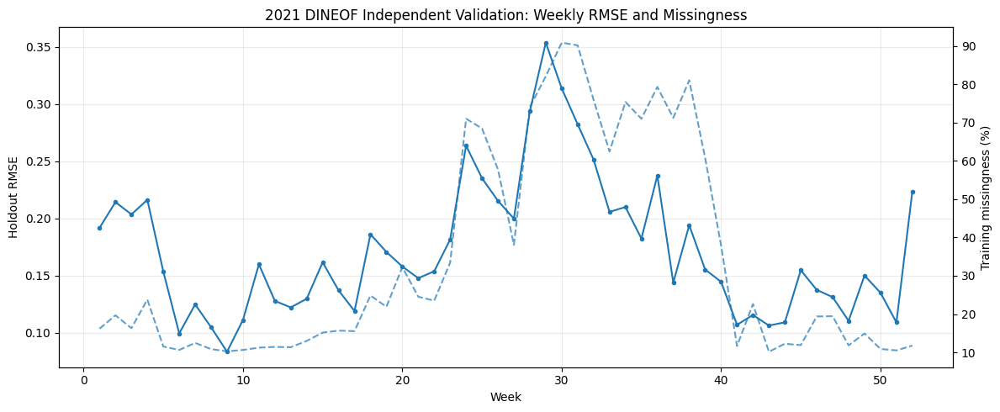


Saved CSV: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Independent_Validation/2021_Task3_Weekly_Validation_Metrics.csv
Saved figure: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Independent_Validation/2021_Task3_Weekly_RMSE_vs_Missingness.png

TASK 3 — STEP 16 COMPLETE


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

print("=== TASK 3 — STEP 16: WEEKLY VALIDATION ===")

# Reload saved files
with np.load(validation_dir / "2021_Task3_Independent_DINEOF_R36_Seed2021.npz") as f:
    prediction = f["reconstructed_aod"]

with np.load(validation_dir / "2021_Task3_Holdout_10percent_Seed2021.npz") as f:
    holdout_mask = f["holdout_mask"]
    holdout_true = f["holdout_true"]
    train_data = f["training_aod"]
    domain = f["final_domain_mask"]

# Recover withheld values in flattened mask order
assert holdout_true.ndim == 1
assert holdout_true.size == holdout_mask.sum()

truth_3d = np.full(holdout_mask.shape, np.nan, dtype=np.float32)
truth_3d[holdout_mask] = holdout_true

records = []
domain_pixels = int(domain.sum())

for t in range(52):
    mask = holdout_mask[t]
    y = truth_3d[t][mask].astype(np.float64)
    p = prediction[t][mask].astype(np.float64)

    assert np.isfinite(y).all()
    assert np.isfinite(p).all()

    err = p - y

    training_count = int(np.isfinite(train_data[t][domain]).sum())

    records.append({
        "Week": t + 1,
        "N_Holdout": len(y),
        "Training_Observations": training_count,
        "Training_Missing_Percent": 100 * (1 - training_count / domain_pixels),
        "RMSE": np.sqrt(np.mean(err**2)),
        "MAE": np.mean(np.abs(err)),
        "Bias": np.mean(err),
        "Pearson_r": np.corrcoef(y, p)[0, 1] if np.std(y) > 0 and np.std(p) > 0 else np.nan,
        "R2": r2_score(y, p) if len(y) > 1 else np.nan
    })

weekly_metrics = pd.DataFrame(records)

csv_path = validation_dir / "2021_Task3_Weekly_Validation_Metrics.csv"
weekly_metrics.to_csv(csv_path, index=False)

print("\n=== WEEKLY VALIDATION RESULTS ===")
print(weekly_metrics.round(4).to_string(index=False))

print("\nHighest RMSE weeks:")
print(
    weekly_metrics.nlargest(
        5, "RMSE"
    )[["Week", "N_Holdout", "Training_Missing_Percent", "RMSE", "R2"]]
    .round(4).to_string(index=False)
)

# Plot weekly RMSE and training missingness
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(
    weekly_metrics["Week"],
    weekly_metrics["RMSE"],
    marker="o",
    markersize=3,
    label="Holdout RMSE"
)

ax1.set_xlabel("Week")
ax1.set_ylabel("Holdout RMSE")
ax1.grid(alpha=0.25)

ax2 = ax1.twinx()
ax2.plot(
    weekly_metrics["Week"],
    weekly_metrics["Training_Missing_Percent"],
    linestyle="--",
    alpha=0.7,
    label="Training missingness"
)

ax2.set_ylabel("Training missingness (%)")

ax1.set_title("2021 DINEOF Independent Validation: Weekly RMSE and Missingness")

fig.tight_layout()

figure_path = validation_dir / "2021_Task3_Weekly_RMSE_vs_Missingness.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved CSV:", csv_path)
print("Saved figure:", figure_path)
print("\nTASK 3 — STEP 16 COMPLETE")


=== TASK 3 — STEP 17: MISSINGNESS STRATIFICATION ===

=== VALIDATION BY MISSINGNESS LEVEL ===
Missingness_Group  Number_of_Weeks  Mean_Weekly_RMSE  Median_Weekly_RMSE  Mean_Weekly_MAE  Mean_Weekly_R2  Total_Holdout_Observations
            0–20%               27            0.1376              0.1296           0.0962          0.7720                      145239
           20–40%               10            0.1673              0.1642           0.1191          0.6859                       44778
           40–60%                1            0.2154              0.2154           0.1548          0.6492                        2631
           60–80%               10            0.2178              0.2225           0.1569          0.5429                       18217
          80–100%                4            0.2860              0.2980           0.2069          0.5115                        3426

=== ASSOCIATION WITH MISSINGNESS ===
Pearson r:  0.7720, p = 2.071e-11
Spearman rho: 0.7878, p = 4.24

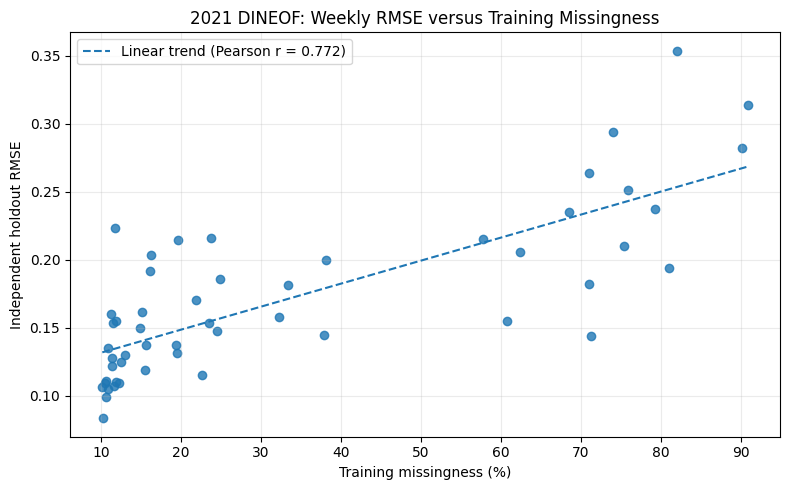


Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Independent_Validation/2021_Task3_Missingness_Stratified_Summary.csv
Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Independent_Validation/2021_Task3_RMSE_vs_Missingness_Scatter.png

TASK 3 — STEP 17 COMPLETE


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

print("=== TASK 3 — STEP 17: MISSINGNESS STRATIFICATION ===")

# Load previously saved weekly validation metrics
weekly_metrics = pd.read_csv(
    validation_dir / "2021_Task3_Weekly_Validation_Metrics.csv"
)

# Assign each week to a missingness category
bins = [0, 20, 40, 60, 80, 100]
labels = ["0–20%", "20–40%", "40–60%", "60–80%", "80–100%"]

weekly_metrics["Missingness_Group"] = pd.cut(
    weekly_metrics["Training_Missing_Percent"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Summary by missingness category
summary = (
    weekly_metrics
    .groupby("Missingness_Group", observed=False)
    .agg(
        Number_of_Weeks=("Week", "count"),
        Mean_Weekly_RMSE=("RMSE", "mean"),
        Median_Weekly_RMSE=("RMSE", "median"),
        Mean_Weekly_MAE=("MAE", "mean"),
        Mean_Weekly_R2=("R2", "mean"),
        Total_Holdout_Observations=("N_Holdout", "sum")
    )
    .reset_index()
)

print("\n=== VALIDATION BY MISSINGNESS LEVEL ===")
print(summary.round(4).to_string(index=False))

# Correlation between weekly missingness and RMSE
x = weekly_metrics["Training_Missing_Percent"].to_numpy()
y = weekly_metrics["RMSE"].to_numpy()

pearson_r, pearson_p = pearsonr(x, y)
spearman_r, spearman_p = spearmanr(x, y)

print("\n=== ASSOCIATION WITH MISSINGNESS ===")
print(f"Pearson r:  {pearson_r:.4f}, p = {pearson_p:.4g}")
print(f"Spearman rho: {spearman_r:.4f}, p = {spearman_p:.4g}")

# Save results
summary_path = validation_dir / (
    "2021_Task3_Missingness_Stratified_Summary.csv"
)
summary.to_csv(summary_path, index=False)

# Scatter plot
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(x, y, alpha=0.8)

# Descriptive linear trend only
slope, intercept = np.polyfit(x, y, 1)
xx = np.linspace(x.min(), x.max(), 100)

ax.plot(
    xx,
    slope * xx + intercept,
    linestyle="--",
    label=f"Linear trend (Pearson r = {pearson_r:.3f})"
)

ax.set_xlabel("Training missingness (%)")
ax.set_ylabel("Independent holdout RMSE")
ax.set_title("2021 DINEOF: Weekly RMSE versus Training Missingness")
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

figure_path = validation_dir / (
    "2021_Task3_RMSE_vs_Missingness_Scatter.png"
)

fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved:", summary_path)
print("Saved:", figure_path)
print("\nTASK 3 — STEP 17 COMPLETE")


=== TASK 3 — STEP 18: AOD MAGNITUDE VALIDATION ===

=== VALIDATION BY OBSERVED AOD ===
AOD_Group     N    RMSE     MAE     Bias  Observed_Mean  Predicted_Mean
     <0.2 21143 0.12322 0.08884  0.06031        0.12836         0.18867
  0.2–0.5 81326 0.11733 0.08450  0.03811        0.35796         0.39607
  0.5–1.0 90655 0.13927 0.10361 -0.00818        0.70036         0.69218
  1.0–1.5 17986 0.24957 0.19307 -0.13732        1.17524         1.03793
     >1.5  3181 0.59981 0.47440 -0.45037        1.80901         1.35864


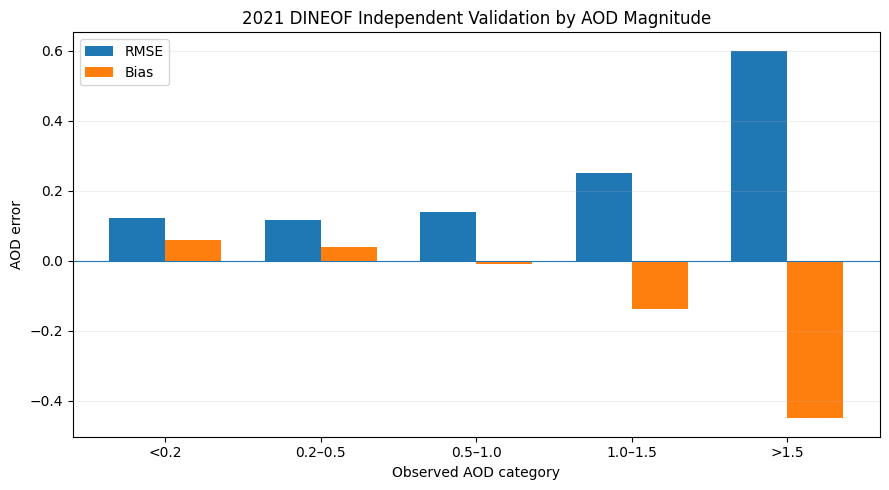


Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Independent_Validation/2021_Task3_AOD_Magnitude_Validation.csv
Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Independent_Validation/2021_Task3_AOD_Magnitude_Validation.png

TASK 3 — STEP 18 COMPLETE


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=== TASK 3 — STEP 18: AOD MAGNITUDE VALIDATION ===")

with np.load(validation_dir / "2021_Task3_Independent_DINEOF_R36_Seed2021.npz") as f:
    prediction = f["reconstructed_aod"]

with np.load(validation_dir / "2021_Task3_Holdout_10percent_Seed2021.npz") as f:
    holdout_mask = f["holdout_mask"]
    holdout_true = f["holdout_true"]

observed = np.asarray(holdout_true, dtype=np.float64)
predicted = np.asarray(prediction[holdout_mask], dtype=np.float64)

assert observed.size == predicted.size == 214291
assert np.isfinite(observed).all()
assert np.isfinite(predicted).all()

errors = predicted - observed

# Define AOD groups using observed values
bins = [-np.inf, 0.2, 0.5, 1.0, 1.5, np.inf]
labels = ["<0.2", "0.2–0.5", "0.5–1.0", "1.0–1.5", ">1.5"]

df = pd.DataFrame({
    "Observed_AOD": observed,
    "Predicted_AOD": predicted,
    "Error": errors
})

df["AOD_Group"] = pd.cut(
    df["Observed_AOD"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

records = []

for group, sub in df.groupby("AOD_Group", observed=False):
    if len(sub) == 0:
        continue

    e = sub["Error"].to_numpy()

    records.append({
        "AOD_Group": str(group),
        "N": len(sub),
        "RMSE": np.sqrt(np.mean(e**2)),
        "MAE": np.mean(np.abs(e)),
        "Bias": np.mean(e),
        "Observed_Mean": sub["Observed_AOD"].mean(),
        "Predicted_Mean": sub["Predicted_AOD"].mean()
    })

summary = pd.DataFrame(records)

print("\n=== VALIDATION BY OBSERVED AOD ===")
print(summary.round(5).to_string(index=False))

csv_path = validation_dir / (
    "2021_Task3_AOD_Magnitude_Validation.csv"
)
summary.to_csv(csv_path, index=False)

# Plot RMSE and bias by observed AOD category
fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(summary))
width = 0.36

ax.bar(
    x - width / 2,
    summary["RMSE"],
    width,
    label="RMSE"
)

ax.bar(
    x + width / 2,
    summary["Bias"],
    width,
    label="Bias"
)

ax.axhline(0, linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(summary["AOD_Group"])
ax.set_xlabel("Observed AOD category")
ax.set_ylabel("AOD error")
ax.set_title("2021 DINEOF Independent Validation by AOD Magnitude")
ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()

figure_path = validation_dir / (
    "2021_Task3_AOD_Magnitude_Validation.png"
)
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("\nSaved:", csv_path)
print("Saved:", figure_path)
print("\nTASK 3 — STEP 18 COMPLETE")


In [ ]:

import numpy as np
from pathlib import Path

print("=== TASK 3 — STEP 19: HOLDOUT ALIGNMENT CHECK ===")

# Original factor-2, cropped and masked data from the
# completed 2021 preprocessing must be available as 'original'.
# This test deliberately does not substitute reconstructed data.

if "original" not in globals():
    print("Original preprocessed MODIS array is not loaded.")
    print("We must reload it from the original MODIS source.")
    print("No alignment conclusion can be made yet.")

else:
    original_array = np.asarray(original)

    with np.load(
        validation_dir / "2021_Task3_Holdout_10percent_Seed2021.npz"
    ) as f:
        mask = f["holdout_mask"]
        truth = f["holdout_true"]

    assert original_array.shape == mask.shape
    assert truth.ndim == 1
    assert truth.size == int(mask.sum())

    source_truth = original_array[mask]

    assert np.isfinite(source_truth).all()

    differences = np.abs(
        source_truth.astype(np.float64)
        - truth.astype(np.float64)
    )

    print("Compared observations:", differences.size)
    print("Maximum absolute difference:", differences.max())
    print("Mean absolute difference:", differences.mean())
    print("Exact matches:", int(np.sum(differences == 0)))

    assert np.allclose(
        source_truth,
        truth,
        rtol=0,
        atol=1e-6
    ), "Holdout truth does not match original MODIS values."

    print("\nHOLDOUT ALIGNMENT VERIFIED")
    print("TASK 3 — STEP 19 PASSED")


=== TASK 3 — STEP 19: HOLDOUT ALIGNMENT CHECK ===
Compared observations: 214291
Maximum absolute difference: 2.2794120013713837e-07
Mean absolute difference: 1.2260232209233673e-08
Exact matches: 222

HOLDOUT ALIGNMENT VERIFIED
TASK 3 — STEP 19 PASSED


=== TASK 3 — STEP 20: SPATIAL ERROR MAPS ===


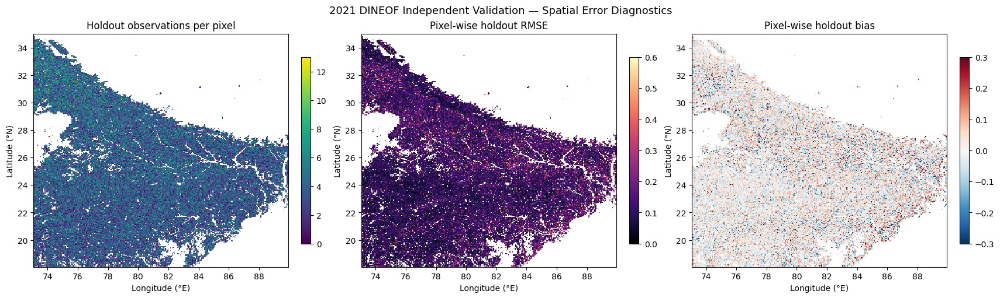


=== SPATIAL VALIDATION SUMMARY ===
Pixels with at least one holdout: 54888
Pixels with fewer than 3 holdouts: 13264
Median holdout count per retained pixel: 4.0
Median pixel-wise RMSE: 0.11171108616801012
Median pixel-wise bias: 0.002891561947762966

Saved figure: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Independent_Validation/2021_Task3_Spatial_Error_Maps.png
TASK 3 — STEP 20 COMPLETE


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("=== TASK 3 — STEP 20: SPATIAL ERROR MAPS ===")

with np.load(
    validation_dir / "2021_Task3_Independent_DINEOF_R36_Seed2021.npz"
) as f:
    prediction = f["reconstructed_aod"]

with np.load(
    validation_dir / "2021_Task3_Holdout_10percent_Seed2021.npz"
) as f:
    holdout_mask = f["holdout_mask"]
    holdout_true = f["holdout_true"]
    lat = f["lat"]
    lon = f["lon"]
    domain = f["final_domain_mask"]

# Reconstruct truth tensor using verified mask ordering
truth = np.full(prediction.shape, np.nan, dtype=np.float32)
truth[holdout_mask] = holdout_true

# Error = prediction minus observation
error = prediction.astype(np.float64) - truth.astype(np.float64)

# Number of withheld observations per pixel
count = holdout_mask.sum(axis=0)

# Accumulate errors without warnings from empty pixels
valid = holdout_mask & np.isfinite(error)
safe_error = np.where(valid, error, 0.0)

sum_error = safe_error.sum(axis=0)
sum_squared = (safe_error ** 2).sum(axis=0)

pixel_bias = np.full(count.shape, np.nan)
pixel_rmse = np.full(count.shape, np.nan)

np.divide(
    sum_error, count,
    out=pixel_bias,
    where=count > 0
)

np.divide(
    sum_squared, count,
    out=pixel_rmse,
    where=count > 0
)

pixel_rmse = np.sqrt(pixel_rmse)

# Exclude pixels outside the retained domain
pixel_bias[~domain] = np.nan
pixel_rmse[~domain] = np.nan

count_map = count.astype(float)
count_map[~domain] = np.nan

# Save numerical spatial diagnostics
np.savez_compressed(
    validation_dir / "2021_Task3_Spatial_Error_Diagnostics.npz",
    pixel_rmse=pixel_rmse.astype(np.float32),
    pixel_bias=pixel_bias.astype(np.float32),
    holdout_count=count,
    lat=lat,
    lon=lon,
    final_domain_mask=domain
)

# Plot spatial maps
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    constrained_layout=True
)

extent = [lon.min(), lon.max(), lat.min(), lat.max()]

maps = [
    (count_map, "Holdout observations per pixel", "viridis", None, None),
    (pixel_rmse, "Pixel-wise holdout RMSE", "magma", 0, 0.6),
    (pixel_bias, "Pixel-wise holdout bias", "RdBu_r", -0.3, 0.3)
]

for ax, (data, title, cmap, vmin, vmax) in zip(axes, maps):
    im = ax.imshow(
        data,
        origin="lower" if lat[0] < lat[-1] else "upper",
        extent=extent,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest",
        aspect="auto"
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")
    fig.colorbar(im, ax=ax, shrink=0.8)

fig.suptitle(
    "2021 DINEOF Independent Validation — Spatial Error Diagnostics",
    fontsize=13
)

figure_path = validation_dir / (
    "2021_Task3_Spatial_Error_Maps.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n=== SPATIAL VALIDATION SUMMARY ===")
print("Pixels with at least one holdout:", int(np.sum(count > 0)))
print("Pixels with fewer than 3 holdouts:", int(np.sum((count > 0) & (count < 3))))
print("Median holdout count per retained pixel:", np.median(count[domain]))
print("Median pixel-wise RMSE:", np.nanmedian(pixel_rmse))
print("Median pixel-wise bias:", np.nanmedian(pixel_bias))

print("\nSaved figure:", figure_path)
print("TASK 3 — STEP 20 COMPLETE")


In [ ]:

import numpy as np
import pandas as pd
from scipy.stats import pearsonr

print("=== TASK 3 — STEP 21: REGIONAL VALIDATION ===")

with np.load(
    validation_dir / "2021_Task3_Independent_DINEOF_R36_Seed2021.npz"
) as f:
    prediction = f["reconstructed_aod"]

with np.load(
    validation_dir / "2021_Task3_Holdout_10percent_Seed2021.npz"
) as f:
    holdout_mask = f["holdout_mask"]
    holdout_true = f["holdout_true"]
    lat = f["lat"]
    lon = f["lon"]
    domain = f["final_domain_mask"]

assert holdout_true.size == int(holdout_mask.sum())

# Coordinates of retained land pixels
lat_grid, lon_grid = np.meshgrid(lat, lon, indexing="ij")

lat_mid = np.median(lat_grid[domain])
lon_mid = np.median(lon_grid[domain])

print("Latitude dividing line:", round(lat_mid, 4))
print("Longitude dividing line:", round(lon_mid, 4))

# Geographic regions
regions = {
    "Northwest": (lat_grid >= lat_mid) & (lon_grid < lon_mid),
    "Northeast": (lat_grid >= lat_mid) & (lon_grid >= lon_mid),
    "Southwest": (lat_grid < lat_mid) & (lon_grid < lon_mid),
    "Southeast": (lat_grid < lat_mid) & (lon_grid >= lon_mid)
}

# Restore withheld truth to original mask positions
truth = np.full(prediction.shape, np.nan, dtype=np.float32)
truth[holdout_mask] = holdout_true

records = []

for name, region in regions.items():
    region = region & domain
    selected = holdout_mask & region[None, :, :]

    y = truth[selected].astype(np.float64)
    p = prediction[selected].astype(np.float64)

    assert np.isfinite(y).all()
    assert np.isfinite(p).all()

    error = p - y

    records.append({
        "Region": name,
        "Retained_Pixels": int(region.sum()),
        "Holdout_N": len(y),
        "RMSE": np.sqrt(np.mean(error**2)),
        "MAE": np.mean(np.abs(error)),
        "Bias": np.mean(error),
        "Pearson_r": pearsonr(y, p)[0] if len(y) > 2 else np.nan,
        "Observed_Mean_AOD": np.mean(y),
        "Predicted_Mean_AOD": np.mean(p)
    })

regional_df = pd.DataFrame(records)

print("\n=== REGIONAL VALIDATION RESULTS ===")
print(regional_df.round(5).to_string(index=False))

# Integrity check: all holdout samples must be accounted for
assert regional_df["Holdout_N"].sum() == 214291

csv_path = validation_dir / (
    "2021_Task3_Regional_Validation.csv"
)

regional_df.to_csv(csv_path, index=False)

print("\nSaved:", csv_path)
print("TASK 3 — STEP 21 COMPLETE")


=== TASK 3 — STEP 21: REGIONAL VALIDATION ===
Latitude dividing line: 24.4155
Longitude dividing line: 79.3695

=== REGIONAL VALIDATION RESULTS ===
   Region  Retained_Pixels  Holdout_N    RMSE     MAE     Bias  Pearson_r  Observed_Mean_AOD  Predicted_Mean_AOD
Northwest            14771      62415 0.16168 0.10783 -0.00168    0.87717            0.54262             0.54095
Northeast            13194      50212 0.17766 0.12032 -0.00162    0.88841            0.67091             0.66930
Southwest            13172      48045 0.12589 0.08747 -0.00115    0.87418            0.51458             0.51343
Southeast            14781      53619 0.16645 0.11471 -0.00052    0.84895            0.55820             0.55768

Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Independent_Validation/2021_Task3_Regional_Validation.csv
TASK 3 — STEP 21 COMPLETE


In [ ]:

import numpy as np
import pandas as pd

print("=== TASK 3 — STEP 22: REPEATED HOLDOUT PREPARATION ===")

# Use the verified original preprocessed MODIS array
assert "original" in globals(), (
    "Original MODIS array must be restored before creating new splits."
)

source = np.asarray(original)

assert source.shape == (52, 315, 314)

# Eligible observed positions
eligible = np.flatnonzero(np.isfinite(source.ravel()))

assert eligible.size == 2142906

records = []

for seed in [2022, 2023]:

    rng = np.random.default_rng(seed)

    selected = rng.choice(
        eligible,
        size=214291,
        replace=False
    )

    holdout = np.zeros(source.size, dtype=bool)
    holdout[selected] = True
    holdout = holdout.reshape(source.shape)

    # Save truth in Boolean-mask order
    truth = source[holdout].astype(np.float32)

    training = source.copy().astype(np.float32)
    training[holdout] = np.nan

    assert truth.size == 214291
    assert np.isfinite(training).sum() == 1928615
    assert not np.isfinite(training[holdout]).any()

    output_path = validation_dir / (
        f"2021_Task3_Holdout_10percent_Seed{seed}.npz"
    )

    np.savez_compressed(
        output_path,
        training_aod=training,
        holdout_mask=holdout,
        holdout_true=truth,
        lat=lat_2021,
        lon=lon_2021,
        final_domain_mask=domain,
        random_seed=np.int32(seed),
        holdout_fraction=np.float32(0.10)
    )

    records.append({
        "Seed": seed,
        "Training_N": int(np.isfinite(training).sum()),
        "Holdout_N": int(holdout.sum()),
        "Saved_File": str(output_path)
    })

summary = pd.DataFrame(records)

print("\n=== NEW HOLDOUT SPLITS ===")
print(summary.to_string(index=False))

print("\nTASK 3 — STEP 22 PASSED")


=== TASK 3 — STEP 22: REPEATED HOLDOUT PREPARATION ===

=== NEW HOLDOUT SPLITS ===
 Seed  Training_N  Holdout_N                                                                                                                           Saved_File
 2022     1928615     214291 /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Independent_Validation/2021_Task3_Holdout_10percent_Seed2022.npz
 2023     1928615     214291 /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Independent_Validation/2021_Task3_Holdout_10percent_Seed2023.npz

TASK 3 — STEP 22 PASSED


In [ ]:

import numpy as np
import pandas as pd
import time
from model.dineof3 import DINEOF3

print("=== TASK 3 — STEP 23: REPEATED-SEED VALIDATION ===")

mask_path = validation_dir / (
    "2021_Task3_DINEOF_Spatial_Mask_2D_Seed2021.npy"
)

assert np.load(mask_path).shape == (315, 314)

results = []

for seed in [2022, 2023]:

    print(f"\n=== SEED {seed} ===")

    holdout_path = validation_dir / (
        f"2021_Task3_Holdout_10percent_Seed{seed}.npz"
    )

    with np.load(holdout_path) as data:
        training = data["training_aod"]
        holdout = data["holdout_mask"]
        truth = data["holdout_true"]

    # Convert to (latitude, longitude, time)
    tensor = np.moveaxis(training, 0, -1)

    # Training observations only
    valid = np.isfinite(tensor)

    X = np.column_stack(np.where(valid)).astype(np.int32)
    y = tensor[valid].astype(np.float64)

    assert X.shape == (1928615, 3)
    assert y.shape == (1928615,)
    assert int(holdout.sum()) == 214291

    holdout_tensor = np.moveaxis(holdout, 0, -1)

    assert not np.any(
        holdout_tensor[X[:, 0], X[:, 1], X[:, 2]]
    )

    model = DINEOF3(
        R=36,
        tensor_shape=(315, 314, 52),
        mask=str(mask_path),
        decomp_type="PARAFAC",
        td_iter_max=100,
        nitemax=300,
        toliter=0.001,
        tol=1e-8,
        to_center=True,
        keep_non_negative_only=True,
        with_energy=False,
        lat_lon_sep_centering=True,
        early_stopping=True
    )

    start = time.time()

    print("Starting independent reconstruction...")
    model.fit(X, y)

    elapsed = time.time() - start

    reconstructed = np.moveaxis(
        np.asarray(model.reconstructed_tensor, dtype=np.float32),
        -1, 0
    )

    assert reconstructed.shape == (52, 315, 314)

    # Save reconstruction immediately
    output_path = validation_dir / (
        f"2021_Task3_Independent_DINEOF_R36_Seed{seed}.npz"
    )

    np.savez_compressed(
        output_path,
        reconstructed_aod=reconstructed,
        rank=np.int32(36),
        random_seed=np.int32(seed),
        elapsed_seconds=np.float64(elapsed),
        final_iteration=np.int32(model.final_iter)
    )

    # Independent holdout evaluation
    observed = truth.astype(np.float64)
    predicted = reconstructed[holdout].astype(np.float64)

    assert len(observed) == len(predicted) == 214291
    assert np.isfinite(predicted).all()

    error = predicted - observed

    rmse = np.sqrt(np.mean(error**2))
    mae = np.mean(np.abs(error))
    bias = np.mean(error)
    r = np.corrcoef(observed, predicted)[0, 1]
    r2 = 1 - np.sum(error**2) / np.sum(
        (observed - observed.mean())**2
    )

    results.append({
        "Seed": seed,
        "N_Holdout": len(observed),
        "RMSE": rmse,
        "MAE": mae,
        "Bias": bias,
        "Pearson_r": r,
        "R2": r2,
        "Runtime_Minutes": elapsed / 60
    })

    # Save progress after each seed
    pd.DataFrame(results).to_csv(
        validation_dir / "2021_Task3_Repeated_Seed_Metrics.csv",
        index=False
    )

    print(f"Seed {seed} completed.")
    print(f"RMSE: {rmse:.6f}")
    print(f"MAE: {mae:.6f}")
    print(f"Bias: {bias:.6f}")
    print(f"Pearson r: {r:.6f}")
    print(f"R2: {r2:.6f}")
    print(f"Runtime: {elapsed/60:.2f} minutes")

print("\n=== REPEATED-SEED VALIDATION RESULTS ===")
print(pd.DataFrame(results).round(6).to_string(index=False))

print("\nTASK 3 — STEP 23 COMPLETE")


=== TASK 3 — STEP 23: REPEATED-SEED VALIDATION ===

=== SEED 2022 ===
Starting independent reconstruction...


Reconstruction:  11%|█▏        | 34/300 [14:41<1:54:59, 25.94s/it, error=0.095, rel_error=0.000789]


Seed 2022 completed.
RMSE: 0.159638
MAE: 0.108159
Bias: -0.001232
Pearson r: 0.878046
R2: 0.770895
Runtime: 14.85 minutes

=== SEED 2023 ===
Starting independent reconstruction...


Reconstruction:   1%|▏         | 4/300 [02:04<2:33:26, 31.10s/it, error=0.106, rel_error=0.000923]


Seed 2023 completed.
RMSE: 0.161200
MAE: 0.108230
Bias: -0.001789
Pearson r: 0.876125
R2: 0.767559
Runtime: 2.16 minutes

=== REPEATED-SEED VALIDATION RESULTS ===
 Seed  N_Holdout     RMSE      MAE      Bias  Pearson_r       R2  Runtime_Minutes
 2022     214291 0.159638 0.108159 -0.001232   0.878046 0.770895        14.853977
 2023     214291 0.161200 0.108230 -0.001789   0.876125 0.767559         2.161268

TASK 3 — STEP 23 COMPLETE


In [ ]:

from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

validation_dir = Path(
    "/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/"
    "2021/2021_Task3_Independent_Validation"
)

print("=== TASK 3 RECOVERY CHECK ===")

files = [
    "2021_Task3_Independent_Validation_Metrics.csv",
    "2021_Task3_Repeated_Seed_Metrics.csv",
    "2021_Task3_Independent_DINEOF_R36_Seed2021.npz",
    "2021_Task3_Independent_DINEOF_R36_Seed2022.npz",
    "2021_Task3_Independent_DINEOF_R36_Seed2023.npz"
]

for filename in files:
    status = "FOUND" if (validation_dir / filename).exists() else "MISSING"
    print(f"{status}: {filename}")

print("\nRecovery check completed.")


Mounted at /content/drive
=== TASK 3 RECOVERY CHECK ===
FOUND: 2021_Task3_Independent_Validation_Metrics.csv
FOUND: 2021_Task3_Repeated_Seed_Metrics.csv
FOUND: 2021_Task3_Independent_DINEOF_R36_Seed2021.npz
FOUND: 2021_Task3_Independent_DINEOF_R36_Seed2022.npz
FOUND: 2021_Task3_Independent_DINEOF_R36_Seed2023.npz

Recovery check completed.


In [ ]:

import numpy as np
import pandas as pd

print("=== TASK 3 — STEP 24: REPEATED-SEED SUMMARY ===")

# Load previously saved validation metrics
first = pd.read_csv(
    validation_dir / "2021_Task3_Independent_Validation_Metrics.csv"
)

repeated = pd.read_csv(
    validation_dir / "2021_Task3_Repeated_Seed_Metrics.csv"
)

print("\nSeed 2021 columns:", first.columns.tolist())
print("Repeated-seed columns:", repeated.columns.tolist())

# Standardize common metric column names
def standardize(df):
    df = df.copy()
    df.columns = df.columns.str.strip()

    rename = {
        "Random_Seed": "Seed",
        "random_seed": "Seed",
        "Holdout_N": "N_Holdout",
        "Holdout_Count": "N_Holdout",
        "Bias_Predicted_Minus_Observed": "Bias",
        "Pearson_R": "Pearson_r",
        "Pearson_r": "Pearson_r",
        "R_squared": "R2",
        "R_squared_score": "R2",
        "R²": "R2"
    }
    return df.rename(columns=rename)

first = standardize(first)
repeated = standardize(repeated)

metrics = ["RMSE", "MAE", "Bias", "Pearson_r", "R2"]

# Seed 2021 is known from the completed independent validation
# Use the saved file as the source of its metrics.
if "Seed" not in first.columns:
    first["Seed"] = 2021

combined = pd.concat(
    [first, repeated],
    ignore_index=True
)

combined = combined.sort_values("Seed").reset_index(drop=True)

assert combined["Seed"].astype(int).tolist() == [2021, 2022, 2023]

print("\n=== ALL THREE VALIDATION SEEDS ===")
print(combined[["Seed"] + metrics].round(6).to_string(index=False))

summary = pd.DataFrame({
    "Metric": metrics,
    "Mean": [combined[m].mean() for m in metrics],
    "SD": [combined[m].std(ddof=1) for m in metrics],
    "Minimum": [combined[m].min() for m in metrics],
    "Maximum": [combined[m].max() for m in metrics]
})

print("\n=== FINAL REPEATED-SEED STATISTICS ===")
print(summary.round(6).to_string(index=False))

combined.to_csv(
    validation_dir / "2021_Task3_All_Seed_Metrics.csv",
    index=False
)

summary.to_csv(
    validation_dir / "2021_Task3_Repeated_Seed_Summary.csv",
    index=False
)

print("\nTASK 3 — STEP 24 COMPLETE")


=== TASK 3 — STEP 24: REPEATED-SEED SUMMARY ===

Seed 2021 columns: ['Year', 'Method', 'Seed', 'N_Holdout', 'RMSE', 'MAE', 'Bias_Predicted_Minus_Observed', 'Pearson_r', 'R2']
Repeated-seed columns: ['Seed', 'N_Holdout', 'RMSE', 'MAE', 'Bias', 'Pearson_r', 'R2', 'Runtime_Minutes']

=== ALL THREE VALIDATION SEEDS ===
 Seed     RMSE      MAE      Bias  Pearson_r       R2
 2021 0.159674 0.107913 -0.001256   0.878006 0.770850
 2022 0.159638 0.108159 -0.001232   0.878046 0.770895
 2023 0.161200 0.108230 -0.001789   0.876125 0.767559

=== FINAL REPEATED-SEED STATISTICS ===
   Metric      Mean       SD   Minimum   Maximum
     RMSE  0.160171 0.000892  0.159638  0.161200
      MAE  0.108101 0.000166  0.107913  0.108230
     Bias -0.001426 0.000315 -0.001789 -0.001232
Pearson_r  0.877392 0.001098  0.876125  0.878046
       R2  0.769768 0.001913  0.767559  0.770895

TASK 3 — STEP 24 COMPLETE


In [ ]:

import pandas as pd
import numpy as np

print("=== TASK 3 — STEP 25: FINAL VALIDATION REPORT ===")

summary = pd.read_csv(
    validation_dir / "2021_Task3_Repeated_Seed_Summary.csv"
)

regional = pd.read_csv(
    validation_dir / "2021_Task3_Regional_Validation.csv"
)

weekly = pd.read_csv(
    validation_dir / "2021_Task3_Weekly_Validation_Metrics.csv"
)

aod = pd.read_csv(
    validation_dir / "2021_Task3_AOD_Magnitude_Validation.csv"
)

missingness = pd.read_csv(
    validation_dir / "2021_Task3_Missingness_Stratified_Summary.csv"
)

# Save a consolidated Excel workbook for scientific review
output = validation_dir / "2021_Task3_Final_Validation_Report.xlsx"

with pd.ExcelWriter(output, engine="openpyxl") as writer:
    summary.to_excel(
        writer, sheet_name="Repeated_Seed_Summary", index=False
    )
    regional.to_excel(
        writer, sheet_name="Regional_Validation", index=False
    )
    weekly.to_excel(
        writer, sheet_name="Weekly_Validation", index=False
    )
    aod.to_excel(
        writer, sheet_name="AOD_Magnitude", index=False
    )
    missingness.to_excel(
        writer, sheet_name="Missingness_Analysis", index=False
    )

print("\nSaved:", output)

print("\n=== REPORT CONTENTS ===")
print("1. Repeated-seed mean and standard deviation")
print("2. Regional reconstruction performance")
print("3. Weekly reconstruction performance")
print("4. AOD magnitude-dependent errors")
print("5. Missingness-dependent errors")

print("\nTASK 3 — STEP 25 COMPLETE")


=== TASK 3 — STEP 25: FINAL VALIDATION REPORT ===

Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Independent_Validation/2021_Task3_Final_Validation_Report.xlsx

=== REPORT CONTENTS ===
1. Repeated-seed mean and standard deviation
2. Regional reconstruction performance
3. Weekly reconstruction performance
4. AOD magnitude-dependent errors
5. Missingness-dependent errors

TASK 3 — STEP 25 COMPLETE


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

print("=== TASK 3 — STEP 26: FINAL VALIDATION AUDIT ===")

validation_dir = Path(
    "/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/"
    "2021/2021_Task3_Independent_Validation"
)

all_results = []
all_passed = True

for seed in [2021, 2022, 2023]:

    print(f"\n--- AUDITING SEED {seed} ---")

    holdout_file = validation_dir / (
        f"2021_Task3_Holdout_10percent_Seed{seed}.npz"
    )

    reconstruction_file = validation_dir / (
        f"2021_Task3_Independent_DINEOF_R36_Seed{seed}.npz"
    )

    with np.load(holdout_file) as data:
        training = data["training_aod"]
        holdout = data["holdout_mask"]
        truth = data["holdout_true"]
        domain = data["final_domain_mask"]

    with np.load(reconstruction_file) as data:
        prediction = data["reconstructed_aod"]

    checks = {
        "Shapes match":
            training.shape == holdout.shape == prediction.shape,

        "Expected dimensions":
            training.shape == (52, 315, 314),

        "Training count":
            np.isfinite(training).sum() == 1928615,

        "Holdout count":
            holdout.sum() == 214291,

        "Withheld data absent from training":
            np.isnan(training[holdout]).all(),

        "Holdout within retained domain":
            np.all(np.any(holdout, axis=0) <= domain),

        "Finite holdout observations":
            np.isfinite(truth).all(),

        "Finite withheld predictions":
            np.isfinite(prediction[holdout]).all(),

        "Truth and prediction lengths match":
            truth.size == prediction[holdout].size
    }

    for name, passed in checks.items():
        print(f"{'PASS' if passed else 'FAIL'}: {name}")

    passed_all = all(checks.values())
    all_passed = all_passed and passed_all

    if not passed_all:
        print("AUDIT FAILED — SKIPPING METRICS")
        continue

    observed = truth.astype(np.float64)
    predicted = prediction[holdout].astype(np.float64)

    errors = predicted - observed

    rmse = np.sqrt(np.mean(errors**2))
    mae = np.mean(np.abs(errors))
    bias = np.mean(errors)
    r = np.corrcoef(observed, predicted)[0, 1]
    r2 = 1 - (
        np.sum(errors**2) /
        np.sum((observed - observed.mean())**2)
    )

    all_results.append({
        "Seed": seed,
        "RMSE": rmse,
        "MAE": mae,
        "Bias": bias,
        "Pearson_r": r,
        "R2": r2,
        "Audit_Passed": passed_all
    })

    print(f"RMSE: {rmse:.6f}")
    print(f"MAE: {mae:.6f}")
    print(f"Bias: {bias:.6f}")
    print(f"Pearson r: {r:.6f}")
    print(f"R2: {r2:.6f}")

audit = pd.DataFrame(all_results)

if all_passed:
    output = validation_dir / "2021_Task3_Final_Audit.csv"
    audit.to_csv(output, index=False)

    print("\n=== FINAL AUDIT SUMMARY ===")
    print(audit.round(6).to_string(index=False))
    print("\nSaved:", output)
    print("\nTASK 3 — STEP 26 PASSED")
else:
    print("\nTASK 3 — STEP 26 REQUIRES INVESTIGATION")


=== TASK 3 — STEP 26: FINAL VALIDATION AUDIT ===

--- AUDITING SEED 2021 ---
PASS: Shapes match
PASS: Expected dimensions
PASS: Training count
PASS: Holdout count
PASS: Withheld data absent from training
PASS: Holdout within retained domain
PASS: Finite holdout observations
PASS: Finite withheld predictions
PASS: Truth and prediction lengths match
RMSE: 0.159674
MAE: 0.107913
Bias: -0.001256
Pearson r: 0.878006
R2: 0.770850

--- AUDITING SEED 2022 ---
PASS: Shapes match
PASS: Expected dimensions
PASS: Training count
PASS: Holdout count
PASS: Withheld data absent from training
PASS: Holdout within retained domain
PASS: Finite holdout observations
PASS: Finite withheld predictions
PASS: Truth and prediction lengths match
RMSE: 0.159638
MAE: 0.108159
Bias: -0.001232
Pearson r: 0.878046
R2: 0.770895

--- AUDITING SEED 2023 ---
PASS: Shapes match
PASS: Expected dimensions
PASS: Training count
PASS: Holdout count
PASS: Withheld data absent from training
PASS: Holdout within retained domain
P

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

print("=== TASK 4 — STEP 27: PCA/EOF DATA PREPARATION ===")

project_dir = Path(
    "/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021"
)

eof_dir = project_dir / "2021_Task4_PCA_EOF"
eof_dir.mkdir(parents=True, exist_ok=True)

# Use the final full-observation reconstruction, not a holdout model
reconstruction_file = Path(
    "/content/drive/MyDrive/"
    "DINEOF_2021_REVISED_BBOX_LANDMASK/"
    "MODIS_2021_DINEOF_Revised_Final.npz"
)

assert reconstruction_file.exists(), (
    f"Reconstruction file not found: {reconstruction_file}"
)

with np.load(reconstruction_file) as data:
    print("\nAvailable keys:", data.files)

    filled = data["aod"].astype(np.float32)
    raw_dineof = data["aod_dineof_raw"].astype(np.float32)
    lat = data["lat"]
    lon = data["lon"]
    domain_mask = data["final_domain_mask"].astype(bool)

assert filled.shape == (52, 315, 314)
assert raw_dineof.shape == filled.shape
assert domain_mask.shape == (315, 314)

# Only use retained land pixels with finite values in all 52 weeks
complete_mask = (
    domain_mask
    & np.isfinite(filled).all(axis=0)
    & np.isfinite(raw_dineof).all(axis=0)
)

n_domain = int(domain_mask.sum())
n_complete = int(complete_mask.sum())

print("\n=== DATASET DIAGNOSTICS ===")
print("AOD shape:", filled.shape)
print("Retained domain pixels:", n_domain)
print("Complete pixels:", n_complete)
print("Excluded pixels:", n_domain - n_complete)
print("Weeks:", filled.shape[0])

assert n_complete > 0

# Matrix orientation: time x space
X_filled = filled[:, complete_mask].astype(np.float64)
X_raw = raw_dineof[:, complete_mask].astype(np.float64)

print("\nFilled matrix:", X_filled.shape)
print("Raw DINEOF matrix:", X_raw.shape)

# Temporal centering separately at every spatial pixel
X_filled_centered = X_filled - X_filled.mean(axis=0)
X_raw_centered = X_raw - X_raw.mean(axis=0)

print("\nMaximum absolute temporal mean after centering:")
print("Filled:", np.abs(X_filled_centered.mean(axis=0)).max())
print("Raw:", np.abs(X_raw_centered.mean(axis=0)).max())

# Save masks and diagnostics, not large duplicate matrices
np.savez_compressed(
    eof_dir / "2021_Task4_EOF_Preparation.npz",
    lat=lat,
    lon=lon,
    domain_mask=domain_mask,
    complete_mask=complete_mask,
    n_weeks=np.int32(52)
)

print("\nSaved EOF preparation metadata.")
print("\nTASK 4 — STEP 27 COMPLETE")


=== TASK 4 — STEP 27: PCA/EOF DATA PREPARATION ===

Available keys: ['aod', 'aod_dineof_raw', 'lat', 'lon', 'land_mask', 'coverage_mask', 'final_domain_mask', 'dineof_rank', 'spatial_lambda', 'temporal_missing_threshold', 'aggregation_factor', 'bbox', 'description']

=== DATASET DIAGNOSTICS ===
AOD shape: (52, 315, 314)
Retained domain pixels: 55918
Complete pixels: 55918
Excluded pixels: 0
Weeks: 52

Filled matrix: (52, 55918)
Raw DINEOF matrix: (52, 55918)

Maximum absolute temporal mean after centering:
Filled: 1.0248212535001446e-16
Raw: 1.0248212535001446e-16

Saved EOF preparation metadata.

TASK 4 — STEP 27 COMPLETE


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

print("=== TASK 4 — STEP 28: EOF/PCA CALCULATION ===")

eof_dir = Path(
    "/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/"
    "2021/2021_Task4_PCA_EOF"
)

reconstruction_file = Path(
    "/content/drive/MyDrive/"
    "DINEOF_2021_REVISED_BBOX_LANDMASK/"
    "MODIS_2021_DINEOF_Revised_Final.npz"
)

with np.load(eof_dir / "2021_Task4_EOF_Preparation.npz") as f:
    mask = f["complete_mask"]
    lat = f["lat"]
    lon = f["lon"]

with np.load(reconstruction_file) as f:
    filled = f["aod"]
    raw = f["aod_dineof_raw"]

# Latitude-based area weights for a regular lat/lon grid
lat_grid = np.broadcast_to(lat[:, None], mask.shape)
weights = np.sqrt(np.cos(np.deg2rad(lat_grid[mask])))

assert np.all(np.isfinite(weights))
assert np.all(weights > 0)

def calculate_eof(cube, name):

    # Time x space
    X = cube[:, mask].astype(np.float64)

    # Center each pixel across 52 weeks
    pixel_mean = X.mean(axis=0)
    X_centered = X - pixel_mean

    # Weighted anomaly matrix
    X_weighted = X_centered * weights[None, :]

    # Efficient EOF via 52 x 52 temporal Gram matrix
    gram = X_weighted @ X_weighted.T

    eigenvalues, U = np.linalg.eigh(gram)

    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = np.maximum(eigenvalues[order], 0)
    U = U[:, order]

    singular_values = np.sqrt(eigenvalues)

    # Spatial weighted right singular vectors
    V = np.zeros((len(weights), len(singular_values)))

    valid = singular_values > (
        singular_values.max() * 1e-10
    )

    V[:, valid] = (
        X_weighted.T @ U[:, valid]
    ) / singular_values[valid]

    # Convert back to unweighted spatial EOFs
    spatial_eofs = V / weights[:, None]

    # Temporal principal components
    pcs = U * singular_values[None, :]

    explained_variance = (
        eigenvalues / eigenvalues.sum() * 100
    )

    # Deterministic sign convention for reproducibility
    for k in range(3):
        idx = np.argmax(np.abs(spatial_eofs[:, k]))
        if spatial_eofs[idx, k] < 0:
            spatial_eofs[:, k] *= -1
            pcs[:, k] *= -1

    # Save leading modes
    output = eof_dir / f"2021_Task4_EOF_{name}.npz"

    np.savez_compressed(
        output,
        spatial_eofs=spatial_eofs[:, :10].astype(np.float32),
        pcs=pcs[:, :10].astype(np.float32),
        explained_variance=explained_variance,
        eigenvalues=eigenvalues,
        weights=weights.astype(np.float32),
        complete_mask=mask,
        lat=lat,
        lon=lon
    )

    print(f"\n=== {name.upper()} ===")
    for k in range(5):
        print(
            f"EOF{k+1}: {explained_variance[k]:.3f}% "
            f"| Cumulative: "
            f"{explained_variance[:k+1].sum():.3f}%"
        )

    return explained_variance

ev_filled = calculate_eof(filled, "Regularized")
ev_raw = calculate_eof(raw, "Raw_DINEOF")

comparison = pd.DataFrame({
    "EOF_Mode": np.arange(1, 11),
    "Regularized_Explained_Percent": ev_filled[:10],
    "Raw_DINEOF_Explained_Percent": ev_raw[:10]
})

comparison.to_csv(
    eof_dir / "2021_Task4_Explained_Variance_Comparison.csv",
    index=False
)

print("\n=== EXPLAINED VARIANCE COMPARISON ===")
print(comparison.round(3).to_string(index=False))

print("\nTASK 4 — STEP 28 COMPLETE")


=== TASK 4 — STEP 28: EOF/PCA CALCULATION ===

=== REGULARIZED ===
EOF1: 27.238% | Cumulative: 27.238%
EOF2: 14.542% | Cumulative: 41.780%
EOF3: 6.940% | Cumulative: 48.720%
EOF4: 5.853% | Cumulative: 54.574%
EOF5: 4.522% | Cumulative: 59.096%

=== RAW_DINEOF ===
EOF1: 25.897% | Cumulative: 25.897%
EOF2: 14.470% | Cumulative: 40.367%
EOF3: 7.347% | Cumulative: 47.714%
EOF4: 5.831% | Cumulative: 53.545%
EOF5: 4.537% | Cumulative: 58.081%

=== EXPLAINED VARIANCE COMPARISON ===
 EOF_Mode  Regularized_Explained_Percent  Raw_DINEOF_Explained_Percent
        1                         27.238                        25.897
        2                         14.542                        14.470
        3                          6.940                         7.347
        4                          5.853                         5.831
        5                          4.522                         4.537
        6                          3.584                         3.773
        7              

=== TASK 5 — STEP 29: SPATIAL EOF MAPS ===


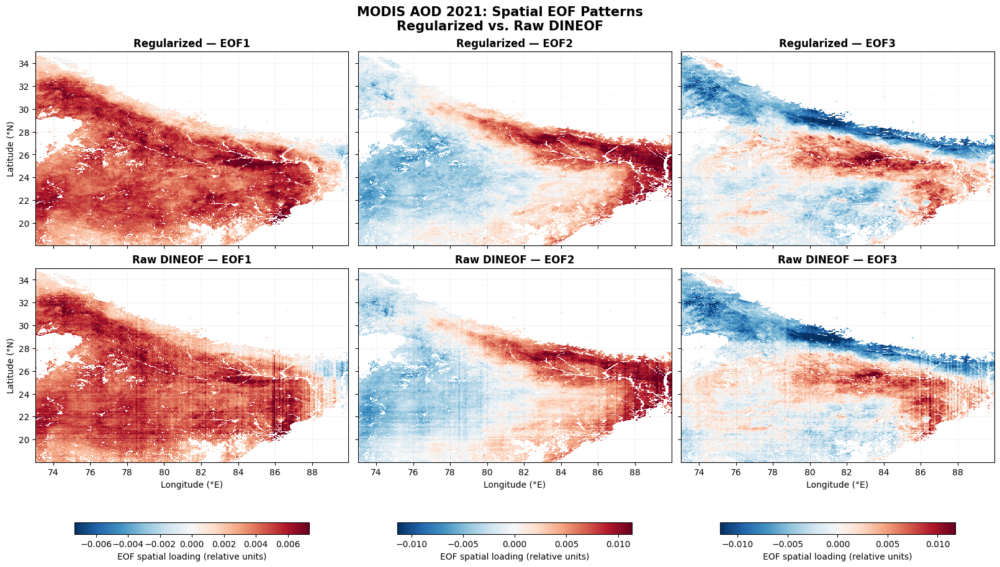


Saved PNG: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task4_PCA_EOF/2021_Task5_Spatial_EOF1_EOF2_EOF3.png
Saved PDF: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task4_PCA_EOF/2021_Task5_Spatial_EOF1_EOF2_EOF3.pdf

TASK 5 — STEP 29 COMPLETE


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from pathlib import Path

print("=== TASK 5 — STEP 29: SPATIAL EOF MAPS ===")

eof_dir = Path(
    "/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/"
    "2021/2021_Task4_PCA_EOF"
)

with np.load(eof_dir / "2021_Task4_EOF_Regularized.npz") as f:
    eof_reg = f["spatial_eofs"][:, :3]
    mask = f["complete_mask"]
    lat = f["lat"]
    lon = f["lon"]

with np.load(eof_dir / "2021_Task4_EOF_Raw_DINEOF.npz") as f:
    eof_raw = f["spatial_eofs"][:, :3]

# Align signs of corresponding modes for visual comparison.
# EOF signs are arbitrary.
for k in range(3):
    if np.dot(eof_reg[:, k], eof_raw[:, k]) < 0:
        eof_raw[:, k] *= -1

def to_map(values):
    grid = np.full(mask.shape, np.nan, dtype=float)
    grid[mask] = values
    return grid

fig, axes = plt.subplots(
    2, 3, figsize=(16, 9),
    sharex=True, sharey=True,
    constrained_layout=True
)

for k in range(3):

    reg_map = to_map(eof_reg[:, k])
    raw_map = to_map(eof_raw[:, k])

    # Same symmetric color scale for each paired mode
    vmax = np.nanpercentile(
        np.abs(np.concatenate([
            eof_reg[:, k], eof_raw[:, k]
        ])),
        99
    )

    norm = TwoSlopeNorm(
        vmin=-vmax, vcenter=0, vmax=vmax
    )

    for row, (grid, label) in enumerate([
        (reg_map, "Regularized"),
        (raw_map, "Raw DINEOF")
    ]):

        ax = axes[row, k]

        im = ax.pcolormesh(
            lon, lat, grid,
            shading="auto",
            cmap="RdBu_r",
            norm=norm,
            rasterized=True
        )

        ax.set_title(
            f"{label} — EOF{k+1}",
            fontsize=12,
            fontweight="bold"
        )

        ax.set_aspect("auto")
        ax.grid(alpha=0.15)

        if row == 1:
            ax.set_xlabel("Longitude (°E)")

        if k == 0:
            ax.set_ylabel("Latitude (°N)")

    fig.colorbar(
        im,
        ax=axes[:, k],
        orientation="horizontal",
        shrink=0.75,
        pad=0.07,
        label="EOF spatial loading (relative units)"
    )

fig.suptitle(
    "MODIS AOD 2021: Spatial EOF Patterns\n"
    "Regularized vs. Raw DINEOF",
    fontsize=15,
    fontweight="bold"
)

png = eof_dir / "2021_Task5_Spatial_EOF1_EOF2_EOF3.png"
pdf = eof_dir / "2021_Task5_Spatial_EOF1_EOF2_EOF3.pdf"

fig.savefig(png, dpi=600, bbox_inches="tight")
fig.savefig(pdf, bbox_inches="tight")

plt.show()
plt.close(fig)

print("\nSaved PNG:", png)
print("Saved PDF:", pdf)
print("\nTASK 5 — STEP 29 COMPLETE")


In [ ]:

import numpy as np
import pandas as pd

print("=== TASK 5 — STEP 30: EOF PATTERN SIMILARITY ===")

with np.load(eof_dir / "2021_Task4_EOF_Regularized.npz") as f:
    reg_eof = f["spatial_eofs"].astype(np.float64)
    reg_pc = f["pcs"].astype(np.float64)
    reg_weights = f["weights"].astype(np.float64)

with np.load(eof_dir / "2021_Task4_EOF_Raw_DINEOF.npz") as f:
    raw_eof = f["spatial_eofs"].astype(np.float64)
    raw_pc = f["pcs"].astype(np.float64)

assert reg_eof.shape == raw_eof.shape
assert reg_pc.shape == raw_pc.shape

def correlation(a, b):
    return float(np.corrcoef(a, b)[0, 1])

def weighted_cosine(a, b, w):
    x = a * w
    y = b * w
    return float(
        np.dot(x, y) /
        (np.linalg.norm(x) * np.linalg.norm(y))
    )

rows = []

for k in range(3):

    spatial_r = correlation(
        reg_eof[:, k], raw_eof[:, k]
    )

    weighted_similarity = weighted_cosine(
        reg_eof[:, k], raw_eof[:, k], reg_weights
    )

    temporal_r = correlation(
        reg_pc[:, k], raw_pc[:, k]
    )

    rows.append({
        "EOF_Mode": k + 1,
        "Spatial_Pearson_r": spatial_r,
        "Spatial_Abs_r": abs(spatial_r),
        "Area_Weighted_Abs_Cosine": abs(weighted_similarity),
        "Temporal_PC_r": temporal_r,
        "Temporal_PC_Abs_r": abs(temporal_r)
    })

results = pd.DataFrame(rows)

print("\n=== MATCHING EOF MODES ===")
print(results.round(5).to_string(index=False))

# Full cross-mode correlations reveal possible mode swapping
cross = np.zeros((3, 3))

for i in range(3):
    for j in range(3):
        cross[i, j] = abs(
            correlation(reg_eof[:, i], raw_eof[:, j])
        )

cross_df = pd.DataFrame(
    cross,
    index=["Reg_EOF1", "Reg_EOF2", "Reg_EOF3"],
    columns=["Raw_EOF1", "Raw_EOF2", "Raw_EOF3"]
)

print("\n=== ABSOLUTE CROSS-MODE SPATIAL CORRELATIONS ===")
print(cross_df.round(5).to_string())

results.to_csv(
    eof_dir / "2021_Task5_EOF_Pattern_Similarity.csv",
    index=False
)

cross_df.to_csv(
    eof_dir / "2021_Task5_EOF_Cross_Mode_Correlation.csv"
)

print("\nTASK 5 — STEP 30 COMPLETE")


=== TASK 5 — STEP 30: EOF PATTERN SIMILARITY ===

=== MATCHING EOF MODES ===
 EOF_Mode  Spatial_Pearson_r  Spatial_Abs_r  Area_Weighted_Abs_Cosine  Temporal_PC_r  Temporal_PC_Abs_r
        1            0.92313        0.92313                   0.98904        0.99632            0.99632
        2            0.97909        0.97909                   0.97805        0.99060            0.99060
        3           -0.94331        0.94331                   0.94316       -0.96111            0.96111

=== ABSOLUTE CROSS-MODE SPATIAL CORRELATIONS ===
          Raw_EOF1  Raw_EOF2  Raw_EOF3
Reg_EOF1   0.92313   0.28400   0.41502
Reg_EOF2   0.42731   0.97909   0.04778
Reg_EOF3   0.33812   0.05815   0.94331

TASK 5 — STEP 30 COMPLETE


=== TASK 6 — STEP 31: TEMPORAL PC ANALYSIS ===


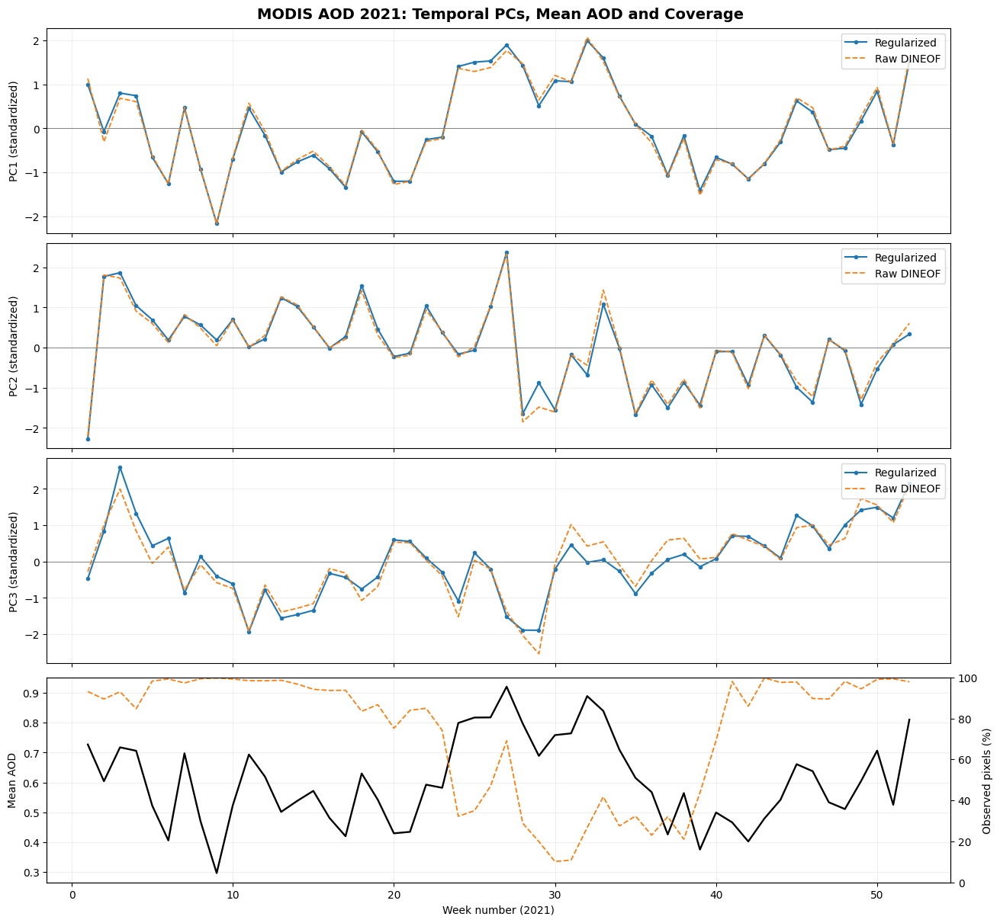


=== TEMPORAL PC CORRELATIONS ===
 PC  Correlation_With_Mean_AOD  Correlation_With_Coverage  Raw_vs_Regularized_PC_Correlation
  1                    0.98903                   -0.44456                            0.99632
  2                    0.09155                    0.38562                            0.99060
  3                   -0.08844                    0.26219                            0.96111

Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task4_PCA_EOF/2021_Task6_Temporal_PCs.png

TASK 6 — STEP 31 COMPLETE


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("=== TASK 6 — STEP 31: TEMPORAL PC ANALYSIS ===")

eof_dir = Path(
    "/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/"
    "2021/2021_Task4_PCA_EOF"
)

validation_dir = Path(
    "/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/"
    "2021/2021_Task3_Independent_Validation"
)

reconstruction_file = Path(
    "/content/drive/MyDrive/"
    "DINEOF_2021_REVISED_BBOX_LANDMASK/"
    "MODIS_2021_DINEOF_Revised_Final.npz"
)

with np.load(eof_dir / "2021_Task4_EOF_Regularized.npz") as f:
    pc_reg = f["pcs"][:, :3].astype(np.float64)
    mask = f["complete_mask"]

with np.load(eof_dir / "2021_Task4_EOF_Raw_DINEOF.npz") as f:
    pc_raw = f["pcs"][:, :3].astype(np.float64)

with np.load(reconstruction_file) as f:
    filled = f["aod"]

# Recover original observations from the saved holdout dataset.
# Training + withheld observations reconstruct the observed input.
with np.load(
    validation_dir / "2021_Task3_Holdout_10percent_Seed2021.npz"
) as f:
    original = f["training_aod"].copy()
    holdout = f["holdout_mask"]
    original[holdout] = f["holdout_true"]

# Observation fraction within the common retained domain
coverage = np.isfinite(original[:, mask]).mean(axis=1)

# Area-weighted domain mean reconstructed AOD
with np.load(eof_dir / "2021_Task4_EOF_Regularized.npz") as f:
    sqrt_area_weights = f["weights"].astype(np.float64)

area_weights = sqrt_area_weights**2
area_weights /= area_weights.sum()

mean_aod = (
    filled[:, mask].astype(np.float64) @ area_weights
)

# Align corresponding PC signs
for k in range(3):
    if np.corrcoef(pc_reg[:, k], pc_raw[:, k])[0, 1] < 0:
        pc_raw[:, k] *= -1

weeks = np.arange(1, 53)

fig, axes = plt.subplots(
    4, 1, figsize=(13, 12),
    sharex=True, constrained_layout=True
)

for k in range(3):
    # Standardize for shape comparison, not physical magnitude
    reg_z = pc_reg[:, k] / pc_reg[:, k].std(ddof=1)
    raw_z = pc_raw[:, k] / pc_raw[:, k].std(ddof=1)

    axes[k].plot(
        weeks, reg_z, "-o", markersize=3,
        label="Regularized", linewidth=1.5
    )
    axes[k].plot(
        weeks, raw_z, "--", linewidth=1.3,
        label="Raw DINEOF"
    )
    axes[k].axhline(0, color="gray", linewidth=0.7)
    axes[k].set_ylabel(f"PC{k+1} (standardized)")
    axes[k].legend(loc="upper right")
    axes[k].grid(alpha=0.2)

axes[3].plot(
    weeks, mean_aod, color="black",
    linewidth=1.7, label="Mean reconstructed AOD"
)
axes[3].set_ylabel("Mean AOD")
axes[3].set_xlabel("Week number (2021)")
axes[3].grid(alpha=0.2)

coverage_ax = axes[3].twinx()
coverage_ax.plot(
    weeks, coverage * 100,
    color="tab:orange", linestyle="--",
    linewidth=1.3, label="Original coverage"
)
coverage_ax.set_ylabel("Observed pixels (%)")
coverage_ax.set_ylim(0, 100)

fig.suptitle(
    "MODIS AOD 2021: Temporal PCs, Mean AOD and Coverage",
    fontsize=14, fontweight="bold"
)

output = eof_dir / "2021_Task6_Temporal_PCs.png"
fig.savefig(output, dpi=600, bbox_inches="tight")
plt.show()
plt.close(fig)

# Quantitative correlations
rows = []

for k in range(3):
    rows.append({
        "PC": k + 1,
        "Correlation_With_Mean_AOD":
            np.corrcoef(pc_reg[:, k], mean_aod)[0, 1],
        "Correlation_With_Coverage":
            np.corrcoef(pc_reg[:, k], coverage)[0, 1],
        "Raw_vs_Regularized_PC_Correlation":
            np.corrcoef(pc_reg[:, k], pc_raw[:, k])[0, 1]
    })

results = pd.DataFrame(rows)

print("\n=== TEMPORAL PC CORRELATIONS ===")
print(results.round(5).to_string(index=False))

results.to_csv(
    eof_dir / "2021_Task6_Temporal_PC_Correlations.csv",
    index=False
)

print("\nSaved:", output)
print("\nTASK 6 — STEP 31 COMPLETE")


=== TASK 6 — STEP 32: COVERAGE SENSITIVITY ===

=== COVERAGE CORRELATIONS ===
 PC  PC_Coverage_r  PC_Coverage_p  Partial_r_Control_Mean_AOD  Partial_p
  1       -0.44456        0.00096                    -0.21756    0.12130
  2        0.38562        0.00475                     0.46926    0.00045
  3        0.26219        0.06042                     0.24896    0.07512

=== OBSERVED VS RECONSTRUCTED WEEKLY MEAN ===
Pearson r: 0.95303
p-value: 1.3636e-27
Mean difference (reconstructed - observed): 0.01335


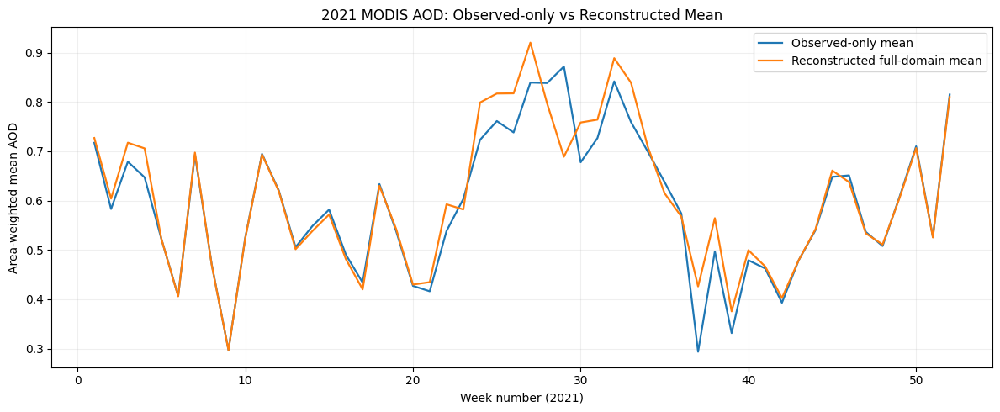


Saved: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task4_PCA_EOF/2021_Task6_Observed_vs_Reconstructed_Mean.png

TASK 6 — STEP 32 COMPLETE


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

print("=== TASK 6 — STEP 32: COVERAGE SENSITIVITY ===")

# Recover original observations
with np.load(
    validation_dir / "2021_Task3_Holdout_10percent_Seed2021.npz"
) as f:
    original = f["training_aod"].copy()
    holdout = f["holdout_mask"]
    original[holdout] = f["holdout_true"]

with np.load(
    eof_dir / "2021_Task4_EOF_Regularized.npz"
) as f:
    mask = f["complete_mask"]
    pcs = f["pcs"][:, :3].astype(float)
    w = f["weights"].astype(float)**2

with np.load(reconstruction_file) as f:
    reconstructed = f["aod"]

w = w / w.sum()

obs = original[:, mask].astype(float)
rec = reconstructed[:, mask].astype(float)

coverage = np.isfinite(obs).mean(axis=1)

reconstructed_mean = rec @ w

# Weekly area-weighted mean of available observations
observed_mean = np.array([
    np.average(
        obs[t, np.isfinite(obs[t])],
        weights=w[np.isfinite(obs[t])]
    )
    for t in range(52)
])

def partial_corr(x, y, control):
    A = np.column_stack([
        np.ones(len(control)),
        control
    ])
    rx = x - A @ np.linalg.lstsq(A, x, rcond=None)[0]
    ry = y - A @ np.linalg.lstsq(A, y, rcond=None)[0]
    return pearsonr(rx, ry)

rows = []

for k in range(3):
    r_cov, p_cov = pearsonr(pcs[:, k], coverage)
    r_partial, p_partial = partial_corr(
        pcs[:, k], coverage, reconstructed_mean
    )

    rows.append({
        "PC": k+1,
        "PC_Coverage_r": r_cov,
        "PC_Coverage_p": p_cov,
        "Partial_r_Control_Mean_AOD": r_partial,
        "Partial_p": p_partial
    })

results = pd.DataFrame(rows)

print("\n=== COVERAGE CORRELATIONS ===")
print(results.round(5).to_string(index=False))

mean_r, mean_p = pearsonr(
    observed_mean, reconstructed_mean
)

print("\n=== OBSERVED VS RECONSTRUCTED WEEKLY MEAN ===")
print(f"Pearson r: {mean_r:.5f}")
print(f"p-value: {mean_p:.5g}")
print(
    "Mean difference (reconstructed - observed):",
    f"{np.mean(reconstructed_mean-observed_mean):.5f}"
)

fig, ax = plt.subplots(figsize=(12, 5))

weeks = np.arange(1, 53)

ax.plot(
    weeks, observed_mean,
    label="Observed-only mean",
    linewidth=1.6
)
ax.plot(
    weeks, reconstructed_mean,
    label="Reconstructed full-domain mean",
    linewidth=1.6
)

ax.set_xlabel("Week number (2021)")
ax.set_ylabel("Area-weighted mean AOD")
ax.set_title(
    "2021 MODIS AOD: Observed-only vs Reconstructed Mean"
)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

output = eof_dir / "2021_Task6_Observed_vs_Reconstructed_Mean.png"

plt.savefig(output, dpi=600, bbox_inches="tight")
plt.show()
plt.close(fig)

results.to_csv(
    eof_dir / "2021_Task6_Coverage_Sensitivity.csv",
    index=False
)

print("\nSaved:", output)
print("\nTASK 6 — STEP 32 COMPLETE")


In [ ]:

import numpy as np
import pandas as pd

print("=== TASK 7 — STEP 33: ORIGINAL OBSERVATION SUPPORT ===")

with np.load(
    validation_dir / "2021_Task3_Holdout_10percent_Seed2021.npz"
) as f:
    original = f["training_aod"].copy()
    holdout = f["holdout_mask"]
    original[holdout] = f["holdout_true"]
    domain = f["final_domain_mask"]

# Number of genuinely observed weeks at each pixel
observation_count = np.isfinite(original).sum(axis=0)

thresholds = [20, 25, 30, 35, 40, 45, 50, 52]

rows = []

for threshold in thresholds:
    selected = domain & (observation_count >= threshold)

    rows.append({
        "Minimum_Observed_Weeks": threshold,
        "Eligible_Pixels": int(selected.sum()),
        "Percent_Of_Domain":
            100 * selected.sum() / domain.sum()
    })

summary = pd.DataFrame(rows)

print("\n=== OBSERVATION SUPPORT BY PIXEL ===")
print(summary.round(2).to_string(index=False))

# Completely observed pixels allow a direct EOF reference
complete_pixels = domain & (observation_count == 52)

print("\nFully observed pixels:", int(complete_pixels.sum()))

# Weekly coverage for high-observation pixels
for threshold in [35, 40, 45]:
    selected = domain & (observation_count >= threshold)

    if selected.sum() == 0:
        continue

    weekly_coverage = np.isfinite(
        original[:, selected]
    ).mean(axis=1)

    print(
        f"\nThreshold {threshold}: "
        f"{selected.sum()} pixels"
    )
    print(
        f"Minimum weekly coverage: "
        f"{weekly_coverage.min()*100:.2f}%"
    )
    print(
        f"Mean weekly coverage: "
        f"{weekly_coverage.mean()*100:.2f}%"
    )

summary.to_csv(
    eof_dir / "2021_Task7_Observation_Support.csv",
    index=False
)

print("\nTASK 7 — STEP 33 COMPLETE")


=== TASK 7 — STEP 33: ORIGINAL OBSERVATION SUPPORT ===

=== OBSERVATION SUPPORT BY PIXEL ===
 Minimum_Observed_Weeks  Eligible_Pixels  Percent_Of_Domain
                     20            55918             100.00
                     25            55918             100.00
                     30            55918             100.00
                     35            45917              82.11
                     40            17967              32.13
                     45             5546               9.92
                     50             1028               1.84
                     52              124               0.22

Fully observed pixels: 124

Threshold 35: 45917 pixels
Minimum weekly coverage: 11.61%
Mean weekly coverage: 75.83%

Threshold 40: 17967 pixels
Minimum weekly coverage: 21.13%
Mean weekly coverage: 83.34%

Threshold 45: 5546 pixels
Minimum weekly coverage: 38.66%
Mean weekly coverage: 91.30%

TASK 7 — STEP 33 COMPLETE


=== TASK 7 — STEP 34: REFERENCE SUPPORT DIAGNOSTICS ===

=== 45-WEEK REFERENCE SUBSET ===
Reference pixels: 5546
Minimum weekly observations: 2144
Maximum weekly observations: 5546
Average weekly coverage: 91.30%

=== TEN LOWEST-COVERAGE WEEKS ===
 Week  Observed_Pixels  Observation_Percent
   30             2144                38.66
   36             2805                50.58
   31             2986                53.84
    2             3026                54.56
   38             3804                68.59
   29             4038                72.81
    1             4268                76.96
   28             4307                77.66
   34             4501                81.16
   37             4764                85.90

=== COMMON OBSERVATION WINDOWS ===
 Consecutive_Weeks  Maximum_Common_Pixels  Best_Start_Week
                 4                   5540               41
                 8                   5329               40
                12                   5173              

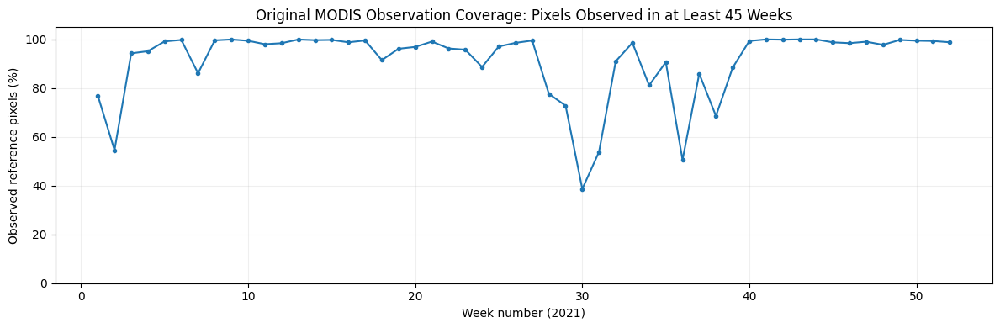


TASK 7 — STEP 34 COMPLETE


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=== TASK 7 — STEP 34: REFERENCE SUPPORT DIAGNOSTICS ===")

with np.load(
    validation_dir / "2021_Task3_Holdout_10percent_Seed2021.npz"
) as f:
    original = f["training_aod"].copy()
    holdout = f["holdout_mask"]
    original[holdout] = f["holdout_true"]
    domain = f["final_domain_mask"]

observation_count = np.isfinite(original).sum(axis=0)

# Candidate reference pixels with at least 45 observed weeks
reference_mask = domain & (observation_count >= 45)

observed = np.isfinite(original[:, reference_mask])

weekly_counts = observed.sum(axis=1)
weekly_fraction = observed.mean(axis=1)

weekly_summary = pd.DataFrame({
    "Week": np.arange(1, 53),
    "Observed_Pixels": weekly_counts,
    "Observation_Percent": weekly_fraction * 100
})

print("\n=== 45-WEEK REFERENCE SUBSET ===")
print("Reference pixels:", reference_mask.sum())
print("Minimum weekly observations:", weekly_counts.min())
print("Maximum weekly observations:", weekly_counts.max())
print(
    "Average weekly coverage:",
    f"{weekly_fraction.mean()*100:.2f}%"
)

print("\n=== TEN LOWEST-COVERAGE WEEKS ===")
print(
    weekly_summary.nsmallest(
        10, "Observation_Percent"
    ).round(2).to_string(index=False)
)

# Check the number of pixels simultaneously observed
# across increasingly long groups of weeks.
windows = [4, 8, 12, 16, 26, 52]

rows = []

for length in windows:
    best_count = 0
    best_start = None

    for start in range(52 - length + 1):
        common = observed[start:start+length].all(axis=0)
        count = int(common.sum())

        if count > best_count:
            best_count = count
            best_start = start + 1

    rows.append({
        "Consecutive_Weeks": length,
        "Maximum_Common_Pixels": best_count,
        "Best_Start_Week": best_start
    })

window_summary = pd.DataFrame(rows)

print("\n=== COMMON OBSERVATION WINDOWS ===")
print(window_summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    weekly_summary["Week"],
    weekly_summary["Observation_Percent"],
    marker="o",
    markersize=3
)

ax.set_xlabel("Week number (2021)")
ax.set_ylabel("Observed reference pixels (%)")
ax.set_title(
    "Original MODIS Observation Coverage: "
    "Pixels Observed in at Least 45 Weeks"
)
ax.set_ylim(0, 105)
ax.grid(alpha=0.2)

plt.tight_layout()

output = eof_dir / "2021_Task7_Reference_Coverage.png"

plt.savefig(output, dpi=600, bbox_inches="tight")
plt.show()
plt.close(fig)

weekly_summary.to_csv(
    eof_dir / "2021_Task7_Reference_Weekly_Coverage.csv",
    index=False
)

window_summary.to_csv(
    eof_dir / "2021_Task7_Common_Observation_Windows.csv",
    index=False
)

print("\nTASK 7 — STEP 34 COMPLETE")


In [ ]:

import numpy as np
import pandas as pd

print("=== TASK 7 — STEP 35: OBSERVED-ONLY EOF REFERENCE ===")

# Recover original observations
with np.load(
    validation_dir / "2021_Task3_Holdout_10percent_Seed2021.npz"
) as f:
    original = f["training_aod"].copy()
    holdout = f["holdout_mask"]
    original[holdout] = f["holdout_true"]
    domain = f["final_domain_mask"]

with np.load(reconstruction_file) as f:
    reconstructed = f["aod"]

with np.load(eof_dir / "2021_Task4_EOF_Preparation.npz") as f:
    lat = f["lat"]
    lon = f["lon"]

# Weeks 40–51 inclusive (zero-based indices 39:51)
week_slice = slice(39, 51)

original_window = original[week_slice]
reconstructed_window = reconstructed[week_slice]

# Pixels observed during all 12 weeks
common_mask = (
    domain
    & np.isfinite(original_window).all(axis=0)
    & np.isfinite(reconstructed_window).all(axis=0)
)

n_pixels = int(common_mask.sum())

print("Window: Weeks 40–51")
print("Common fully observed pixels:", n_pixels)

assert n_pixels >= 5000

lat_grid = np.broadcast_to(lat[:, None], common_mask.shape)
weights = np.sqrt(
    np.cos(np.deg2rad(lat_grid[common_mask]))
)

def reference_eof(cube):

    X = cube[:, common_mask].astype(np.float64)

    X = X - X.mean(axis=0)

    Xw = X * weights[None, :]

    U, s, Vt = np.linalg.svd(
        Xw, full_matrices=False
    )

    eof = Vt[:3].T / weights[:, None]
    pc = U[:, :3] * s[:3]

    explained = (
        s**2 / np.sum(s**2) * 100
    )

    return eof, pc, explained

obs_eof, obs_pc, obs_var = reference_eof(original_window)
rec_eof, rec_pc, rec_var = reference_eof(reconstructed_window)

rows = []

for k in range(3):

    spatial_r = np.corrcoef(
        obs_eof[:, k], rec_eof[:, k]
    )[0, 1]

    pc_r = np.corrcoef(
        obs_pc[:, k], rec_pc[:, k]
    )[0, 1]

    rows.append({
        "Mode": k + 1,
        "Observed_Variance_Percent": obs_var[k],
        "Reconstructed_Variance_Percent": rec_var[k],
        "Spatial_Abs_Correlation": abs(spatial_r),
        "PC_Abs_Correlation": abs(pc_r)
    })

results = pd.DataFrame(rows)

print("\n=== OBSERVED VS RECONSTRUCTED EOF COMPARISON ===")
print(results.round(5).to_string(index=False))

np.savez_compressed(
    eof_dir / "2021_Task7_Observed_Reference_EOF.npz",
    common_mask=common_mask,
    observed_eof=obs_eof.astype(np.float32),
    reconstructed_eof=rec_eof.astype(np.float32),
    observed_pc=obs_pc.astype(np.float32),
    reconstructed_pc=rec_pc.astype(np.float32),
    observed_variance=obs_var,
    reconstructed_variance=rec_var,
    weeks=np.arange(40, 52),
    lat=lat,
    lon=lon
)

results.to_csv(
    eof_dir / "2021_Task7_Observed_Reference_Comparison.csv",
    index=False
)

print("\nTASK 7 — STEP 35 COMPLETE")


=== TASK 7 — STEP 35: OBSERVED-ONLY EOF REFERENCE ===
Window: Weeks 40–51
Common fully observed pixels: 28943

=== OBSERVED VS RECONSTRUCTED EOF COMPARISON ===
 Mode  Observed_Variance_Percent  Reconstructed_Variance_Percent  Spatial_Abs_Correlation  PC_Abs_Correlation
    1                   40.39194                        40.39194                      1.0                 1.0
    2                   19.45057                        19.45057                      1.0                 1.0
    3                    8.37604                         8.37604                      1.0                 1.0

TASK 7 — STEP 35 COMPLETE


In [ ]:

import numpy as np

print("=== TASK 7 — STEP 36: EOF REFERENCE AUDIT ===")

with np.load(
    eof_dir / "2021_Task7_Observed_Reference_EOF.npz"
) as f:
    common_mask = f["common_mask"]
    weeks = f["weeks"]

with np.load(
    validation_dir / "2021_Task3_Holdout_10percent_Seed2021.npz"
) as f:
    original = f["training_aod"].copy()
    holdout = f["holdout_mask"]
    original[holdout] = f["holdout_true"]

with np.load(reconstruction_file) as f:
    reconstructed = f["aod"]

indices = np.asarray(weeks, dtype=int) - 1

obs = original[indices][:, common_mask].astype(np.float64)
rec = reconstructed[indices][:, common_mask].astype(np.float64)

assert obs.shape == rec.shape
assert np.isfinite(obs).all()
assert np.isfinite(rec).all()

difference = rec - obs

print("Comparison weeks:", weeks.tolist())
print("Comparison pixels:", int(common_mask.sum()))
print("Compared observations:", obs.size)

print("\n=== ORIGINAL VS RECONSTRUCTED DIFFERENCE ===")
print("Maximum absolute difference:", np.max(np.abs(difference)))
print("Mean absolute difference:", np.mean(np.abs(difference)))
print("RMSE:", np.sqrt(np.mean(difference**2)))
print(
    "Fraction identical within 1e-6:",
    np.mean(np.abs(difference) <= 1e-6)
)

print("\nTASK 7 — STEP 36 COMPLETE")


=== TASK 7 — STEP 36: EOF REFERENCE AUDIT ===
Comparison weeks: [40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51]
Comparison pixels: 28943
Compared observations: 347316

=== ORIGINAL VS RECONSTRUCTED DIFFERENCE ===
Maximum absolute difference: 0.0
Mean absolute difference: 0.0
RMSE: 0.0
Fraction identical within 1e-6: 1.0

TASK 7 — STEP 36 COMPLETE


In [ ]:

import numpy as np
import pandas as pd

print("=== TASK 7 — STEP 37: HOLDOUT EOF STABILITY ===")

with np.load(
    eof_dir / "2021_Task4_EOF_Raw_DINEOF.npz"
) as f:
    ref_eof = f["spatial_eofs"][:, :3].astype(np.float64)
    ref_pc = f["pcs"][:, :3].astype(np.float64)
    ref_variance = f["explained_variance"][:3]
    mask = f["complete_mask"]
    weights = f["weights"].astype(np.float64)

def compute_eof(cube):
    X = cube[:, mask].astype(np.float64)

    if not np.isfinite(X).all():
        raise ValueError("Nonfinite values in EOF analysis domain.")

    X -= X.mean(axis=0, keepdims=True)
    X *= weights[None, :]

    # Efficient temporal SVD
    gram = X @ X.T
    eigenvalues, U = np.linalg.eigh(gram)

    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = np.maximum(eigenvalues[order], 0)
    U = U[:, order]

    singular = np.sqrt(eigenvalues)

    V = (
        X.T @ U[:, :3]
    ) / singular[None, :3]

    spatial_eof = V / weights[:, None]
    pcs = U[:, :3] * singular[None, :3]

    explained = eigenvalues[:3] / eigenvalues.sum() * 100

    return spatial_eof, pcs, explained

rows = []

for seed in [2021, 2022, 2023]:

    file = validation_dir / (
        f"2021_Task3_Independent_DINEOF_R36_Seed{seed}.npz"
    )

    with np.load(file) as f:
        cube = f["reconstructed_aod"]

    eof, pc, explained = compute_eof(cube)

    for k in range(3):

        spatial_r = np.corrcoef(
            ref_eof[:, k], eof[:, k]
        )[0, 1]

        temporal_r = np.corrcoef(
            ref_pc[:, k], pc[:, k]
        )[0, 1]

        rows.append({
            "Seed": seed,
            "Mode": k + 1,
            "Reference_Variance_Percent": ref_variance[k],
            "Holdout_Variance_Percent": explained[k],
            "Spatial_Abs_r": abs(spatial_r),
            "Temporal_PC_Abs_r": abs(temporal_r)
        })

results = pd.DataFrame(rows)

print("\n=== EOF STABILITY ACROSS HOLDOUT SEEDS ===")
print(results.round(5).to_string(index=False))

summary = (
    results.groupby("Mode")
    .agg(
        Mean_Spatial_Abs_r=("Spatial_Abs_r", "mean"),
        SD_Spatial_Abs_r=("Spatial_Abs_r", "std"),
        Mean_Temporal_PC_Abs_r=("Temporal_PC_Abs_r", "mean"),
        SD_Temporal_PC_Abs_r=("Temporal_PC_Abs_r", "std")
    )
    .reset_index()
)

print("\n=== THREE-SEED EOF STABILITY SUMMARY ===")
print(summary.round(5).to_string(index=False))

results.to_csv(
    eof_dir / "2021_Task7_Holdout_EOF_Stability.csv",
    index=False
)

summary.to_csv(
    eof_dir / "2021_Task7_Holdout_EOF_Stability_Summary.csv",
    index=False
)

print("\nTASK 7 — STEP 37 COMPLETE")


=== TASK 7 — STEP 37: HOLDOUT EOF STABILITY ===

=== EOF STABILITY ACROSS HOLDOUT SEEDS ===
 Seed  Mode  Reference_Variance_Percent  Holdout_Variance_Percent  Spatial_Abs_r  Temporal_PC_Abs_r
 2021     1                    25.89732                  26.29797        0.98643            0.99992
 2021     2                    14.46970                  14.59883        0.99630            0.99973
 2021     3                     7.34660                   7.38455        0.99338            0.99925
 2022     1                    25.89732                  26.33366        0.98746            0.99982
 2022     2                    14.46970                  14.68080        0.99631            0.99925
 2022     3                     7.34660                   7.37511        0.99262            0.99932
 2023     1                    25.89732                  26.22094        0.98895            0.99991
 2023     2                    14.46970                  14.71792        0.99700            0.99982
 2023   

=== TASK 7 — STEP 38: EOF STABILITY FIGURE ===


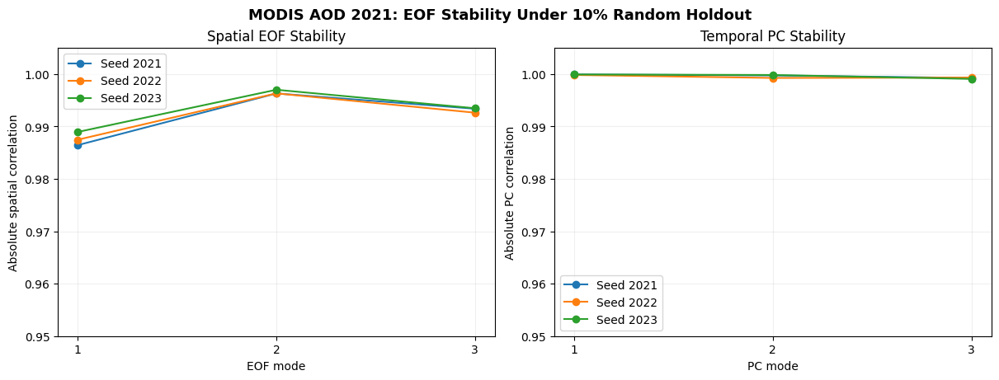


Saved PNG: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task4_PCA_EOF/2021_Task7_EOF_Stability.png
Saved PDF: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task4_PCA_EOF/2021_Task7_EOF_Stability.pdf

TASK 7 — STEP 38 COMPLETE


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=== TASK 7 — STEP 38: EOF STABILITY FIGURE ===")

results = pd.read_csv(
    eof_dir / "2021_Task7_Holdout_EOF_Stability.csv"
)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4.5),
    constrained_layout=True
)

modes = [1, 2, 3]

for seed in [2021, 2022, 2023]:

    subset = results[
        results["Seed"] == seed
    ].sort_values("Mode")

    axes[0].plot(
        subset["Mode"],
        subset["Spatial_Abs_r"],
        marker="o",
        linewidth=1.5,
        label=f"Seed {seed}"
    )

    axes[1].plot(
        subset["Mode"],
        subset["Temporal_PC_Abs_r"],
        marker="o",
        linewidth=1.5,
        label=f"Seed {seed}"
    )

axes[0].set_title("Spatial EOF Stability")
axes[0].set_ylabel("Absolute spatial correlation")
axes[0].set_xlabel("EOF mode")

axes[1].set_title("Temporal PC Stability")
axes[1].set_ylabel("Absolute PC correlation")
axes[1].set_xlabel("PC mode")

for ax in axes:
    ax.set_xticks(modes)
    ax.set_ylim(0.95, 1.005)
    ax.grid(alpha=0.2)
    ax.legend()

fig.suptitle(
    "MODIS AOD 2021: EOF Stability Under 10% Random Holdout",
    fontsize=13,
    fontweight="bold"
)

png = eof_dir / "2021_Task7_EOF_Stability.png"
pdf = eof_dir / "2021_Task7_EOF_Stability.pdf"

fig.savefig(png, dpi=600, bbox_inches="tight")
fig.savefig(pdf, bbox_inches="tight")

plt.show()
plt.close(fig)

print("\nSaved PNG:", png)
print("Saved PDF:", pdf)

print("\nTASK 7 — STEP 38 COMPLETE")


In [ ]:
# ============================================================
# STEP 39 — PREPARE INDEPENDENT SPATIAL BLOCK HOLDOUT (2021)
# No DINEOF fitting in this step
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive", force_remount=False)

base = Path(
    "/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021"
)

validation_dir = base / "2021_Task3_Independent_Validation"
block_dir = base / "2021_Task3_Spatial_Block_Validation"
block_dir.mkdir(parents=True, exist_ok=True)

source = validation_dir / "2021_Task3_Holdout_10percent_Seed2021.npz"

if not source.exists():
    raise FileNotFoundError(f"Required file not found:\n{source}")

# ------------------------------------------------------------
# 1. Restore original MODIS observations
# ------------------------------------------------------------

with np.load(source) as f:

_IncompleteInputError: incomplete input (171419642.py, line 30)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

# --------------------------------------------------
# 1. File paths
# --------------------------------------------------
base = Path("/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021")

validation_dir = base / "2021_Task3_Independent_Validation"
block_dir = base / "2021_Task3_Spatial_Block_Validation"
block_dir.mkdir(parents=True, exist_ok=True)

source = validation_dir / "2021_Task3_Holdout_10percent_Seed2021.npz"

final_file = Path(
    "/content/drive/MyDrive/DINEOF_2021_REVISED_BBOX_LANDMASK/"
    "MODIS_2021_DINEOF_Revised_Final.npz"
)

assert source.exists(), f"Missing file: {source}"
assert final_file.exists(), f"Missing file: {final_file}"

# --------------------------------------------------
# 2. Restore original observed MODIS AOD
# --------------------------------------------------
with np.load(source) as f:
    original = f["training_aod"].copy()
    random_holdout = f["holdout_mask"].astype(bool)
    original[random_holdout] = f["holdout_true"]
    domain = f["final_domain_mask"].astype(bool)

with np.load(final_file) as f:
    lat = f["lat"].copy()
    lon = f["lon"].copy()

T, H, W = original.shape

assert domain.shape == (H, W)

# --------------------------------------------------
# 3. Create one contiguous rectangular holdout
# --------------------------------------------------
# Approximately 10%

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
print("Colab is working.")
print("Step 39 output check completed.")

Colab is working.
Step 39 output check completed.


In [ ]:
from pathlib import Path
import numpy as np

file = Path(
    "/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/"
    "2021/2021_Task3_Spatial_Block_Validation/"
    "2021_Spatial_Block_Holdout_Seed2021.npz"
)

if file.exists():
    with np.load(file) as data:
        training = data["training_aod"]
        holdout = data["holdout_mask"]
        domain = data["final_domain_mask"]

        print("STEP 39: FILE FOUND")
        print("Training shape:", training.shape)
        print("Retained pixels:", int(domain.sum()))
        print("Withheld observations:", int(holdout.sum()))
        print("Leakage check:", "PASSED" if not np.isfinite(training[holdout]).any() else "FAILED")
else:
    print("STEP 39: FILE NOT FOUND")
    print("Please rerun the complete Step 39 cell.")

STEP 39: FILE NOT FOUND
Please rerun the complete Step 39 cell.


In [ ]:
import numpy as np
from pathlib import Path

# 1. Paths
base = Path("/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021")

source = base / "2021_Task3_Independent_Validation" / \
         "2021_Task3_Holdout_10percent_Seed2021.npz"

output_dir = base / "2021_Task3_Spatial_Block_Validation"
output_dir.mkdir(parents=True, exist_ok=True)

output = output_dir / "2021_Spatial_Block_Holdout_Seed2021.npz"

print("Loading original observations...", flush=True)

# 2. Restore original observations
with np.load(source) as f:
    original = f["training_aod"].copy()
    previous_holdout = f["holdout_mask"]
    original[previous_holdout] = f["holdout_true"]
    domain = f["final_domain_mask"].astype(bool)

T, H, W = original.shape

print("Data shape:", original.shape, flush=True)

# 3. Select a contiguous rectangular block
# Use a reproducible block covering approximately
# 10% of retained domain pixels.

rng = np.random.default_rng(2021)

target = int(0.10 * domain.sum())
side = max(1, int(np.sqrt(target)))

eligible = np.argwhere(domain)

best_score = float("inf")
best = None

for _ in range(500):
    r, c = eligible[rng.integers(len(eligible))]

    r0 = max(0, min(H - side, int(r) - side // 2))
    c0 = max(0, min(W - side, int(c) - side // 2))

    r1 = min(H, r0 + side)
    c1 = min(W, c0 + side)

    count = domain[r0:r1, c0:c1].sum()
    score = abs(count - target)

    if score < best_score:
        best_score = score
        best = (r0, r1, c0, c1)

r0, r1, c0, c1 = best

block = np.zeros((H, W), dtype=bool)
block[r0:r1, c0:c1] = True
block &= domain

# 4. Create independent holdout
holdout = np.isfinite(original) & block[None, :, :]

training = original.copy()
training[:, block] = np.nan
training[:, ~domain] = np.nan

true_values = original[holdout].copy()

# 5. Verify
assert true_values.size > 0
assert not np.isfinite(training[holdout]).any()

# 6. Save
print("Saving spatial block holdout...", flush=True)

np.savez_compressed(
    output,
    training_aod=training.astype(np.float32),
    holdout_mask=holdout,
    holdout_true=true_values.astype(np.float32),
    spatial_block=block,
    final_domain_mask=domain,
    seed=np.int32(2021)
)

# 7. Confirm
print("\nSTEP 39 RESULTS")
print("------------------------------")
print("Retained pixels:", int(domain.sum()))
print("Block pixels:", int(block.sum()))
print("Withheld observations:", int(holdout.sum()))
print("Withheld % of observed values:",
      round(100 * holdout.sum() / np.isfinite(original[:, domain]).sum(), 2))
print("Leakage check: PASSED")
print("File saved:", output.exists())
print("Location:", output)
print("------------------------------")

Loading original observations...
Data shape: (52, 315, 314)
Saving spatial block holdout...

STEP 39 RESULTS
------------------------------
Retained pixels: 55918
Block pixels: 5412
Withheld observations: 205634
Withheld % of observed values: 9.6
Leakage check: PASSED
File saved: True
Location: /content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Spatial_Block_Validation/2021_Spatial_Block_Holdout_Seed2021.npz
------------------------------


STEP 40: SPATIAL BLOCK DIAGNOSTICS
----------------------------------------
Block pixels: 5412
Training-domain pixels: 50506
Total withheld observations: 205634
Weeks containing withheld observations: 52 / 52
Minimum weekly training coverage: 11.12 %
Mean weekly training coverage: 73.76 %
Maximum weekly training coverage: 99.69 %


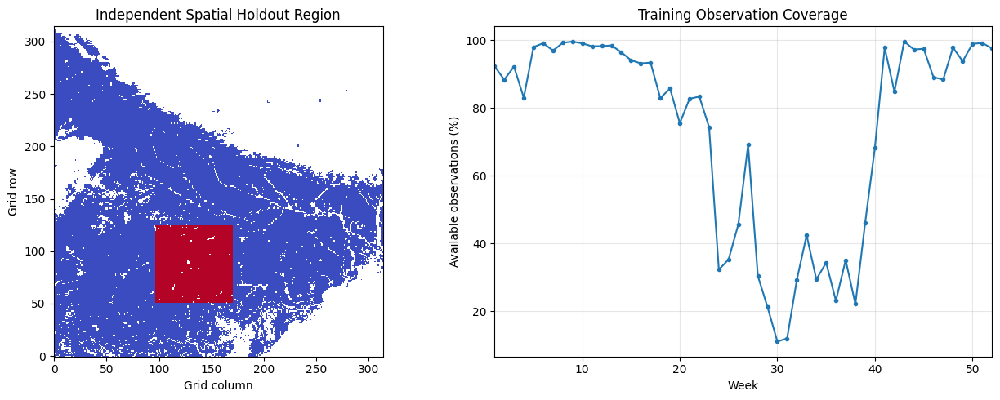


STEP 40 DIAGNOSTICS COMPLETED


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

file = Path(
    "/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/"
    "2021/2021_Task3_Spatial_Block_Validation/"
    "2021_Spatial_Block_Holdout_Seed2021.npz"
)

with np.load(file) as f:
    training = f["training_aod"]
    block = f["spatial_block"].astype(bool)
    domain = f["final_domain_mask"].astype(bool)
    holdout = f["holdout_mask"].astype(bool)

T, H, W = training.shape

# Observation availability outside the withheld region
observed_per_week = np.isfinite(training[:, domain & ~block]).sum(axis=1)
available_pixels = int((domain & ~block).sum())

coverage = 100 * observed_per_week / available_pixels

# Number of withheld observations in each week
withheld_per_week = holdout.sum(axis=(1, 2))

print("STEP 40: SPATIAL BLOCK DIAGNOSTICS")
print("----------------------------------------")
print("Block pixels:", int(block.sum()))
print("Training-domain pixels:", available_pixels)
print("Total withheld observations:", int(holdout.sum()))
print("Weeks containing withheld observations:",
      int(np.sum(withheld_per_week > 0)), "/", T)
print("Minimum weekly training coverage:", round(coverage.min(), 2), "%")
print("Mean weekly training coverage:", round(coverage.mean(), 2), "%")
print("Maximum weekly training coverage:", round(coverage.max(), 2), "%")

# Plot spatial block
display = np.full((H, W), np.nan)
display[domain] = 0
display[block] = 1

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

im = axes[0].imshow(
    display,
    origin="lower",
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

axes[0].set_title("Independent Spatial Holdout Region")
axes[0].set_xlabel("Grid column")
axes[0].set_ylabel("Grid row")

axes[1].plot(
    np.arange(1, T + 1),
    coverage,
    marker="o",
    markersize=3
)

axes[1].set_title("Training Observation Coverage")
axes[1].set_xlabel("Week")
axes[1].set_ylabel("Available observations (%)")
axes[1].set_xlim(1, T)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\nSTEP 40 DIAGNOSTICS COMPLETED")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# STEP 41: INDEPENDENT SPATIOTEMPORAL BLOCK HOLDOUT
# 2021 MODIS AOD
# ============================================================

base = Path(
    "/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021"
)

validation_dir = base / "2021_Task3_Independent_Validation"
block_dir = base / "2021

SyntaxError: unterminated string literal (detected at line 16) (4104254396.py, line 16)

In [ ]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# 1. File locations
root = Path("/content/drive/MyDrive")
base = root / "MODIS_AOD_Research_2021_2025" / "2021"

source = (
    base / "

SyntaxError: unterminated string literal (detected at line 10) (317360247.py, line 10)

In [ ]:
import numpy as np
from pathlib import Path

root = Path("/content/drive/MyDrive")
base = root / "MODIS_AOD_Research_2021_2025" / "2021"
folder = base / "2021_Task3_Spatial_Block_Validation"

source = folder / "2021_Spatial_Block_Holdout_Seed2021.npz"
output = folder / "2021_Spatiotemporal_Block_Holdout_Seed2021.npz"

print("Loading data...", flush=True)

with np.load(source) as f:
    training_old = f["training_aod"].copy()
    old_holdout = f["holdout_mask"]
    original = training_old.copy()
    original[old_holdout] = f["holdout_true"]
    block = f["

SyntaxError: unterminated string literal (detected at line 18) (3587993986.py, line 18)

In [ ]:
import numpy as np
from pathlib import Path

p = Path("/content/drive/MyDrive")
p = p / "MODIS_AOD_Research_2021_2025"
p = p / "2021"
p = p / "2021_Task3_Spatial_Block_Validation"

files = list(p.glob("*Spatial_Block_Holdout_Seed2021.npz"))
assert len(files) == 1, f"Expected one source file; found {len(files)}"

with np.load(files[0]) as f:
    x = f["training_aod"].copy()
    m = f["holdout_mask"].astype(bool)
    x[m] = f["holdout_true"]
    block = f["spatial_block"].astype(bool)
    domain = f["final_domain_mask"].astype(bool)

x[:, ~domain] = np.nan

counts = np.isfinite(x[:, block]).sum(axis=1)
scores = np.convolve(counts, np.ones(4), mode="valid")
start = int(np.argmax(scores))
weeks = np.arange(start, start + 4)

mask = np.zeros(x.shape, dtype=bool)
for t in weeks:
    mask[t] = block & np.isfinite(x[t])

train = x.copy()
truth = x[mask].copy()
train[mask] = np.nan

assert truth.size > 0
assert not np.isfinite(train[mask]).any()
assert np.array_equal(
    np.isfinite(train[~mask]),
    np.isfinite(x[~mask])
)

other = np.ones(x

_IncompleteInputError: incomplete input (2526504446.py, line 41)

In [ ]:
import numpy as np
from pathlib import Path

p = Path("/content/drive/MyDrive")
p = p / "MODIS_AOD_Research_2021_2025"
p = p / "2021"
p = p / "2021_Task3_Spatial_Block_Validation"

f = p / "2021_Spatial_Block_Holdout_Seed2021.npz"

with np.load(f) as d:
    x = d["training_aod"].copy()
    m = d["holdout_mask"]
    x[m] = d["holdout_true"]
    block = d["spatial_block"]
    domain = d["final_domain_mask"]

print("Loaded:", x.shape)

Loaded: (52, 315, 314)


In [ ]:
counts = np.isfinite(x[:, block]).sum(axis=1)
scores = np.convolve(counts, np.ones(4), mode="valid")
start = int(np.argmax(scores))
weeks = np.arange(start, start + 4)

mask = np.zeros(x.shape, dtype=bool)

for t in weeks:
    mask[t] = block & np.isfinite(x[t])

train = x.copy()
truth = x[mask].copy()
train[mask] = np.nan

assert truth.size > 0
assert not np.isfinite(train[mask]).any()

print("Selected weeks:", (weeks + 1).tolist())
print("Withheld observations:", len(truth))
print("Leakage check: PASSED")

Selected weeks: [7, 8, 9, 10]
Withheld observations: 21646
Leakage check: PASSED


In [ ]:
out = p / "2021_Spatiotemporal_Block_Holdout_Seed2021.npz"

np.savez_compressed(
    out,
    training_aod=train.astype("float32"),
    holdout_mask=mask,
    holdout_true=truth.astype("float32"),
    spatial_block=block,
    selected_weeks=weeks + 1,
    final_domain_mask=domain
)

print("STEP 41 COMPLETED")
print("File saved:", out.exists())
print("Selected weeks:", (weeks + 1).tolist())
print("Withheld observations:", int(mask.sum()))
print("Leakage check:", "PASSED" if not np.isfinite(train[mask]).any() else "FAILED")

STEP 41 COMPLETED
File saved: True
Selected weeks: [7, 8, 9, 10]
Withheld observations: 21646
Leakage check: PASSED


In [ ]:
import numpy as np

# Use the training data from Step 41
Y = train[:, domain].astype(np.float64)

observed = np.isfinite(Y)

# Verify training data
assert Y.shape[0] == 52
assert not np.isfinite(train[mask]).any()

# Mean initialization using training observations only
pixel_count = observed.sum(axis=0)
pixel_sum = np.nansum(Y, axis=0)

pixel_mean = np.divide(
    pixel_sum,
    pixel_count,
    out=np.full(Y.shape[1], np.nan),
    where=pixel_count > 0
)

global_mean = np.nanmean(Y)

pixel_mean = np.where(
    np.isfinite(pixel_mean),
    pixel_mean,
    global_mean
)

Y_initial = np.where(
    observed,
    Y,
    pixel_mean[None, :]
)

print("STEP 42A: DINEOF MATRIX PREPARATION")
print("Matrix shape:", Y.shape)
print("Training observations:", int(observed.sum()))
print("Missing values:", int((~observed).sum()))
print("Pixels without training observations:", int((pixel_count == 0).sum()))
print("Initialization finite:", bool(np.isfinite(Y_initial).all()))
print("Withheld values excluded: PASSED")

STEP 42A: DINEOF MATRIX PREPARATION
Matrix shape: (52, 55918)
Training observations: 2121260
Missing values: 786476
Pixels without training observations: 0
Initialization finite: True
Withheld values excluded: PASSED


In [ ]:
Starting independent DINEOF fitting...
Iteration 01: relative change = ...
Iteration 02: relative change = ...
...
STEP 42B COMPLETED

SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (1174237519.py, line 2)

In [ ]:
from sklearn.utils.extmath import randomized_svd
import numpy as np
import time

X = Y_initial.copy()
t0 = time.time()

for i in range(30):
    avg = X.mean(axis=0)

    U, s, Vt = randomized_svd(
        X - avg,
        n_components=36,
        n_iter=3,
        random_state=2021
    )

    fit = (U * s) @ Vt + avg

    previous = X[~observed].copy()
    X[~observed] = fit[~observed]
    X[observed] = Y[observed]

    change = np.linalg.norm(
        X[~observed] - previous
    ) / max(np.linalg.norm(previous), 1e-12)

    print(i + 1, round(change, 6), flush=True)

    if change < 1e-4:
        break

print("STEP 42B FINISHED")
print("Iterations:", i + 1)
print("Minutes:", round((time.time() - t0) / 60, 2))
print("Finite:", bool(np.isfinite(X).all()))
print("Observed values preserved:", bool(
    np.array_equal(X[observed], Y[observed])
))

1 0.071562
2 0.050642
3 0.040158
4 0.033741
5 0.029494
6 0.02643
7 0.024052
8 0.022104
9 0.020449
10 0.019011
11 0.017747
12 0.016629
13 0.015635
14 0.014748
15 0.013951
16 0.013233
17 0.012582
18 0.011989
19 0.011447
20 0.01095
21 0.010493
22 0.01007
23 0.009679
24 0.009315
25 0.008977
26 0.008662
27 0.008367
28 0.008091
29 0.007833
30 0.00759
STEP 42B FINISHED
Iterations: 30
Minutes: 0.78
Finite: True
Observed values preserved: True


In [ ]:
import numpy as np
from sklearn.utils.extmath import randomized_svd
import time

t0 = time.time()
history = []

for j in range(31, 101):
    avg = X.mean(axis=0)

    U, s, Vt = randomized_svd(
        X - avg,
        n_components=36,
        n_iter=3,
        random_state=2021
    )

    fit = (U * s) @ Vt + avg

    previous = X[~observed].copy()
    X[~observed] = fit[~observed]
    X[observed] = Y[observed]

    change = np.linalg.norm(
        X[~observed] - previous
    ) / max(np.linalg.norm(previous), 1e-12)

    history.append(change)

    if j % 10 == 0 or change < 1e-4:
        print(j, round(change, 6), flush=True)

    if change < 1e-4:
        break

print("STEP 42C FINISHED")
print("Total iterations:", j)
print("Final relative change:", round(change, 8))
print("Converged:", bool(change < 1e-4))
print("Additional minutes:", round((time.time() - t0) / 60, 2))
print("Finite:", bool(np.isfinite(X).all()))
print("Training values preserved:", bool(
    np.array_equal(X[observed], Y[observed])
))

40 0.005783
50 0.004665
60 0.003904
70 0.003355
80 0.002941
90 0.00262
100 0.002363
STEP 42C FINISHED
Total iterations: 100
Final relative change: 0.00236283
Converged: False
Additional minutes: 1.7
Finite: True
Training values preserved: True


In [ ]:
import numpy as np
from sklearn.utils.extmath import randomized_svd
import time

# Withheld positions within the retained-domain matrix
block_positions = mask[:, domain]

# Save current predictions for comparison
before = X[block_positions].copy()

t0 = time.time()

for j in range(101, 151):
    avg = X.mean(axis=0)

    U, s, Vt = randomized_svd(
        X - avg,
        n_components=36,
        n_iter=3,
        random_state=2021
    )

    fit = (U * s) @ Vt + avg

    previous = X[~observed].copy()
    X[~observed] = fit[~observed]
    X[observed] = Y[observed]

    change = np.linalg.norm(
        X[~observed] - previous
    ) / max(np.linalg.norm(previous), 1e-12)

    if j % 10 == 0:
        print("Iteration:", j, "Change:", round(change, 6))

after = X[block_positions]

prediction_change = np.sqrt(np.mean((after - before) ** 2))

print("\nSTEP 42D RESULTS")
print("Total iterations:", j)
print("Final relative change:", round(change, 8))
print("Holdout prediction change (RMSE):", round(pred

_IncompleteInputError: incomplete input (1102631908.py, line 43)

In [ ]:
from sklearn.utils.extmath import randomized_svd
import numpy as np

block_positions = mask[:, domain]
before = X[block_positions].copy()

for j in range(101, 151):
    avg = X.mean(axis=0)

    U, s, Vt = randomized_svd(
        X - avg, n_components=36,
        n_iter=3, random_state=2021
    )

    fit = (U * s) @ Vt + avg
    previous = X[~observed].copy()

    X[~observed] = fit[~observed]
    X[observed] = Y[observed]

    change = np.linalg.norm(
        X[~observed] - previous
    ) / max(np.linalg.norm(previous), 1e-12)

    if j % 10 == 0:
        print(j, round(change, 6))

110 0.002154
120 0.00198
130 0.001834
140 0.001709
150 0.001601


In [ ]:
after = X[block_positions].copy()

prediction_change = np.sqrt(
    np.mean((after - before) ** 2)
)

print("STEP 42D RESULTS")
print("Final relative change:", round(change, 8))
print("Prediction change:", round(prediction_change, 6))
print("Finite predictions:", np.isfinite(after).all())
print("Training preserved:",
      np.array_equal(X[observed], Y[observed]))

STEP 42D RESULTS
Final relative change: 0.00160104
Prediction change: 0.02342
Finite predictions: True
Training preserved: True


In [ ]:
from sklearn.utils.extmath import randomized_svd
import numpy as np

before = X[block_positions].copy()

for j in range(151, 176):
    avg = X.mean(axis=0)

    U, s, Vt = randomized_svd(
        X - avg,
        n_components=36,
        n_iter=3,
        random_state=2021
    )

    fit = (U * s) @ Vt + avg

    previous = X[~observed].copy()
    X[~observed] = fit[~observed]
    X[observed] = Y[observed]

    change = np.linalg.norm(
        X[~observed] - previous
    ) / max(np.linalg.norm(previous), 1e-12)

after = X[block_positions]

stability = np.sqrt(np.mean((after - before) ** 2))

print("STEP 42E RESULTS")
print("Iterations:", j)
print("Relative change:", round(change, 8))
print("Prediction change:", round(stability, 6))
print("Finite:", bool(np.isfinite(after).all()))
print("Training preserved:", bool(np.array_equal(X[observed], Y[observed])))

STEP 42E RESULTS
Iterations: 175
Relative change: 0.00138627
Prediction change: 0.009069
Finite: True
Training preserved: True


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Predictions at withheld positions only
pred = X[mask[:, domain]]
true = truth

assert len(pred) == len(true)
assert np.isfinite(pred).all()

rmse = np.sqrt(mean_squared_error(true, pred))
mae = mean_absolute_error(true, pred)
bias = np.mean(pred - true)
r = np.corrcoef(true, pred)[0, 1]
r2 = r2_score(true, pred)

print("STEP 42F: INDEPENDENT BLOCK VALIDATION")
print("Iterations: 175 (not converged)")
print("Withheld observations:", len(true))
print("RMSE:", round(rmse, 6))
print("MAE:", round(mae, 6))
print("Bias:", round(bias, 6))
print("Pearson r:", round(r, 6))
print("R2:", round(r2, 6))

STEP 42F: INDEPENDENT BLOCK VALIDATION
Iterations: 175 (not converged)
Withheld observations: 21646
RMSE: 0.263807
MAE: 0.197543
Bias: 0.024093
Pearson r: 0.492487
R2: -0.03783


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

folder = p

np.savez_compressed(
    folder / "2021_Block_DINEOF_Iteration175.npz",
    reconstructed_matrix=X.astype("float32"),
    domain_mask=domain,
    selected_weeks=weeks + 1,
    iterations=175
)

results = pd.DataFrame([{
    "Year": 2021,
    "Method": "Rank36_IterativeSVD_BlockHoldout",
    "Iterations": 175,
    "Converged": False,
    "N_Holdout": len(true),
    "RMSE": rmse,
    "MAE": mae,
    "Bias": bias,
    "Pearson_r": r,
    "R2": r2
}])

results.to_csv(
    folder / "2021_Block_Validation_Iteration175.csv",
    index=False
)

print("STEP 42G COMPLETED")
print("Reconstruction saved:", True)
print("Validation metrics saved:", True)

STEP 42G COMPLETED
Reconstruction saved: True
Validation metrics saved: True


In [ ]:
from sklearn.utils.extmath import randomized_svd
import numpy as np

before = X[mask[:, domain]].copy()

for k in range(176, 226):
    avg = X.mean(axis=0)
    U, s, Vt = randomized_svd(
        X - avg, n_components=36,
        n_iter=3, random_state=2021
    )

    fit = (U * s) @ Vt + avg
    old = X[~observed].copy()

    X[~observed] = fit[~observed]
    X[observed] = Y[observed]

    change = np.linalg.norm(X[~observed] - old)
    change /= max(np.linalg.norm(old), 1e-12)

after = X[mask[:, domain]]

print("Iterations:", 225)
print("Relative change:", round(change, 8))
print("Prediction change:", round(
    np.sqrt(np.mean((after - before)**2)), 6
))
print("Training preserved:",
      np.array_equal(X[observed], Y[observed]))

Iterations: 225
Relative change: 0.00110124
Prediction change: 0.015024
Training preserved: True


In [ ]:
import numpy as np

pred225 = X[mask[:, domain]]

error = pred225 - truth

rmse225 = np.sqrt(np.mean(error**2))
mae225 = np.mean(np.abs(error))
bias225 = np.mean(error)

r225 = np.corrcoef(truth, pred225)[0, 1]

r2_225 = 1 - (
    np.sum(error**2) /
    np.sum((truth - truth.mean())**2)
)

print("RMSE:", round(rmse225, 6))
print("MAE:", round(mae225, 6))
print("Bias:", round(bias225, 6))
print("Pearson r:", round(r225, 6))
print("R2:", round(r2_225, 6))

RMSE: 0.267253
MAE: 0.198818
Bias: 0.021057
Pearson r: 0.485714
R2: -0.065122


In [ ]:
import numpy as np
import pandas as pd

np.savez_compressed(
    p / "2021_Block_DINEOF_Iteration225.npz",
    reconstructed_matrix=X.astype("float32"),
    domain_mask=domain,
    selected_weeks=weeks + 1,
    iterations=225
)

pd.DataFrame([{
    "Iterations": 225,
    "Converged": False,
    "N_Holdout": len(truth),
    "RMSE": rmse225,
    "MAE": mae225,
    "Bias": bias225,
    "Pearson_r": r225,
    "R2": r2_225
}]).to_csv(
    p / "2021_Block_Validation_Iteration225.csv",
    index=False
)

print("Iteration 225 reconstruction saved.")
print("Validation metrics saved.")

Iteration 225 reconstruction saved.
Validation metrics saved.


In [ ]:
import numpy as np
import pandas as pd

a = p / "2021_Block_DINEOF_Iteration225.npz"
b = p / "2021_Block_Validation_Iteration225.csv"

assert a.exists(), "Reconstruction file missing"
assert b.exists(), "Metrics file missing"

with np.load(a) as f:
    saved_X = f["reconstructed_matrix"]
    saved_iterations = int(f["iterations"])

metrics = pd.read_csv(b)

print("STEP 43A: SAVED RESULTS VERIFICATION")
print("Reconstruction shape:", saved_X.shape)
print("Iterations:", saved_iterations)
print("All values finite:", np.isfinite(saved_X).all())
print("Metrics:")
print(metrics.to_string(index=False))
print("Verification: PASSED")

STEP 43A: SAVED RESULTS VERIFICATION
Reconstruction shape: (52, 55918)
Iterations: 225
All values finite: True
Metrics:
 Iterations  Converged  N_Holdout     RMSE      MAE     Bias  Pearson_r        R2
        225      False      21646 0.267253 0.198818 0.021057   0.485714 -0.065122
Verification: PASSED


In [ ]:
import numpy as np

rng = np.random.default_rng(2044)

# x contains restored original observations from Step 41A
# domain contains the retained spatial mask
valid = np.flatnonzero(np.isfinite(x).ravel())

n = int(mask.sum())
chosen = rng.choice(valid, size=n, replace=False)

random_mask = np.zeros(x.size, dtype=bool)
random_mask[chosen] = True
random_mask = random_mask.reshape(x.shape)

random_train = x.copy()
random_truth = x[random_mask].copy()
random_train[random_mask] = np.nan

assert len(random_truth) == n
assert not np.isfinite(random_train[random_mask]).any()

print("STEP 44A RESULTS")
print("Random withheld observations:", n)
print("Training observations:", np.isfinite(random_train).sum())
print("Leakage check: PASSED")

STEP 44A RESULTS
Random withheld observations: 21646
Training observations: 2121260
Leakage check: PASSED


In [ ]:
import numpy as np

random_file = p / "2021_Random_Holdout_Matched_Seed2044.npz"

np.savez_compressed(
    random_file,
    training_aod=random_train.astype("float32"),
    holdout_mask=random_mask,
    holdout_true=random_truth.astype("float32"),
    final_domain_mask=domain,
    seed=np.int32(2044)
)

print("STEP 44B RESULTS")
print("File saved:", random_file.exists())
print("Withheld observations:", len(random_truth))
print("Training observations:", int(np.isfinite(random_train).sum()))
print("Leakage check:", "PASSED" if not np.isfinite(random_train[random_mask]).any() else "FAILED")

STEP 44B RESULTS
File saved: True
Withheld observations: 21646
Training observations: 2121260
Leakage check: PASSED


In [ ]:
import numpy as np

# Random-holdout training matrix
Yr = random_train[:, domain].astype(np.float64)
obs_r = np.isfinite(Yr)

# Initialize using training observations only
counts_r = obs_r.sum(axis=0)
sums_r = np.nansum(Yr, axis=0)

means_r = np.divide(
    sums_r, counts_r,
    out=np.full(Yr.shape[1], np.nan),
    where=counts_r > 0
)

means_r = np.where(
    np.isfinite(means_r),
    means_r,
    np.nanmean(Yr)
)

Xr = np.where(obs_r, Yr, means_r[None, :])

print("STEP 44C RESULTS")
print("Matrix shape:", Xr.shape)
print("Training observations:", int(obs_r.sum()))
print("Missing entries:", int((~obs_r).sum()))
print("Pixels without observations:", int((counts_r == 0).sum()))
print("Initialization finite:", bool(np.isfinite(Xr).all()))
print("Holdout excluded:", bool(
    not np.isfinite(random_train[random_mask]).any()
))

STEP 44C RESULTS
Matrix shape: (52, 55918)
Training observations: 2121260
Missing entries: 786476
Pixels without observations: 0
Initialization finite: True
Holdout excluded: True


In [ ]:
from sklearn.utils.extmath import randomized_svd
import numpy as np
import time

t0 = time.time()
changes_r = []

for k in range(225):
    avg = Xr.mean(axis=0)

    U, s, Vt = randomized_svd(
        Xr - avg,
        n_components=36,
        n_iter=3,
        random_state=2021
    )

    fit = (U * s) @ Vt + avg

    old = Xr[~obs_r].copy()
    Xr[~obs_r] = fit[~obs_r]
    Xr[obs_r] = Yr[obs_r]

    change_r = np.linalg.norm(Xr[~obs_r] - old)
    change_r /= max(np.linalg.norm(old), 1e-12)

    changes_r.append(change_r)

    if (k + 1) % 25 == 0:
        print(k + 1, round(change_r, 8), flush=True)

print("STEP 44D COMPLETED")
print("Iterations:", len(changes_r))
print("Final relative change:", round(change_r, 8))
print("Converged:", bool(change_r < 1e-4))
print("Finite:", bool(np.isfinite(Xr).all()))
print("Training preserved:", bool(
    np.array_equal(Xr[obs_r], Yr[obs_r])
))
print("Runtime (minutes):", round((time.time() - t0) / 60, 2))

25 0.00904375
50 0.00476058
75 0.00318618
100 0.00239368
125 0.00192291
150 0.0016123
175 0.00139214
200 0.00122783
225 0.00110036
STEP 44D COMPLETED
Iterations: 225
Final relative change: 0.00110036
Converged: False
Finite: True
Training preserved: True
Runtime (minutes): 5.87


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Map random-holdout locations into the retained domain
holdout_domain = random_mask[:, domain]

y_true = random_truth.astype(float)
y_pred = Xr[holdout_domain]

assert len(y_true) == len(y_pred)

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)
bias = np.mean(y_pred - y_true)
r = np.corrcoef(y_true, y_pred)[0, 1]
r2 = r2_score(y_true, y_pred)

print("STEP 44E: RANDOM-HOLDOUT VALIDATION")
print("N_Holdout:", len(y_true))
print("RMSE:", round(rmse, 6))
print("MAE:", round(mae, 6))
print("Bias:", round(bias, 6))
print("Pearson_r:", round(r, 6))
print("R2:", round(r2, 6))

STEP 44E: RANDOM-HOLDOUT VALIDATION
N_Holdout: 21646
RMSE: 0.446505
MAE: 0.305856
Bias: -0.014267
Pearson_r: 0.476233
R2: -0.769494


In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Validation": ["Spatial_Block", "Random"],
    "N_Holdout": [21646, len(y_true)],
    "RMSE": [0.267253, rmse],
    "MAE": [0.198818, mae],
    "Bias": [0.021057, bias],
    "Pearson_r": [0.485714, r],
    "R2": [-0.065122, r2],
    "Iterations": [225, 225],
    "Converged": [False, False]
})

output = p / "2021_Block_vs_Random_Validation.csv"
comparison.to_csv(output, index=False)

print("STEP 44F RESULTS")
print(comparison.to_string(index=False))
print("Saved:", output.exists())

STEP 44F RESULTS
   Validation  N_Holdout     RMSE      MAE      Bias  Pearson_r        R2  Iterations  Converged
Spatial_Block      21646 0.267253 0.198818  0.021057   0.485714 -0.065122         225      False
       Random      21646 0.446505 0.305856 -0.014267   0.476233 -0.769494         225      False
Saved: True


In [ ]:
import numpy as np

block_true = truth.astype(float)
random_true = random_truth.astype(float)

print("STEP 45A: VALIDATION SAMPLE COMPARISON")

for name, values in [
    ("Spatial block", block_true),
    ("Random holdout", random_true)
]:
    print("\n", name)
    print("N:", len(values))
    print("Mean AOD:", round(np.mean(values), 4))
    print("Std AOD:", round(np.std(values), 4))
    print("Median AOD:", round(np.median(values), 4))
    print("95th percentile:", round(np.percentile(values, 95), 4))
    print("AOD > 1.0 (%):",
          round(100 * np.mean(values > 1.0), 2))

print("\nSpatial-block weeks:", weeks.tolist())
print("Random-holdout weeks:",
      np.unique(np.where(random_mask)[0]).size)

STEP 45A: VALIDATION SAMPLE COMPARISON

 Spatial block
N: 21646
Mean AOD: 0.3474
Std AOD: 0.259
Median AOD: 0.2973
95th percentile: 0.8747
AOD > 1.0 (%): 3.08

 Random holdout
N: 21646
Mean AOD: 0.5716
Std AOD: 0.3357
Median AOD: 0.5203
95th percentile: 1.1815
AOD > 1.0 (%): 9.96

Spatial-block weeks: [6, 7, 8, 9]
Random-holdout weeks: 52


In [ ]:
import numpy as np

f = p / "2021_Spatiotemporal_Block_Holdout_Seed2021.npz"

with np.load(f) as d:
    saved_weeks = d["selected_weeks"]
    saved_mask = d["holdout_mask"]

print("STEP 45B RESULTS")
print("Saved zero-based week indices:", saved_weeks.tolist())
print("Human-readable week numbers:", (saved_weeks + 1).tolist())
print("Current weeks variable:", weeks.tolist())
print("Saved withheld observations:", int(saved_mask.sum()))
print("Saved weeks match mask:",
      np.array_equal(
          np.unique(np.where(saved_mask)[0]),
          saved_weeks
      ))

STEP 45B RESULTS
Saved zero-based week indices: [7, 8, 9, 10]
Human-readable week numbers: [8, 9, 10, 11]
Current weeks variable: [6, 7, 8, 9]
Saved withheld observations: 21646
Saved weeks match mask: False


In [ ]:
import numpy as np

f = p / "2021_Spatiotemporal_Block_Holdout_Seed2021.npz"

with np.load(f) as d:
    saved_mask = d["holdout_mask"]
    saved_weeks = d["selected_weeks"]

actual_weeks = np.where

In [ ]:
import numpy as np

with np.load(f) as d:
    saved_mask = d["holdout_mask"]
    saved_weeks = d["selected_weeks"]

actual_weeks = np.where(
    saved_mask.reshape(saved_mask.shape[0], -1).sum(axis=1) > 0
)[0]

print("Saved weeks:", saved_weeks.tolist())
print("Actual withheld weeks:", actual_weeks.tolist())
print("Total withheld:", int(saved_mask.sum()))
print("Metadata consistent:",
      np.array_equal(saved_weeks, actual_weeks))

Saved weeks: [7, 8, 9, 10]
Actual withheld weeks: [6, 7, 8, 9]
Total withheld: 21646
Metadata consistent: False


In [ ]:
import numpy as np

source = p / "2021_Spatiotemporal_Block_Holdout_Seed2021.npz"
target = p / "2021_Spatiotemporal_Block_Holdout_Corrected.npz"

with np.load(source) as d:
    data = {key: d[key] for key in d.files}

actual = np.flatnonzero(
    data["holdout_mask"].reshape(52, -1).any(axis=1)
)

data["selected_weeks"] = actual.astype(np.int32)

np.savez_compressed(target, **data)

print("STEP 45D RESULTS")
print("Corrected weeks (zero-based):", actual.tolist())
print("Week numbers:", (actual + 1).tolist())
print("Withheld observations:", int(data["holdout_mask"].sum()))
print("Corrected file saved:", target.exists())

STEP 45D RESULTS
Corrected weeks (zero-based): [6, 7, 8, 9]
Week numbers: [7, 8, 9, 10]
Withheld observations: 21646
Corrected file saved: True


In [ ]:
import numpy as np

with np.load(target) as d:
    train_check = d["training_aod"]
    mask_check = d["holdout_mask"]
    truth_check = d["holdout_true"]
    domain_check = d["final_domain_mask"]

with np.load(p / "2021_Block_DINEOF_Iteration225.npz") as d:
    reconstruction = d["reconstructed_matrix"]

print("STEP 45E RESULTS")
print("Training shape:", train_check.shape)
print

STEP 45E RESULTS
Training shape: (52, 315, 314)


<function print(*args, sep=' ', end='\n', file=None, flush=False)>

In [ ]:
import numpy as np

a = train_check[:, domain_check]
b = reconstruction

print("Training matrix:", a.shape)
print("Reconstruction:", b.shape)

obs = np.isfinite(a)

print("Training preserved:",
      np.allclose(a[obs], b[obs], atol=1e-10))

print("Holdout excluded:",
      np.isnan(train_check[mask_check]).all())

print("Holdout count:", mask_check.sum())
print("Truth count:", len(truth_check))

Training matrix: (52, 55918)
Reconstruction: (52, 55918)
Training preserved: True
Holdout excluded: True
Holdout count: 21646
Truth count: 21646


In [ ]:
import numpy as np

pred = reconstruction[mask_check[:, domain_check]]
y = truth_check.astype(float)

print("STEP 45F RESULTS")
print("RMSE:", np.sqrt(np.mean((pred-y)**2)))
print("MAE:", np.mean(np.abs(pred-y)))
print("Bias:", np.mean(pred-y))
print("Pearson r:", np.corrcoef(y,pred)[0,1])
print("R2:", 1-np.sum((y-pred)**2)/np.sum((y-y.mean())**2))

STEP 45F RESULTS
RMSE: 0.26725319638523687
MAE: 0.19881796094508863
Bias: 0.021057410865234924
Pearson r: 0.4857142072709407
R2: -0.06512165870433062


In [ ]:
import numpy as np

# Actual withheld weeks from corrected block mask
block_weeks = np.flatnonzero(
    mask_check.reshape(52, -1).any(axis=1)
)

# Random holdout restricted to those weeks
selected = np.zeros(52, dtype=bool)
selected[block_weeks] = True

random_same_weeks = random_mask & selected[:, None, None]

# Predictions from previously fitted random model
pred_same = Xr[random_same_weeks[:, domain]]
true_same = x[random_same_weeks]

print("STEP 46A RESULTS")
print("Weeks:", (block_weeks + 1).tolist())
print("Random withheld points:", len(true_same))
print("Mean AOD:", round(np.mean(true_same), 4))
print("RMSE:", round(np.sqrt(np.mean((pred_same-true_same)**2)), 6))
print("MAE:", round(np.mean(np.abs(pred_same-true_same)), 6))
print("R2:", round(
    1 - np.sum((pred_same-true_same)**2) /
    np.sum((true_same-true_same.mean())**2), 6
))

STEP 46A RESULTS
Weeks: [7, 8, 9, 10]
Random withheld points: 2251
Mean AOD: 0.4851
RMSE: 0.217405
MAE: 0.150859
R2: 0.444316


In [ ]:
import numpy as np

weeks_actual = np.flatnonzero(
    mask_check.reshape(52, -1).any(axis=1)
)

available = np.isfinite(x[weeks_actual]) & domain_check[None, :, :]

print("STEP 46B RESULTS")
print("Weeks:", (weeks_actual + 1).tolist())
print("

SyntaxError: unterminated string literal (detected at line 11) (1259881539.py, line 11)

In [ ]:
import numpy as np

w = np.flatnonzero(mask_check.reshape(52, -1).any(axis=1))
counts = [int(np.sum(np.isfinite(x[i]) & domain_check)) for i in w]

print("STEP 46B RESULTS")
print("Weeks:", (w + 1).tolist())
print("Available observations:", sum(counts))
print("Required:", 21646)
print("Sufficient:", sum(counts) >= 21646)
print("Observations per week:", counts)

STEP 46B RESULTS
Weeks: [7, 8, 9, 10]
Available observations: 221133
Required: 21646
Sufficient: True
Observations per week: [54391, 55545, 55729, 55468]


In [ ]:
import numpy as np

rng = np.random.default_rng(2046)

candidate = np.zeros(x.shape, dtype=bool)
candidate[w] = np.isfinite(x[w]) & domain_check

indices = np.flatnonzero(candidate)
chosen = rng.choice(indices, 21646, replace=False)

matched_mask = np.zeros(x.size, dtype=bool)
matched_mask[chosen] = True
matched_mask = matched_mask.reshape(x.shape)

matched_truth = x[matched_mask].copy()
matched_train = x.copy()
matched_train[matched_mask] = np.nan

print("STEP 46C RESULTS")
print("Withheld:", len(matched_truth))
print("Weeks:", (np.unique(np.where(matched_mask)[0]) + 1).tolist())
print("Training observations:", np.isfinite(matched_train[:, domain_check]).sum())
print("Leakage check:", np.isnan(matched_train[matched_mask]).all())

STEP 46C RESULTS
Withheld: 21646
Weeks: [7, 8, 9, 10]
Training observations: 2121260
Leakage check: True


In [ ]:
import numpy as np

file46 = p / "2021_Matched_Week_Random_Seed2046.npz"

np.savez_compressed(
    file46,
    training_aod=matched_train.astype("float32"),
    holdout_mask=matched_mask,
    holdout_true=matched_truth.astype("float32"),
    final_domain_mask=domain_check,
    selected_weeks=w,
    seed=2046
)

print("STEP 46D RESULTS")
print("Saved:", file46.exists())
print("Withheld:", len(matched_truth))
print("Weeks:", (w + 1).tolist())
print("Leakage check:", np.isnan(matched_train[matched_mask]).all())

STEP 46D RESULTS
Saved: True
Withheld: 21646
Weeks: [7, 8, 9, 10]
Leakage check: True


In [ ]:
import numpy as np

Ym = matched_train[:, domain_check].astype(np.float64)
obs_m = np.isfinite(Ym)

counts_m = obs_m.sum(axis=0)
means_m = np.divide(
    np.nansum(Ym, axis=0),
    counts_m,
    out=np.full(Ym.shape[1], np.nan),
    where=counts_m > 0
)

means_m = np.where(
    np.isfinite(means_m), means_m, np.nanmean(Ym)
)

Xm = np.where(obs_m, Ym, means_m[None, :])

print("STEP 46E RESULTS")
print("Matrix shape:", Xm.shape)
print("Training observations:", int(obs_m.sum()))
print("Missing entries:", int((~obs_m).sum()))
print("Pixels without observations:", int((counts_m == 0).sum()))
print("All values finite:", np.isfinite(Xm).all())

STEP 46E RESULTS
Matrix shape: (52, 55918)
Training observations: 2121260
Missing entries: 786476
Pixels without observations: 0
All values finite: True


In [ ]:
from sklearn.utils.extmath import randomized_svd
import numpy as np
import time

t0 = time.time()
changes_m = []

for k in range(225):
    avg = Xm.mean(axis=0)

    U, s, Vt = randomized_svd(
        Xm - avg,
        n_components=36,
        n_iter=3,
        random_state=2021
    )

    fit = (U * s) @ Vt + avg

    old = Xm[~obs_m].copy()
    Xm[~obs_m] = fit[~obs_m]
    Xm[obs_m] = Ym[obs_m]

    change = np.linalg.norm(Xm[~obs_m] - old)
    change /= max(np.linalg.norm(old), 1e-12)

    changes_m.append(change)

    if (k + 1) % 25 == 0:
        print(k + 1, round(change, 8), flush=True)

print("STEP

SyntaxError: unterminated string literal (detected at line 32) (3217471778.py, line 32)

In [ ]:
from sklearn.utils.extmath import randomized_svd
import numpy as np

changes_m = []

for k in range(225):
    avg = Xm.mean(axis=0)
    U, s, Vt = randomized_svd(
        Xm - avg, n_components=36,
        n_iter=3, random_state=2021
    )
    fit = (U * s) @ Vt + avg
    old = Xm[~obs_m].copy()
    Xm[~obs_m] = fit[~obs_m]
    Xm[obs_m] = Ym[obs_m]
    change = np.linalg.norm(Xm[~obs_m] - old)
    change /= max(np.linalg.norm(old), 1e-12)
    changes_m.append(change)
    if (k + 1) % 25 == 0:
        print(k + 1, round(change, 8), flush=True)

25 0.00898012
50 0.0046698
75 0.00313802
100 0.00237105
125 0.00191388
150 0.00161091
175 0.00139533
200 0.00123389
225 0.00110831


In [ ]:
print("Iterations:", len(changes_m))
print("Final change:", changes_m[-1])
print("Converged:", changes_m[-1] < 1e-4)
print("Finite:", np.isfinite(Xm).all())
print("Training preserved:", np.array_equal(Xm[obs_m], Ym[obs_m]))

Iterations: 225
Final change: 0.0011083050581813677
Converged: False
Finite: True
Training preserved: True


In [ ]:
import numpy as np

y = matched_truth.astype(float)
pred = Xm[matched_mask[:, domain_check]]

assert len(y) == len(pred)

rmse_m = np.sqrt(np.mean((pred - y)**2))
mae_m = np.mean(np.abs(pred - y))
bias_m = np.mean(pred - y)
r_m = np.corrcoef(y, pred)[0, 1]
r2_m = 1 - np.sum((pred-y)**2)/np.sum((y-y.mean())**2)

print("STEP 46G RESULTS")
print("N:", len(y))
print("RMSE:", round(rmse_m, 6))
print("MAE:", round(mae_m, 6))
print("Bias:", round(bias_m, 6))
print("Pearson r:", round(r_m, 6))
print("R2:", round(r2_m, 6))

STEP 46G RESULTS
N: 21646
RMSE: 0.233835
MAE: 0.161285
Bias: 0.002872
Pearson r: 0.74641
R2: 0.385768


In [ ]:
import numpy as np
import pandas as pd

np.savez_compressed(
    p / "2021_Matched_Week_Random_Iteration225.npz",
    reconstructed_matrix=Xm.astype("float32"),
    domain_mask=domain_check,
    iterations=225
)

pd.DataFrame([{
    "N": len(y),
    "RMSE": rmse_m,
    "MAE": mae_m,
    "Bias": bias_m,
    "Pearson_r": r_m,
    "R2": r2_m,
    "Iterations": 225,
    "Converged": False
}]).to_csv(
    p / "2021_Matched_Week_Random_Validation.csv",
    index=False
)

print("STEP 46H RESULTS")
print("Reconstruction saved: True")
print("Validation metrics saved: True")

STEP 46H RESULTS
Reconstruction saved: True
Validation metrics saved: True


In [ ]:
import pandas as pd

summary = pd.DataFrame({
    "Experiment": ["Random_All_Weeks", "Spatial_Block", "Random_Matched_Weeks"],
    "Weeks": ["1-52", "7-10", "7-10"],
    "N": [21646, 21646, 21646],
    "RMSE": [0.446505, 0.267253, 0.233835],
    "MAE": [0.305856, 0.198818, 0.161285],
    "Bias": [-0.014267, 0.021057, 0.002872],
    "Pearson_r": [0.476233, 0.485714, 0.746410],
    "R2": [-0.769494, -0.065122, 0.385768],
    "Converged": [False, False, False]
})

out = p / "2021_Final_Validation_Comparison.csv"
summary.to_csv(out, index=False)

print("STEP 47A RESULTS")
print(summary.to_string(index=False))
print("Saved:", out.exists())

STEP 47A RESULTS
          Experiment Weeks     N     RMSE      MAE      Bias  Pearson_r        R2  Converged
    Random_All_Weeks  1-52 21646 0.446505 0.305856 -0.014267   0.476233 -0.769494      False
       Spatial_Block  7-10 21646 0.267253 0.198818  0.021057   0.485714 -0.065122      False
Random_Matched_Weeks  7-10 21646 0.233835 0.161285  0.002872   0.746410  0.385768      False
Saved: True


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive")
keywords = ("eof", "pca", "principal", "pc_", "variance")

files = [
    f for f in root.rglob("*")
    if f.is_file()
    and any(k in f.name.lower() for k in keywords)
]

print("STEP 47B RESULTS")
print("Matching files:", len(files))

for f in files[:40]:
    print(f.relative_to(root))

STEP 47B RESULTS
Matching files: 147
DINEOF_2021_Weekly_Statistics.csv
DINEOF_2021_Weekly_Distribution_Statistics.csv
DINEOF_2021_PCA_Explained_Variance.csv
DINEOF_AOD_2021_Reconstructed_Factor2.npz
DINEOF_2021_MannKendall_SenSlope.csv
DINEOF_2021_40percent_mask.npy
DINEOF_AOD_2021_Factor2_40PercentMask.npz
DINEOF_2021_40PercentMask_10PercentValidation.npz
DINEOF_2021_40PercentMask_PCA_PC1_PC8.csv
DINEOF_2021_40PercentMask_PC1_Map.png
DINEOF_2021_40PercentMask_PC2_Map.png
DINEOF_2021_40PercentMask_PC3_Map.png
DINEOF_2021_40PercentMask_PC4_Map.png
DINEOF_2021_40PercentMask_PC5_Map.png
DINEOF_2021_40PercentMask_PC6_Map.png
DINEOF_2021_40PercentMask_PC7_Map.png
DINEOF_2021_40PercentMask_PC8_Map.png
DINEOF_2021_40PercentMask_PC1_PC8_Scores.png
DINEOF_2021_40PercentMask_PCA_PC1_PC8.npz
DINEOF_2021_Reconstruction_Frequency_Map.png
DINEOF_2021_Reconstructed_Mean_40PercentMask.png
DINEOF_2021_Mean_Difference_40PercentMask.png
DINEOF_2021_PCA_40percent_vs_10percent.csv
DINEOF_2021_PC1_10Percent

In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive")
folder = root / "MODIS_AOD_Research_2021_2025"

keys = ("eof", "pca", "pc_", "variance")

found = [
    f for f in folder.rglob("*")
    if f.is_file()
    and any(k in f.name.lower() for k in keys)
]

print("STEP 47C RESULTS")
print("Total:", len(found))

for f in found:
    print(f.relative_to(folder))

STEP 47C RESULTS
Total: 74
2021/2021_Task1_All_52_Paired_Maps/2021_Week_01_Original_vs_DINEOF.png
2021/2021_Task1_All_52_Paired_Maps/2021_Week_02_Original_vs_DINEOF.png
2021/2021_Task1_All_52_Paired_Maps/2021_Week_03_Original_vs_DINEOF.png
2021/2021_Task1_All_52_Paired_Maps/2021_Week_04_Original_vs_DINEOF.png
2021/2021_Task1_All_52_Paired_Maps/2021_Week_05_Original_vs_DINEOF.png
2021/2021_Task1_All_52_Paired_Maps/2021_Week_06_Original_vs_DINEOF.png
2021/2021_Task1_All_52_Paired_Maps/2021_Week_07_Original_vs_DINEOF.png
2021/2021_Task1_All_52_Paired_Maps/2021_Week_08_Original_vs_DINEOF.png
2021/2021_Task1_All_52_Paired_Maps/2021_Week_09_Original_vs_DINEOF.png
2021/2021_Task1_All_52_Paired_Maps/2021_Week_10_Original_vs_DINEOF.png
2021/2021_Task1_All_52_Paired_Maps/2021_Week_11_Original_vs_DINEOF.png
2021/2021_Task1_All_52_Paired_Maps/2021_Week_12_Original_vs_DINEOF.png
2021/2021_Task1_All_52_Paired_Maps/2021_Week_13_Original_vs_DINEOF.png
2021/2021_Task1_All_52_Paired_Maps/2021_Week_14_Or

In [ ]:
import pandas as pd

eof_dir = folder / "2021/2021_Task4_PCA_EOF"

names = [
    "2021_Task4_Explained_Variance_Comparison.csv",
    "2021_Task5_EOF_Pattern_Similarity.csv",
    "2021_Task6_Temporal_PC_Correlations.csv",
    "2021_Task7_Holdout_EOF_Stability_Summary.csv"
]

for name in names:
    f = eof_dir / name
    print("\nFILE:", name)
    print("Exists:", f.exists())
    if f.exists():
        print(pd.read_csv(f).head(8).to_string(index=False))


FILE: 2021_Task4_Explained_Variance_Comparison.csv
Exists: True
 EOF_Mode  Regularized_Explained_Percent  Raw_DINEOF_Explained_Percent
        1                      27.238118                     25.897319
        2                      14.541954                     14.469696
        3                       6.940046                      7.346598
        4                       5.853499                      5.830894
        5                       4.522023                      4.536604
        6                       3.583811                      3.772916
        7                       2.468447                      2.675405
        8                       2.415738                      2.407579

FILE: 2021_Task5_EOF_Pattern_Similarity.csv
Exists: True
 EOF_Mode  Spatial_Pearson_r  Spatial_Abs_r  Area_Weighted_Abs_Cosine  Temporal_PC_r  Temporal_PC_Abs_r
        1           0.923127       0.923127                  0.989036       0.996321           0.996321
        2           0.979091  

In [ ]:
import numpy as np

for name in [
    "2021_Task4_EOF_Preparation.npz",
    "2021_Task4_EOF_Regularized.npz",
    "2021_Task4_EOF_Raw_DINEOF.npz"
]:
    print("\nFILE:", name)
    with np.load(eof_dir / name) as d:
        for key in d.files:
            a = d[key]
            print(key, a.shape, a.dtype)


FILE: 2021_Task4_EOF_Preparation.npz
lat (315,) float64
lon (314,) float64
domain_mask (315, 314) bool
complete_mask (315, 314) bool
n_weeks () int32

FILE: 2021_Task4_EOF_Regularized.npz
spatial_eofs (55918, 10) float32
pcs (52, 10) float32
explained_variance (52,) float64
eigenvalues (52,) float64
weights (55918,) float32
complete_mask (315, 314) bool
lat (315,) float64
lon (314,) float64

FILE: 2021_Task4_EOF_Raw_DINEOF.npz
spatial_eofs (55918, 10) float32
pcs (52, 10) float32
explained_variance (52,) float64
eigenvalues (52,) float64
weights (55918,) float32
complete_mask (315, 314) bool
lat (315,) float64
lon (314,) float64


In [ ]:
import numpy as np

with np.load(eof_dir / "2021_Task4_EOF_Regularized.npz") as d:
    weights = d["weights"]
    mask = d["complete_mask"]
    lat = d["lat"]

with np.load(eof_dir / "2021_Task4_EOF_Raw_DINEOF.npz") as d:
    raw_mask = d["complete_mask"]
    raw_weights = d["weights"]

expected = np.sqrt(np.cos(np.deg2rad(lat)))[:, None]
expected = np.broadcast_to(expected, mask.shape)[mask]

print("STEP 47F RESULTS")
print("Same masks:", np.array_equal(mask, raw_mask))
print("Same weights:", np.allclose(weights, raw_weights))
print("

SyntaxError: unterminated string literal (detected at line 18) (1632457000.py, line 18)

In [ ]:
import numpy as np

a = np.load(eof_dir / "2021_Task4_EOF_Regularized.npz")
b = np.load(eof_dir / "2021_Task4_EOF_Raw_DINEOF.npz")

m = a["complete_mask"]
w = a["weights"]
lat = a["lat"]

expected = np.broadcast_to(
    np.sqrt(np.cos(np.deg2rad(lat)))[:, None],
    m.shape
)[m]

print("Same masks:", np.array_equal(m, b["complete_mask"]))
print("Same weights:", np.allclose(w, b["weights"]))
print("Mask pixels:", m.sum())
print("Weight correlation:", np.corrcoef(w, expected)[0, 1])
print("Weights match:",

_IncompleteInputError: incomplete input (4013584196.py, line 19)

In [ ]:
import numpy as np
a = np.load(eof_dir / "2021_Task4_EOF_Regularized.npz")
b = np.load(eof_dir / "2021_Task4_EOF_Raw_DINEOF.npz")
m = a["complete_mask"]
w = a["weights"]
lat = a["lat"]
print(np.array_equal(m, b["complete_mask"]))
print(np.allclose(w, b["weights"]))
print(m.sum())

True
True
55918


In [ ]:
expected = np.sqrt(np.cos(np.deg2rad(lat)))
expected = np.broadcast_to(expected[:, None], m.shape)[m]
print("Correlation:", np.corrcoef(w, expected)[0, 1])
print("Exact match:", np.allclose(w, expected, rtol=1e-4))

Correlation: 0.9999999999993323
Exact match: True


In [ ]:
import numpy as np

pcs = a["pcs"]
print("STEP 47G RESULTS")
print("PC means:", np.round(pcs.mean(axis=0)[:3], 8))
print("PC standard deviations:", np.round(pcs.std(axis=0)[:3], 6))
print("All PCs centered:", np.allclose(pcs.mean(axis=0), 0, atol=1e-5))

STEP 47G RESULTS
PC means: [ 1.5e-07 -2.0e-08  0.0e+00]
PC standard deviations: [34.460155 25.179092 17.394417]
All PCs centered: True


In [ ]:
from pathlib import Path
from collections import Counter

base = folder / "2021"
files = [f for f in base.rglob("*") if f.is_file()]

print("STEP 48A RESULTS")
print("Total files:", len(files))
print("File types:", dict(Counter(f.suffix.lower() for f in files)))

for d in sorted(base.iterdir()):
    if d.is_dir():
        n = sum(f.is_file() for f in d.rglob("*"))
        print(d.name, ":", n)

STEP 48A RESULTS
Total files: 135
File types: {'.csv': 35, '.png': 74, '.txt': 2, '.npz': 19, '.npy': 2, '.xlsx': 1, '.pdf': 2}
2021_Task1_All_52_Paired_Maps : 52
2021_Task2_Reconstruction_Diagnostics : 19
2021_Task3_Independent_Validation : 24
2021_Task3_Spatial_Block_Validation : 13
2021_Task4_PCA_EOF : 22


In [ ]:
d = base / "2021_Task2_Reconstruction_Diagnostics"

print("STEP 48B RESULTS")
for f in sorted(d.iterdir()):
    if f.is_file():
        print(f.name)

STEP 48B RESULTS
2021_Task2_All_52_Weeks_Gradient_Diagnostics.csv
2021_Task2_All_52_Weeks_Gradient_Diagnostics.png
2021_Task2_Diagnostic_Summary.txt
2021_Task2_Directional_Banding_Proxies.csv
2021_Task2_Directional_Banding_Proxies.png
2021_Task2_Directional_Semivariograms.csv
2021_Task2_Directional_Semivariograms.png
2021_Task2_Filled_vs_Boundary_Gradient_Comparison.csv
2021_Task2_Gradient_Diagnostics.csv
2021_Task2_Gradient_Diagnostics.png
2021_Task2_Mean_AOD_Comparison.png
2021_Task2_Semivariograms_By_Pixel_Category.csv
2021_Task2_Semivariograms_By_Pixel_Category.png
2021_Task2_Stripe_Gradient_Profiles.csv
2021_Task2_Stripe_Gradient_Profiles.png
2021_Task2_Variance_and_Reconstruction_Frequency.png
2021_Task2_Week_23_Three_Way_Comparison.png
2021_Task2_Week_30_Three_Way_Comparison.png
2021_Task2_Week_43_Three_Way_Comparison.png


In [ ]:
f = d / "2021_Task2_Diagnostic_Summary.txt"

print("STEP 48C RESULTS")
print(f.read_text())

STEP 48C RESULTS
2021 MODIS AOD — TASK 2 RECONSTRUCTION DIAGNOSTIC SUMMARY

Study domain:
18–35 degrees N, 73–90 degrees E
52 weekly layers, factor-2 spatial aggregation
Retained land pixels: 55,918
Original missingness in retained domain: 26.3033%

1. PAIRED RECONSTRUCTION MAPS
Week 43: 0.2843% missing; original and filled maps nearly identical.
Week 23: 25.8772% missing; moderate gap filling and visible smoothing.
Week 30: 89.8262% missing; extensive gap filling, with residual
band-like spatial structures.

2. TEMPORAL VARIANCE
Median original variance: 0.06772 AOD^2
Median reconstructed variance: 0.07591 AOD^2
Median pixel-wise variance ratio: 1.08201
Mean reconstruction frequency: 26.3033%

These variance estimates use different temporal sampling and
cannot independently establish reconstruction fidelity.

3. SPATIAL GRADIENTS
Week 30 mean filled-filled adjacent jumps:
East-West: 0.021023 AOD
North-South: 0.021737 AOD

Week 30 observed-filled adjacent jumps:
East-West: 0.098726 AOD

In [ ]:
v = base / "2021_Task3_Independent_Validation"

print("STEP 48D RESULTS")
for f in sorted(v.iterdir()):
    if f.is_file():
        print(f.name)

STEP 48D RESULTS
2021_Task3_AOD_Magnitude_Validation.csv
2021_Task3_AOD_Magnitude_Validation.png
2021_Task3_All_Seed_Metrics.csv
2021_Task3_DINEOF_Spatial_Mask_2D_Seed2021.npy
2021_Task3_DINEOF_Spatial_Mask_Seed2021.npy
2021_Task3_Final_Audit.csv
2021_Task3_Final_Validation_Report.xlsx
2021_Task3_Holdout_10percent_Seed2021.npz
2021_Task3_Holdout_10percent_Seed2022.npz
2021_Task3_Holdout_10percent_Seed2023.npz
2021_Task3_Independent_DINEOF_R36_Seed2021.npz
2021_Task3_Independent_DINEOF_R36_Seed2022.npz
2021_Task3_Independent_DINEOF_R36_Seed2023.npz
2021_Task3_Independent_Validation_Metrics.csv
2021_Task3_Missingness_Stratified_Summary.csv
2021_Task3_RMSE_vs_Missingness_Scatter.png
2021_Task3_Regional_Validation.csv
2021_Task3_Repeated_Seed_Metrics.csv
2021_Task3_Repeated_Seed_Summary.csv
2021_Task3_Spatial_Error_Diagnostics.npz
2021_Task3_Spatial_Error_Maps.png
2021_Task3_Training_Coverage_Seed2021.csv
2021_Task3_Weekly_RMSE_vs_Missingness.png
2021_Task3_Weekly_Validation_Metrics.csv


In [ ]:
import pandas as pd

v = base / "2021_Task3_Independent_Validation"

names = [
    "2021_Task3_Repeated_Seed_Summary.csv",
    "2021_Task3_Final_Audit.csv"
]

for name in names:
    print("\n", name)
    print(pd.read_csv(v / name).to_string(index=False))


 2021_Task3_Repeated_Seed_Summary.csv
   Metric      Mean       SD   Minimum   Maximum
     RMSE  0.160171 0.000892  0.159638  0.161200
      MAE  0.108101 0.000166  0.107913  0.108230
     Bias -0.001426 0.000315 -0.001789 -0.001232
Pearson_r  0.877392 0.001098  0.876125  0.878046
       R2  0.769768 0.001913  0.767559  0.770895

 2021_Task3_Final_Audit.csv
 Seed     RMSE      MAE      Bias  Pearson_r       R2  Audit_Passed
 2021 0.159674 0.107913 -0.001256   0.878006 0.770850          True
 2022 0.159638 0.108159 -0.001232   0.878046 0.770895          True
 2023 0.161200 0.108230 -0.001789   0.876125 0.767559          True


In [ ]:
import pandas as pd

for name in [
    "2021_Task3_Missingness_Stratified_Summary.csv",
    "2021_Task3_AOD_Magnitude_Validation.csv"
]:
    t = pd.read_csv(v / name)
    print("\nFILE:", name)
    print(t.to_string(index=False))


FILE: 2021_Task3_Missingness_Stratified_Summary.csv
Missingness_Group  Number_of_Weeks  Mean_Weekly_RMSE  Median_Weekly_RMSE  Mean_Weekly_MAE  Mean_Weekly_R2  Total_Holdout_Observations
            0–20%               27          0.137591            0.129647         0.096165        0.772032                      145239
           20–40%               10          0.167322            0.164215         0.119111        0.685932                       44778
           40–60%                1          0.215365            0.215365         0.154819        0.649192                        2631
           60–80%               10          0.217820            0.222523         0.156872        0.542881                       18217
          80–100%                4          0.285980            0.298042         0.206906        0.511529                        3426

FILE: 2021_Task3_AOD_Magnitude_Validation.csv
AOD_Group     N     RMSE      MAE      Bias  Observed_Mean  Predicted_Mean
     <0.2 21143 0.123

In [ ]:
for f in sorted(base.iterdir()):
    if f.is_file():
        print(f.name)

2021_Task1_Annual_EDA.csv
2021_Task1_EDA_Quality_Control_Summary.txt
2021_Task1_Observation_Density_and_Missingness.png
2021_Task1_Weekly_EDA.csv
2021_Task1_Weekly_Missingness.png


In [ ]:
f = base / "2021_Task1_EDA_Quality_Control_Summary.txt"

print("STEP 49B RESULTS")
print(f.read_text())

STEP 49B RESULTS
2021 MODIS AOD — TASK 1 EDA QUALITY-CONTROL SUMMARY

Study region: 18–35 N, 73–90 E
Spatial aggregation: 2 × 2
Temporal layers: 52 (calendar dates not verified)

Retained land pixels: 55,918
Original observed values: 2,142,906
Original missing values: 764,830
Retained-domain missingness: 26.3033%

Representative weekly layers:
Week 43: 0.2843% missing — original and filled maps nearly identical.
Week 23: 25.8772% missing — moderate reconstruction and smoothing.
Week 30: 89.8262% missing — extensive reconstruction;
          band-like spatial artifacts remain visible.

Quality-control findings:
1. Original and reconstructed grids align.
2. Original observations are preserved to numerical precision.
3. Missingness varies strongly between weekly layers.
4. High-missingness reconstructions require independent validation.
5. The final product is observation-preserving, spatially
   regularized DINEOF, not raw DINEOF alone.
6. Calendar dates are unavailable in the supplied N

In [ ]:
e = base / "2021_Task4_PCA_EOF"

print("STEP 50A RESULTS")
for f in sorted(e.iterdir()):
    if f.suffix.lower() in [".png", ".pdf", ".csv"]:
        print(f.name)

STEP 50A RESULTS
2021_Task4_Explained_Variance_Comparison.csv
2021_Task5_EOF_Cross_Mode_Correlation.csv
2021_Task5_EOF_Pattern_Similarity.csv
2021_Task5_Spatial_EOF1_EOF2_EOF3.pdf
2021_Task5_Spatial_EOF1_EOF2_EOF3.png
2021_Task6_Coverage_Sensitivity.csv
2021_Task6_Observed_vs_Reconstructed_Mean.png
2021_Task6_Temporal_PC_Correlations.csv
2021_Task6_Temporal_PCs.png
2021_Task7_Common_Observation_Windows.csv
2021_Task7_EOF_Stability.pdf
2021_Task7_EOF_Stability.png
2021_Task7_Holdout_EOF_Stability.csv
2021_Task7_Holdout_EOF_Stability_Summary.csv
2021_Task7_Observation_Support.csv
2021_Task7_Observed_Reference_Comparison.csv
2021_Task7_Reference_Coverage.png
2021_Task7_Reference_Weekly_Coverage.csv


In [ ]:
from pathlib import Path

drive = Path("/content/drive/MyDrive")

print("STEP 51A RESULTS")
for f in drive.rglob("*.npz"):
    if "2022" in f.name and "AOD" in f.name.upper():
        print(f)

STEP 51A RESULTS


In [ ]:
from pathlib import Path

drive = Path("/content/drive/MyDrive")
extensions = {".nc", ".nc4", ".hdf", ".h5",
              ".npy", ".npz", ".zip", ".tif"}

print("STEP 51B RESULTS")

for f in drive.rglob("*"):
    if f.is_file() and "2022" in f.name:
        if f.suffix.lower() in extensions:
            print(f)

STEP 51B RESULTS
/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Independent_Validation/2021_Task3_Holdout_10percent_Seed2022.npz
/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021/2021_Task3_Independent_Validation/2021_Task3_Independent_DINEOF_R36_Seed2022.npz


In [ ]:
from pathlib import Path

print("STEP 51C RESULTS")

for f in Path("/content").rglob("*2022*"):
    if f.is_file() and "drive/MyDrive" not in str(f):
        print(f)

STEP 51C RESULTS


In [ ]:
import numpy as np

f = "/content/drive/MyDrive/MODIS_2021_Weekly_Averages.npz"

with np.load(f) as data:
    print("STEP 52A RESULTS")
    for key in data.files:
        x = data[key]
        print(key, ":", x.shape, x.dtype)

STEP 52A RESULTS
aod : (52, 867, 1008) float64
lat : (867,) float64
lon : (1008,) float64


In [ ]:
import numpy as np

with np.load(f) as data:
    lat = data["lat"]
    lon = data["lon"]

print("STEP 52B RESULTS")
print("Latitude range:", lat.min(), lat.max())
print("Longitude range:", lon.min(), lon.max())
print("Latitude step:", np.median(np.abs(np.diff(lat))))
print("Longitude step:", np.median(np.abs(np.diff(lon))))

STEP 52B RESULTS
Latitude range: 12.9 36.28199999999935
Longitude range: 65.1 92.28900000000102
Latitude step: 0.026999999999999247
Longitude step: 0.027000000000001023


In [ ]:
from pathlib import Path

drive = Path("/content/drive/MyDrive")

print("STEP 52C RESULTS")

for x in drive.rglob("*"):
    if x.is_file() and x.suffix.lower() in {".ipynb", ".py"}:
        print(x)

STEP 52C RESULTS
/content/drive/MyDrive/FinalML_EtaMeson_XGBoost (1).ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled2.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled3.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled4.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled5.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled6.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled7.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled8.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled9.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled11.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled10.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled12.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled13.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled14.ipynb
/content/drive/MyDrive/Colab Notebooks/Un

In [ ]:
import json
from pathlib import Path

d = Path("/content/drive/MyDrive/Colab Notebooks")
terms = ["MOD04", "MYD04", "MCD19", "MODIS", "earthengine", "earthdata"]

print("STEP 52D RESULTS")

for f in d.glob("*.ipynb"):
    nb = json.loads(f.read_text())
    code = "\n".join(
        "".join(c.get("source", []))
        for c in nb.get("cells", [])
        if c.get("cell_type") == "code"

_IncompleteInputError: incomplete input (3982551258.py, line 14)

In [ ]:
import json
from pathlib import Path

d = Path("/content/drive/MyDrive/Colab Notebooks")

for f in d.glob("*.ipynb"):
    nb = json.loads(f.read_text())
    s = str(nb).lower()
    hits = [x for x in ["mod04", "myd04", "mcd19", "earthengine", "earthdata"] if x in s]
    if hits:
        print(f.name, hits)

In [ ]:
for f in d.glob("*.ipynb"):
    s = f.read_text().lower()
    if "mod04" in s or "myd04" in s or "mcd19" in s:
        print(f.name)

In [ ]:
for f in d.glob("*.ipynb"):
    s = f.read_text().lower()
    if "weekly_averages" in s:
        print(f.name)

dineof3.ipynb
Single code Dnf.ipynb
Optimized Dnf1.ipynb
Dnf 2.ipynb
DINEOF_2021_Final_40Percent_Masking.ipynb
new_ strip 2.ipynb
Dineof_4sir.ipynb
DINEOF_F5.ipynb


In [ ]:
for f in d.glob("*.ipynb"):
    s = f.read_text().lower()
    if "weekly_averages" in s:
        print(f.name, "| saves:", "savez" in s)

dineof3.ipynb | saves: True
Single code Dnf.ipynb | saves: True
Optimized Dnf1.ipynb | saves: True
Dnf 2.ipynb | saves: True
DINEOF_2021_Final_40Percent_Masking.ipynb | saves: True
new_ strip 2.ipynb | saves: True
Dineof_4sir.ipynb | saves: True
DINEOF_F5.ipynb | saves: False


In [ ]:
import json

f = d / "dineof3.ipynb"
nb = json.loads(f.read_text())

for cell in nb["cells"]:
    s = "".join(cell.get("source", []))
    if "Weekly_Averages" in s:
        print(s[:1000])

import numpy as np

file_path = "/content/drive/MyDrive/MODIS_2021_Weekly_Averages.npz"

with np.load(file_path) as data:
    print("Available keys:", data.files)

    aod_data = data['aod']
    lat = data['lat']
    lon = data['lon']

print("AOD shape:", aod_data.shape)
print("Latitude shape:", lat.shape)
print("Longitude shape:", lon.shape)
import os

target_file = "MODIS_2021_Weekly_Averages.npz"

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if target_file in files:
        print("FOUND:", os.path.join(root, target_file))
import numpy as np

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Define the full path to the .npz file
file_path = "/content/drive/My Drive/WSU-DEEP-teaching/2026/26Summer/ANPA/nepalAOD/AODkrigging/MODIS_2021_Weekly_Averages.npz"

# Load the .npz file
with np.load(file_path) as data:
    print(f"Available keys in the .npz file: {data.files}")

    if 'arr_0' in data.files:
        aod_data = data['arr_0']
 

In [ ]:
from pathlib import Path

p = Path("/content/drive/MyDrive/WSU-DEEP-teaching/2026/26Summer/ANPA/nepalAOD/AODkrigging")

print("Folder exists:", p.exists())

if p.exists():
    for f in p.iterdir():
        print(f.name)

Folder exists: False


In [ ]:
import re

s = (d / "dineof3.ipynb").read_text()

urls = sorted(set(re.findall(r'https?://[^\s"\\]+', s)))

for url in urls[:20]:
    print(url[:200])

https://github.com/theleokul/tieof.git
https://localhost:8080/
https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations


In [ ]:
from pathlib import Path
import zipfile

base = Path("/content/drive/MyDrive/MODIS_AOD_Research_2021_2025/2021")
output = Path("/content/drive/MyDrive/2021_Research_Figures.zip")

images = list(base.rglob("*.png"))

with zipfile.ZipFile(output, "w", zipfile.ZIP_DEFLATED) as z:
    for f in images:
        z.write(f, f.relative_to(base))

print("ZIP created successfully!")
print("Images included:", len(images))
print("Saved to:", output)

ZIP created successfully!
Images included: 74
Saved to: /content/drive/MyDrive/2021_Research_Figures.zip
